In [1]:

import psycopg
import getpass

password = getpass.getpass("PostgreSQL password: ")

conn = psycopg.connect(
    host="127.0.0.1",
    port=5432,
    dbname="workforce_analytics",
    user="postgres",
    password=password
)

print("Connected to:", conn.execute(
    "SELECT current_database()"
).fetchone()[0])


Connected to: workforce_analytics


In [2]:

# ============================================================
# PHASE 5 | STEP 13
# Load Employee Monthly Data from PostgreSQL
# ============================================================

# 1. Import Required Libraries
import pandas as pd

# 2. Define SQL Query
query = """
SELECT *
FROM analytics.vw_employee_monthly;
"""

# 3. Extract Data from PostgreSQL
with conn.cursor() as cursor:
    cursor.execute(query)
    columns = [col.name for col in cursor.description]
    df = pd.DataFrame(cursor.fetchall(), columns=columns)

# 4. Validate Dataset Dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# 5. Preview Dataset
display(df.head())


Rows: 290014
Columns: 21


,employee_id,month_date,year_month,department,job_family,job_role,job_level,location,manager_id,employment_status,...,compa_ratio,organizational_tenure_months,role_tenure_months,months_since_last_promotion,latest_performance_rating,team_vacancy_rate,average_weekly_hours,unscheduled_absence_days,recent_absence_metric,recent_workload_metric
0,EMP000865,2023-10-01,2023-10,Client Services,Sales,Sales Manager,L4,"Dallas, TX",EMP004144,Active,...,1.0736,248,248,248,3,0.2,41,1,1,41.27
1,EMP001179,2023-10-01,2023-10,Operations,Business Operations,Senior Operations Analyst,L3,"New York, NY",EMP003987,Active,...,1.2197,89,89,89,3,0,40.9,0,0,40.17
2,EMP001182,2023-10-01,2023-10,Technology,Software Engineering,Software Engineer,L2,"New York, NY",EMP004160,Active,...,1.1693,91,68,68,4,0,44.6,0,0,42.13
3,EMP001183,2023-10-01,2023-10,Corporate Services,Facilities,Facilities Manager,L4,"Chicago, IL",EMP001503,Active,...,1.1598,151,151,151,3,0,45.2,0,0,44.6
4,EMP001186,2023-10-01,2023-10,Client Services,Account Management,Senior Account Manager,L3,"Dallas, TX",EMP001499,Active,...,0.8686,67,30,30,3,0,42,0,2,44


In [3]:

# ============================================================
# PHASE 5 | STEP 14
# Dataset Structure & Integrity Assessment
# ============================================================

# 1. Dataset Dimensions
print("=== DATASET DIMENSIONS ===")
print(f"Total Records: {df.shape[0]:,}")
print(f"Total Columns: {df.shape[1]}")

# 2. Employee and Time Coverage
print("\n=== EMPLOYEE & TIME COVERAGE ===")
print(f"Unique Employees: {df['employee_id'].nunique():,}")
print(f"Unique Months: {df['year_month'].nunique()}")
print(f"First Month: {df['month_date'].min()}")
print(f"Last Month: {df['month_date'].max()}")

# 3. Column Data Types
print("\n=== COLUMN DATA TYPES ===")
display(
    pd.DataFrame({
        "Column": df.columns,
        "Data Type": df.dtypes.astype(str).values,
        "Non-Null Count": df.notna().sum().values
    })
)

# 4. Employee-Month Duplicate Check
print("\n=== DUPLICATE CHECK ===")
duplicate_count = df.duplicated(
    subset=["employee_id", "month_date"]
).sum()

print(f"Duplicate Employee-Month Records: {duplicate_count:,}")


=== DATASET DIMENSIONS ===
Total Records: 290,014
Total Columns: 21

=== EMPLOYEE & TIME COVERAGE ===
Unique Employees: 8,430
Unique Months: 60
First Month: 2021-01-01
Last Month: 2025-12-01

=== COLUMN DATA TYPES ===


,Column,Data Type,Non-Null Count
0,employee_id,object,290014
1,month_date,object,290014
2,year_month,object,290014
3,department,object,290014
4,job_family,object,290014
5,job_role,object,290014
6,job_level,object,290014
7,location,object,290014
8,manager_id,object,289954
9,employment_status,object,290014



=== DUPLICATE CHECK ===
Duplicate Employee-Month Records: 0


In [4]:

# ============================================================
# PHASE 5 | STEP 15
# Prepare Data Types for Statistical Analysis
# ============================================================

# 1. Create Analytical Copy
df_analysis = df.copy()

# 2. Convert Date Column
df_analysis["month_date"] = pd.to_datetime(
    df_analysis["month_date"]
)

# 3. Define Numerical Variables
numeric_columns = [
    "base_salary",
    "compa_ratio",
    "organizational_tenure_months",
    "role_tenure_months",
    "months_since_last_promotion",
    "latest_performance_rating",
    "team_vacancy_rate",
    "average_weekly_hours",
    "unscheduled_absence_days",
    "recent_absence_metric",
    "recent_workload_metric"
]

# 4. Convert Numerical Variables
for column in numeric_columns:
    df_analysis[column] = pd.to_numeric(
        df_analysis[column],
        errors="raise"
    )

# 5. Validate Converted Data Types
print("=== ANALYTICAL DATA TYPES ===")

display(
    pd.DataFrame({
        "Column": df_analysis.columns,
        "Data Type": df_analysis.dtypes.astype(str).values
    })
)

# 6. Validate Dataset Integrity
print("\n=== DATA INTEGRITY ===")
print(f"Original Records: {len(df):,}")
print(f"Analytical Records: {len(df_analysis):,}")
print(f"Missing Values Preserved: {df.isna().sum().sum() == df_analysis.isna().sum().sum()}")


=== ANALYTICAL DATA TYPES ===


,Column,Data Type
0,employee_id,object
1,month_date,datetime64[ns]
2,year_month,object
3,department,object
4,job_family,object
5,job_role,object
6,job_level,object
7,location,object
8,manager_id,object
9,employment_status,object



=== DATA INTEGRITY ===
Original Records: 290,014
Analytical Records: 290,014
Missing Values Preserved: True


In [5]:

# ============================================================
# PHASE 5 | STEP 16
# Missing Data & Statistical Coverage Assessment
# ============================================================

# 1. Calculate Missing and Available Records
missing_report = pd.DataFrame({
    "Column": df_analysis.columns,
    "Total Records": len(df_analysis),
    "Available Records": df_analysis.notna().sum().values,
    "Missing Records": df_analysis.isna().sum().values
})

# 2. Calculate Coverage Percentages
missing_report["Coverage %"] = (
    missing_report["Available Records"]
    / missing_report["Total Records"] * 100
).round(2)

missing_report["Missing %"] = (
    missing_report["Missing Records"]
    / missing_report["Total Records"] * 100
).round(2)

# 3. Sort by Missing Data
missing_report = missing_report.sort_values(
    by="Missing Records",
    ascending=False
).reset_index(drop=True)

# 4. Display Missing Data Report
print("=== MISSING DATA & STATISTICAL COVERAGE ===")
display(missing_report)

# 5. Identify Variables Requiring Attention
print("\n=== VARIABLES WITH MISSING DATA ===")
display(
    missing_report.loc[
        missing_report["Missing Records"] > 0,
        ["Column", "Missing Records", "Missing %", "Coverage %"]
    ]
)


=== MISSING DATA & STATISTICAL COVERAGE ===


,Column,Total Records,Available Records,Missing Records,Coverage %,Missing %
0,latest_performance_rating,290014,250088,39926,86.23,13.77
1,unscheduled_absence_days,290014,285653,4361,98.50,1.50
2,average_weekly_hours,290014,287080,2934,98.99,1.01
3,manager_id,290014,289954,60,99.98,0.02
4,employee_id,290014,290014,0,100.00,0.00
5,job_family,290014,290014,0,100.00,0.00
6,department,290014,290014,0,100.00,0.00
7,year_month,290014,290014,0,100.00,0.00
8,month_date,290014,290014,0,100.00,0.00
9,employment_status,290014,290014,0,100.00,0.00



=== VARIABLES WITH MISSING DATA ===


,Column,Missing Records,Missing %,Coverage %
0,latest_performance_rating,39926,13.77,86.23
1,unscheduled_absence_days,4361,1.50,98.50
2,average_weekly_hours,2934,1.01,98.99
3,manager_id,60,0.02,99.98


In [6]:

# ============================================================
# PHASE 5 | STEP 17
# Performance Rating Coverage by Year
# ============================================================

# 1. Create Year Variable
df_analysis["year"] = df_analysis["month_date"].dt.year

# 2. Calculate Annual Performance Data Coverage
performance_coverage = (
    df_analysis
    .groupby("year")
    .agg(
        total_records=("employee_id", "size"),
        available_ratings=("latest_performance_rating", "count")
    )
    .reset_index()
)

# 3. Calculate Missing Records and Coverage Rates
performance_coverage["missing_ratings"] = (
    performance_coverage["total_records"]
    - performance_coverage["available_ratings"]
)

performance_coverage["coverage_pct"] = (
    performance_coverage["available_ratings"]
    / performance_coverage["total_records"] * 100
).round(2)

# 4. Display Annual Coverage Report
print("=== PERFORMANCE RATING COVERAGE BY YEAR ===")
display(performance_coverage)


=== PERFORMANCE RATING COVERAGE BY YEAR ===


,year,total_records,available_ratings,missing_ratings,coverage_pct
0,2021,58306,52640,5666,90.28
1,2022,57472,49410,8062,85.97
2,2023,57746,48974,8772,84.81
3,2024,57934,49271,8663,85.05
4,2025,58556,49793,8763,85.03


In [7]:

# ============================================================
# PHASE 5 | STEP 18
# Performance Rating Coverage by Job Level
# ============================================================

# 1. Calculate Rating Availability by Job Level
level_coverage = (
    df_analysis
    .groupby("job_level")
    .agg(
        total_records=("employee_id", "size"),
        available_ratings=("latest_performance_rating", "count")
    )
    .reset_index()
)

# 2. Calculate Missing Ratings
level_coverage["missing_ratings"] = (
    level_coverage["total_records"]
    - level_coverage["available_ratings"]
)

# 3. Calculate Coverage Percentage
level_coverage["coverage_pct"] = (
    level_coverage["available_ratings"]
    / level_coverage["total_records"] * 100
).round(2)

# 4. Sort by Job Level
level_coverage = level_coverage.sort_values("job_level")

# 5. Display Results
print("=== PERFORMANCE RATING COVERAGE BY JOB LEVEL ===")
display(level_coverage)


=== PERFORMANCE RATING COVERAGE BY JOB LEVEL ===


,job_level,total_records,available_ratings,missing_ratings,coverage_pct
0,L1,70404,49865,20539,70.83
1,L2,93512,82078,11434,87.77
2,L3,79210,73652,5558,92.98
3,L4,30042,28346,1696,94.35
4,L5,12040,11624,416,96.54
5,L6,4295,4038,257,94.02
6,L7,451,425,26,94.24
7,L8,60,60,0,100.00


In [8]:

# ============================================================
# PHASE 5 | STEP 19
# Performance Rating Coverage by Employee Tenure
# ============================================================

# 1. Define Employee Tenure Categories
tenure_bins = [-1, 5, 11, 23, 59, float("inf")]

tenure_labels = [
    "0–5 months",
    "6–11 months",
    "12–23 months",
    "24–59 months",
    "60+ months"
]

# 2. Create Tenure Groups
df_analysis["tenure_group"] = pd.cut(
    df_analysis["organizational_tenure_months"],
    bins=tenure_bins,
    labels=tenure_labels
)

# 3. Calculate Performance Rating Coverage by Tenure
tenure_coverage = (
    df_analysis
    .groupby("tenure_group", observed=True)
    .agg(
        total_records=("employee_id", "size"),
        available_ratings=("latest_performance_rating", "count")
    )
    .reset_index()
)

# 4. Calculate Missing Ratings and Coverage
tenure_coverage["missing_ratings"] = (
    tenure_coverage["total_records"]
    - tenure_coverage["available_ratings"]
)

tenure_coverage["coverage_pct"] = (
    tenure_coverage["available_ratings"]
    / tenure_coverage["total_records"] * 100
).round(2)

# 5. Display Results
print("=== PERFORMANCE RATING COVERAGE BY EMPLOYEE TENURE ===")
display(tenure_coverage)


=== PERFORMANCE RATING COVERAGE BY EMPLOYEE TENURE ===


,tenure_group,total_records,available_ratings,missing_ratings,coverage_pct
0,0–5 months,16714,0,16714,0.00
1,6–11 months,18811,2697,16114,14.34
2,12–23 months,33340,26242,7098,78.71
3,24–59 months,84487,84487,0,100.00
4,60+ months,136662,136662,0,100.00


In [9]:

# ============================================================
# PHASE 5 | STEP 20
# Performance Rating Coverage by Job Level and Tenure
# ============================================================

# 1. Calculate Coverage Within Each Job Level and Tenure Group
level_tenure_coverage = (
    df_analysis
    .groupby(
        ["job_level", "tenure_group"],
        observed=True
    )
    .agg(
        total_records=("employee_id", "size"),
        available_ratings=("latest_performance_rating", "count")
    )
    .reset_index()
)

# 2. Calculate Coverage Percentage
level_tenure_coverage["coverage_pct"] = (
    level_tenure_coverage["available_ratings"]
    / level_tenure_coverage["total_records"] * 100
).round(2)

# 3. Create Coverage Comparison Matrix
coverage_matrix = level_tenure_coverage.pivot(
    index="job_level",
    columns="tenure_group",
    values="coverage_pct"
)

# 4. Display Coverage Matrix
print("=== PERFORMANCE COVERAGE BY JOB LEVEL & TENURE ===")
display(coverage_matrix)

# 5. Display Record Counts for Context
count_matrix = level_tenure_coverage.pivot(
    index="job_level",
    columns="tenure_group",
    values="total_records"
)

print("\n=== EMPLOYEE-MONTH RECORDS BY JOB LEVEL & TENURE ===")
display(count_matrix)


=== PERFORMANCE COVERAGE BY JOB LEVEL & TENURE ===


tenure_group,0–5 months,6–11 months,12–23 months,24–59 months,60+ months
job_level,,,,,
L1,0.0,15.54,76.86,100.0,100.0
L2,0.0,14.76,80.70,100.0,100.0
L3,0.0,11.32,80.10,100.0,100.0
L4,0.0,9.14,81.13,100.0,100.0
L5,0.0,6.88,82.15,100.0,100.0
L6,0.0,2.86,65.84,100.0,100.0
L7,0.0,25.00,70.83,100.0,100.0
L8,NaN,NaN,NaN,NaN,100.0



=== EMPLOYEE-MONTH RECORDS BY JOB LEVEL & TENURE ===


tenure_group,0–5 months,6–11 months,12–23 months,24–59 months,60+ months
job_level,,,,,
L1,8532.0,9799.0,16126.0,25254.0,10693.0
L2,4771.0,5413.0,10616.0,34464.0,38248.0
L3,2363.0,2527.0,4795.0,18540.0,50985.0
L4,756.0,766.0,1293.0,4739.0,22488.0
L5,182.0,189.0,325.0,1170.0,10174.0
L6,100.0,105.0,161.0,294.0,3635.0
L7,10.0,12.0,24.0,26.0,379.0
L8,NaN,NaN,NaN,NaN,60.0


In [10]:

# ============================================================
# PHASE 5 | STEP 21
# Tenure-Standardized Performance Rating Coverage
# ============================================================

# 1. Calculate Overall Tenure Distribution
tenure_weights = (
    df_analysis["tenure_group"]
    .value_counts(normalize=True)
    .sort_index()
)

# 2. Prepare Coverage Rates by Job Level and Tenure
coverage_rates = (
    level_tenure_coverage
    .pivot(
        index="job_level",
        columns="tenure_group",
        values="coverage_pct"
    )
    .div(100)
)

# 3. Calculate Tenure-Standardized Coverage
# Exclude levels without records in every tenure group.
eligible_levels = coverage_rates.dropna()

standardized_coverage = (
    eligible_levels
    .mul(tenure_weights, axis=1)
    .sum(axis=1)
    .mul(100)
)

# 4. Calculate Original Coverage
original_coverage = (
    df_analysis.groupby("job_level")[
        "latest_performance_rating"
    ]
    .apply(lambda x: x.notna().mean() * 100)
)

# 5. Compare Original and Standardized Coverage
coverage_comparison = pd.DataFrame({
    "Original Coverage %": original_coverage,
    "Tenure-Standardized Coverage %": standardized_coverage
})

coverage_comparison["Difference (pp)"] = (
    coverage_comparison["Tenure-Standardized Coverage %"]
    - coverage_comparison["Original Coverage %"]
)

# 6. Display Results
print("=== TENURE-STANDARDIZED PERFORMANCE COVERAGE ===")
display(coverage_comparison.round(2))


=== TENURE-STANDARDIZED PERFORMANCE COVERAGE ===


,Original Coverage %,Tenure-Standardized Coverage %,Difference (pp)
job_level,,,
L1,70.83,86.10,15.27
L2,87.77,86.49,-1.28
L3,92.98,86.20,-6.79
L4,94.35,86.17,-8.18
L5,96.54,86.14,-10.40
L6,94.02,84.01,-10.01
L7,94.24,86.02,-8.22
L8,100.00,NaN,NaN


In [11]:

# ============================================================
# PHASE 5 | STEP 22
# Descriptive Statistics for Workforce Variables
# ============================================================

# 1. Define nonredundant statistical variables (see Step 23 audit).
statistical_variables = [
    "base_salary",
    "compa_ratio",
    "organizational_tenure_months",
    "role_tenure_months",
    "latest_performance_rating",
    "team_vacancy_rate",
    "average_weekly_hours",
    "unscheduled_absence_days",
    "recent_absence_metric",
    "recent_workload_metric"
]

# 2. Calculate Descriptive Statistics
descriptive_stats = (
    df_analysis[statistical_variables]
    .describe(
        percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]
    )
    .T
)

# 3. Add Missing Value Counts
descriptive_stats["missing_count"] = (
    df_analysis[statistical_variables]
    .isna()
    .sum()
)

# 4. Add Missing Percentages
descriptive_stats["missing_pct"] = (
    descriptive_stats["missing_count"]
    / len(df_analysis) * 100
)

# 5. Display Statistical Summary
print("=== WORKFORCE DESCRIPTIVE STATISTICS ===")

display(descriptive_stats.round(2))


=== WORKFORCE DESCRIPTIVE STATISTICS ===


,count,mean,std,min,5%,25%,50%,75%,95%,max,missing_count,missing_pct
base_salary,290014.0,97290.51,46951.21,32950.00,48280.00,65840.00,86000.0,115520.00,183750.00,847040.00,0,0.00
compa_ratio,290014.0,1.00,0.11,0.78,0.82,0.92,1.0,1.08,1.21,1.24,0,0.00
organizational_tenure_months,290014.0,69.27,59.44,1.00,5.00,25.00,56.0,96.00,185.00,443.00,0,0.00
role_tenure_months,290014.0,48.10,48.10,0.00,3.00,14.00,33.0,67.00,142.00,437.00,0,0.00
latest_performance_rating,250088.0,3.00,0.89,1.00,2.00,2.00,3.0,4.00,4.00,5.00,39926,13.77
team_vacancy_rate,290014.0,0.03,0.07,0.00,0.00,0.00,0.0,0.00,0.17,0.67,0,0.00
average_weekly_hours,287080.0,42.81,3.22,30.00,37.50,40.60,42.8,45.00,48.10,58.20,2934,1.01
unscheduled_absence_days,285653.0,0.59,1.38,0.00,0.00,0.00,0.0,1.00,3.00,22.00,4361,1.50
recent_absence_metric,290014.0,1.71,2.73,0.00,0.00,0.00,1.0,2.00,7.00,41.00,0,0.00
recent_workload_metric,290014.0,42.79,2.85,31.00,38.10,40.87,42.8,44.70,47.47,55.80,0,0.00


In [12]:

# ============================================================
# PHASE 5 | STEP 23
# Detect Redundant Career Progression Variables
# ============================================================

# 1. Select Variables for Comparison
role_tenure = df_analysis["role_tenure_months"]
promotion_tenure = df_analysis["months_since_last_promotion"]

# 2. Check Exact Row-Level Equality
matching_records = role_tenure.eq(promotion_tenure).sum()
total_records = len(df_analysis)

# 3. Calculate Differences
differences = role_tenure - promotion_tenure

# 4. Calculate Correlation
correlation = role_tenure.corr(promotion_tenure)

# 5. Display Diagnostic Results
print("=== CAREER VARIABLE REDUNDANCY CHECK ===")
print(f"Total Records: {total_records:,}")
print(f"Matching Records: {matching_records:,}")
print(f"Matching Percentage: {matching_records / total_records * 100:.2f}%")
print(f"Correlation: {correlation:.6f}")
print(f"Non-Matching Records: {(differences != 0).sum():,}")
print(f"Minimum Difference: {differences.min()}")
print(f"Maximum Difference: {differences.max()}")

# Interpretation: the synthetic generator initializes, advances and resets both
# counters together. Retain both source fields for audit, but use role tenure
# only in descriptive comparisons, turnover modeling and published plots.


=== CAREER VARIABLE REDUNDANCY CHECK ===
Total Records: 290,014
Matching Records: 290,014
Matching Percentage: 100.00%
Correlation: 1.000000
Non-Matching Records: 0
Minimum Difference: 0
Maximum Difference: 0


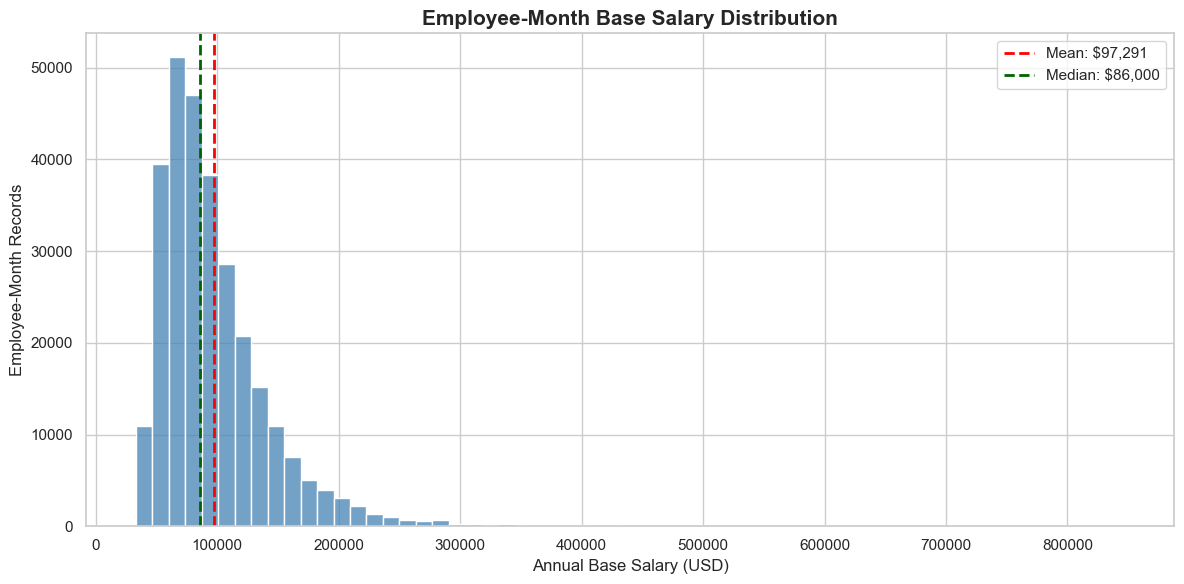

In [13]:

# ============================================================
# PHASE 5 | STEP 24
# Employee Salary Distribution Analysis
# ============================================================

# 1. Import Visualization Libraries
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Configure Visualization Style
sns.set_theme(style="whitegrid")

# 3. Create Salary Distribution
fig, ax = plt.subplots(figsize=(12, 6))

sns.histplot(
    data=df_analysis,
    x="base_salary",
    bins=60,
    color="steelblue",
    edgecolor="white",
    ax=ax
)

# 4. Add Mean and Median Reference Lines
mean_salary = df_analysis["base_salary"].mean()
median_salary = df_analysis["base_salary"].median()

ax.axvline(
    mean_salary,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean: ${mean_salary:,.0f}"
)

ax.axvline(
    median_salary,
    color="darkgreen",
    linestyle="--",
    linewidth=2,
    label=f"Median: ${median_salary:,.0f}"
)

# 5. Add Chart Labels
ax.set_title(
    "Employee-Month Base Salary Distribution",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Annual Base Salary (USD)")
ax.set_ylabel("Employee-Month Records")
ax.legend()

plt.tight_layout()
plt.show()


In [14]:

# ============================================================
# PHASE 5 | STEP 25
# Salary Distribution and Outlier Analysis by Job Level
# ============================================================

# 1. Calculate Salary Statistics by Job Level
salary_by_level = (
    df_analysis
    .groupby("job_level")
    .agg(
        records=("base_salary", "size"),
        mean_salary=("base_salary", "mean"),
        median_salary=("base_salary", "median"),
        min_salary=("base_salary", "min"),
        max_salary=("base_salary", "max"),
        p95_salary=("base_salary", lambda x: x.quantile(0.95))
    )
    .sort_index()
)

# 2. Calculate Mean-to-Median Ratio
salary_by_level["mean_median_ratio"] = (
    salary_by_level["mean_salary"]
    / salary_by_level["median_salary"]
)

# 3. Display Salary Statistics
print("=== SALARY DISTRIBUTION BY JOB LEVEL ===")
display(salary_by_level.round(2))

# 4. Examine the Highest Salary Records
print("\n=== TOP 10 HIGHEST SALARY RECORDS ===")

display(
    df_analysis[
        ["employee_id", "month_date", "job_level", "base_salary"]
    ]
    .nlargest(10, "base_salary")
)


=== SALARY DISTRIBUTION BY JOB LEVEL ===


,records,mean_salary,median_salary,min_salary,max_salary,p95_salary,mean_median_ratio
job_level,,,,,,,
L1,70404,62575.31,58970.0,32950.0,128280.0,96260.0,1.06
L2,93512,81609.78,77030.0,41490.0,177000.0,126260.0,1.06
L3,79210,108425.92,102260.0,53620.0,223650.0,169835.0,1.06
L4,30042,139064.43,130980.0,70560.0,286770.0,212000.0,1.06
L5,12040,177305.72,164110.0,92600.0,338680.0,279800.0,1.08
L6,4295,245953.48,227220.0,132360.0,455610.0,394420.0,1.08
L7,451,384039.31,373330.0,289710.0,472150.0,458540.0,1.03
L8,60,800651.50,812110.0,736670.0,847040.0,847040.0,0.99



=== TOP 10 HIGHEST SALARY RECORDS ===


,employee_id,month_date,job_level,base_salary
4546,EMP000001,2025-12-01,L8,847040.0
234259,EMP000001,2025-04-01,L8,847040.0
238746,EMP000001,2025-05-01,L8,847040.0
243282,EMP000001,2025-06-01,L8,847040.0
247821,EMP000001,2025-07-01,L8,847040.0
252398,EMP000001,2025-08-01,L8,847040.0
256985,EMP000001,2025-09-01,L8,847040.0
261579,EMP000001,2025-10-01,L8,847040.0
266140,EMP000001,2025-11-01,L8,847040.0
180136,EMP000001,2024-04-01,L8,836860.0


In [15]:

# ============================================================
# PHASE 5 | STEP 26
# Employee-Level Salary Distribution
# ============================================================

# 1. Select the Latest Available Record per Employee
latest_employee_records = (
    df_analysis
    .sort_values(["employee_id", "month_date"])
    .drop_duplicates(subset="employee_id", keep="last")
    .copy()
)

# 2. Verify Employee-Level Dataset
print("=== EMPLOYEE-LEVEL DATASET ===")
print(f"Monthly Records: {len(df_analysis):,}")
print(f"Unique Employees: {len(latest_employee_records):,}")
print(
    "Duplicate Employee IDs:",
    latest_employee_records["employee_id"].duplicated().sum()
)

# 3. Compare Salary Statistics
salary_comparison = pd.DataFrame({
    "Employee-Month Level": [
        df_analysis["base_salary"].mean(),
        df_analysis["base_salary"].median(),
        df_analysis["base_salary"].quantile(0.95),
        df_analysis["base_salary"].max()
    ],
    "Latest Record per Employee": [
        latest_employee_records["base_salary"].mean(),
        latest_employee_records["base_salary"].median(),
        latest_employee_records["base_salary"].quantile(0.95),
        latest_employee_records["base_salary"].max()
    ]
}, index=[
    "Mean Salary",
    "Median Salary",
    "95th Percentile",
    "Maximum Salary"
])

# 4. Display Comparison
print("\n=== SALARY DISTRIBUTION COMPARISON ===")
display(salary_comparison.round(2))

# 5. Count Unique Employees by Job Level
print("\n=== UNIQUE EMPLOYEES BY LATEST JOB LEVEL ===")

display(
    latest_employee_records
    .groupby("job_level")
    .agg(
        unique_employees=("employee_id", "nunique"),
        median_salary=("base_salary", "median")
    )
    .sort_index()
)


=== EMPLOYEE-LEVEL DATASET ===
Monthly Records: 290,014
Unique Employees: 8,430
Duplicate Employee IDs: 0

=== SALARY DISTRIBUTION COMPARISON ===


,Employee-Month Level,Latest Record per Employee
Mean Salary,97290.51,95547.55
Median Salary,86000.00,84100.00
95th Percentile,183750.00,180328.50
Maximum Salary,847040.00,847040.00



=== UNIQUE EMPLOYEES BY LATEST JOB LEVEL ===


,unique_employees,median_salary
job_level,,
L1,2263,58930.0
L2,2719,76870.0
L3,2218,102270.0
L4,789,132590.0
L5,318,168425.0
L6,112,233905.0
L7,10,368095.0
L8,1,847040.0


In [16]:

# ============================================================
# PHASE 5 | STEP 27
# December 2025 Workforce Salary Snapshot
# ============================================================

# 1. Select the Latest Available Month
latest_month = df_analysis["month_date"].max()

monthly_snapshot = df_analysis.loc[
    df_analysis["month_date"] == latest_month
].copy()

# 2. Validate Snapshot
print("=== LATEST MONTHLY WORKFORCE SNAPSHOT ===")
print("Snapshot Date:", latest_month.date())
print("Monthly Records:", f"{len(monthly_snapshot):,}")
print(
    "Unique Employees:",
    f"{monthly_snapshot['employee_id'].nunique():,}"
)

# 3. Calculate Salary Statistics by Job Level
snapshot_salary = (
    monthly_snapshot
    .groupby("job_level")
    .agg(
        employees=("employee_id", "nunique"),
        mean_salary=("base_salary", "mean"),
        median_salary=("base_salary", "median"),
        min_salary=("base_salary", "min"),
        max_salary=("base_salary", "max")
    )
    .sort_index()
)

# 4. Calculate Workforce Composition
snapshot_salary["workforce_share_pct"] = (
    snapshot_salary["employees"]
    / monthly_snapshot["employee_id"].nunique() * 100
)

# 5. Display Results
print("\n=== SALARY AND WORKFORCE COMPOSITION BY JOB LEVEL ===")
display(snapshot_salary.round(2))

# 6. Display Overall Salary Statistics
print("\n=== OVERALL SNAPSHOT SALARY METRICS ===")
print(f"Mean Salary: ${monthly_snapshot['base_salary'].mean():,.2f}")
print(f"Median Salary: ${monthly_snapshot['base_salary'].median():,.2f}")


=== LATEST MONTHLY WORKFORCE SNAPSHOT ===
Snapshot Date: 2025-12-01
Monthly Records: 4,907
Unique Employees: 4,907

=== SALARY AND WORKFORCE COMPOSITION BY JOB LEVEL ===


,employees,mean_salary,median_salary,min_salary,max_salary,workforce_share_pct
job_level,,,,,,
L1,1123,63338.21,59670.0,33900.0,128280.0,22.89
L2,1554,82292.43,77625.0,41490.0,177000.0,31.67
L3,1404,110530.95,103925.0,53670.0,223650.0,28.61
L4,529,139970.32,133010.0,73860.0,286770.0,10.78
L5,217,181708.89,170610.0,102480.0,334040.0,4.42
L6,71,251782.82,239010.0,146470.0,450240.0,1.45
L7,8,404651.25,394220.0,353830.0,472150.0,0.16
L8,1,847040.00,847040.0,847040.0,847040.0,0.02



=== OVERALL SNAPSHOT SALARY METRICS ===
Mean Salary: $99,782.48
Median Salary: $88,580.00


In [17]:

# ============================================================
# PHASE 5 | STEP 28
# December 2025 Headcount Reconciliation
# ============================================================

# 1. Inspect Available Columns
print("=== SNAPSHOT COLUMNS ===")
print(monthly_snapshot.columns.tolist())

# 2. Identify Potential Employment Status Columns
status_columns = [
    col for col in monthly_snapshot.columns
    if "status" in col.lower() or "active" in col.lower()
]

print("\n=== EMPLOYMENT STATUS COLUMNS ===")
print(status_columns)

# 3. Examine Status Distribution
for col in status_columns:
    print(f"\n=== {col.upper()} DISTRIBUTION ===")
    display(
        monthly_snapshot[col]
        .value_counts(dropna=False)
        .rename_axis(col)
        .reset_index(name="records")
    )

# 4. Verify Employee Uniqueness
print("\n=== SNAPSHOT INTEGRITY ===")
print("Total Records:", len(monthly_snapshot))
print("Unique Employees:", monthly_snapshot["employee_id"].nunique())
print(
    "Duplicate Employee IDs:",
    monthly_snapshot["employee_id"].duplicated().sum()
)


=== SNAPSHOT COLUMNS ===
['employee_id', 'month_date', 'year_month', 'department', 'job_family', 'job_role', 'job_level', 'location', 'manager_id', 'employment_status', 'base_salary', 'compa_ratio', 'organizational_tenure_months', 'role_tenure_months', 'months_since_last_promotion', 'latest_performance_rating', 'team_vacancy_rate', 'average_weekly_hours', 'unscheduled_absence_days', 'recent_absence_metric', 'recent_workload_metric', 'year', 'tenure_group']

=== EMPLOYMENT STATUS COLUMNS ===
['employment_status']

=== EMPLOYMENT_STATUS DISTRIBUTION ===


,employment_status,records
0,Active,4867
1,Terminated,40



=== SNAPSHOT INTEGRITY ===
Total Records: 4907
Unique Employees: 4907
Duplicate Employee IDs: 0


In [131]:

# ============================================================
# PHASE 5 | STEP 29
# Active Workforce Compensation Baseline
# ============================================================

# 1. Filter Active Employees in December 2025
active_snapshot = monthly_snapshot.loc[
    monthly_snapshot["employment_status"] == "Active"
].copy()

# 2. Validate Active Workforce Population
print("=== ACTIVE WORKFORCE VALIDATION ===")
print("Snapshot Date:", latest_month.date())
print("Active Records:", f"{len(active_snapshot):,}")
print("Unique Active Employees:", f"{active_snapshot['employee_id'].nunique():,}")
print("Duplicate Employee IDs:", active_snapshot["employee_id"].duplicated().sum())

# 3. Calculate Overall Compensation Metrics
print("\n=== ACTIVE WORKFORCE COMPENSATION METRICS ===")
print(f"Mean Salary: ${active_snapshot['base_salary'].mean():,.2f}")
print(f"Median Salary: ${active_snapshot['base_salary'].median():,.2f}")
print(f"Total Annualized Base Salary: ${active_snapshot['base_salary'].sum():,.2f}")
print(f"Mean Compa-Ratio: {active_snapshot['compa_ratio'].mean():.4f}")

# 4. Calculate Compensation by Job Level
active_salary_by_level = (
    active_snapshot
    .groupby("job_level")
    .agg(
        employees=("employee_id", "nunique"),
        mean_salary=("base_salary", "mean"),
        median_salary=("base_salary", "median"),
        total_annualized_salary=("base_salary", "sum"),
        mean_compa_ratio=("compa_ratio", "mean")
    )
    .sort_index()
)

# 5. Calculate Workforce Share
active_salary_by_level["workforce_share_pct"] = (
    active_salary_by_level["employees"]
    / len(active_snapshot) * 100
)

# 6. Display Results
print("\n=== ACTIVE WORKFORCE COMPENSATION BY JOB LEVEL ===")
display(active_salary_by_level.round(2))


=== ACTIVE WORKFORCE VALIDATION ===
Snapshot Date: 2025-12-01
Active Records: 4,867
Unique Active Employees: 4,867
Duplicate Employee IDs: 0

=== ACTIVE WORKFORCE COMPENSATION METRICS ===
Mean Salary: $99,860.80
Median Salary: $88,600.00
Total Annualized Base Salary: $486,022,500.00
Mean Compa-Ratio: 1.0192

=== ACTIVE WORKFORCE COMPENSATION BY JOB LEVEL ===


,employees,mean_salary,median_salary,total_annualized_salary,mean_compa_ratio,workforce_share_pct
job_level,,,,,,
L1,1107,63409.84,59810.0,70194690.0,1.00,22.75
L2,1541,82185.24,77560.0,126647450.0,1.01,31.66
L3,1396,110474.96,103860.0,154223050.0,1.03,28.68
L4,527,139900.42,133010.0,73727520.0,1.04,10.83
L5,216,181800.74,170820.0,39268960.0,1.04,4.44
L6,71,251782.82,239010.0,17876580.0,1.07,1.46
L7,8,404651.25,394220.0,3237210.0,1.14,0.16
L8,1,847040.00,847040.0,847040.0,1.24,0.02


In [18]:

# ============================================================
# PHASE 5 | STEP 30
# Monthly Workforce Compensation Trends
# ============================================================

# 1. Filter Active Employee-Month Records
active_monthly = df_analysis.loc[
    df_analysis["employment_status"] == "Active"
].copy()

# 2. Calculate Monthly Compensation Metrics
monthly_compensation = (
    active_monthly
    .groupby("month_date")
    .agg(
        active_employees=("employee_id", "nunique"),
        mean_salary=("base_salary", "mean"),
        median_salary=("base_salary", "median"),
        total_annualized_salary=("base_salary", "sum"),
        mean_compa_ratio=("compa_ratio", "mean")
    )
    .reset_index()
    .sort_values("month_date")
)

# 3. Calculate Month-over-Month Changes
monthly_compensation["headcount_mom_pct"] = (
    monthly_compensation["active_employees"]
    .pct_change() * 100
)

monthly_compensation["salary_mom_pct"] = (
    monthly_compensation["mean_salary"]
    .pct_change() * 100
)

# 4. Display Summary
print("=== MONTHLY COMPENSATION TREND VALIDATION ===")
print("Months:", len(monthly_compensation))
print("First Month:", monthly_compensation["month_date"].min().date())
print("Last Month:", monthly_compensation["month_date"].max().date())

print("\n=== FIRST FIVE MONTHS ===")
display(monthly_compensation.head().round(2))

print("\n=== LAST FIVE MONTHS ===")
display(monthly_compensation.tail().round(2))


=== MONTHLY COMPENSATION TREND VALIDATION ===
Months: 60
First Month: 2021-01-01
Last Month: 2025-12-01

=== FIRST FIVE MONTHS ===


,month_date,active_employees,mean_salary,median_salary,total_annualized_salary,mean_compa_ratio,headcount_mom_pct,salary_mom_pct
0,2021-01-01,4923,91998.34,81370.0,452907820.0,0.97,NaN,NaN
1,2021-02-01,4856,92080.47,81520.0,447142780.0,0.97,-1.36,0.09
2,2021-03-01,4825,91968.81,81430.0,443749500.0,0.97,-0.64,-0.12
3,2021-04-01,4795,95492.44,84720.0,457886260.0,0.99,-0.62,3.83
4,2021-05-01,4805,95234.88,84510.0,457603590.0,0.99,0.21,-0.27



=== LAST FIVE MONTHS ===


,month_date,active_employees,mean_salary,median_salary,total_annualized_salary,mean_compa_ratio,headcount_mom_pct,salary_mom_pct
55,2025-08-01,4885,100519.21,89340.0,491036350.0,1.02,0.29,-0.33
56,2025-09-01,4869,100412.22,89260.0,488907100.0,1.02,-0.33,-0.11
57,2025-10-01,4873,100167.09,88840.0,488114210.0,1.02,0.08,-0.24
58,2025-11-01,4857,100062.54,88820.0,486003770.0,1.02,-0.33,-0.10
59,2025-12-01,4867,99860.80,88600.0,486022500.0,1.02,0.21,-0.20


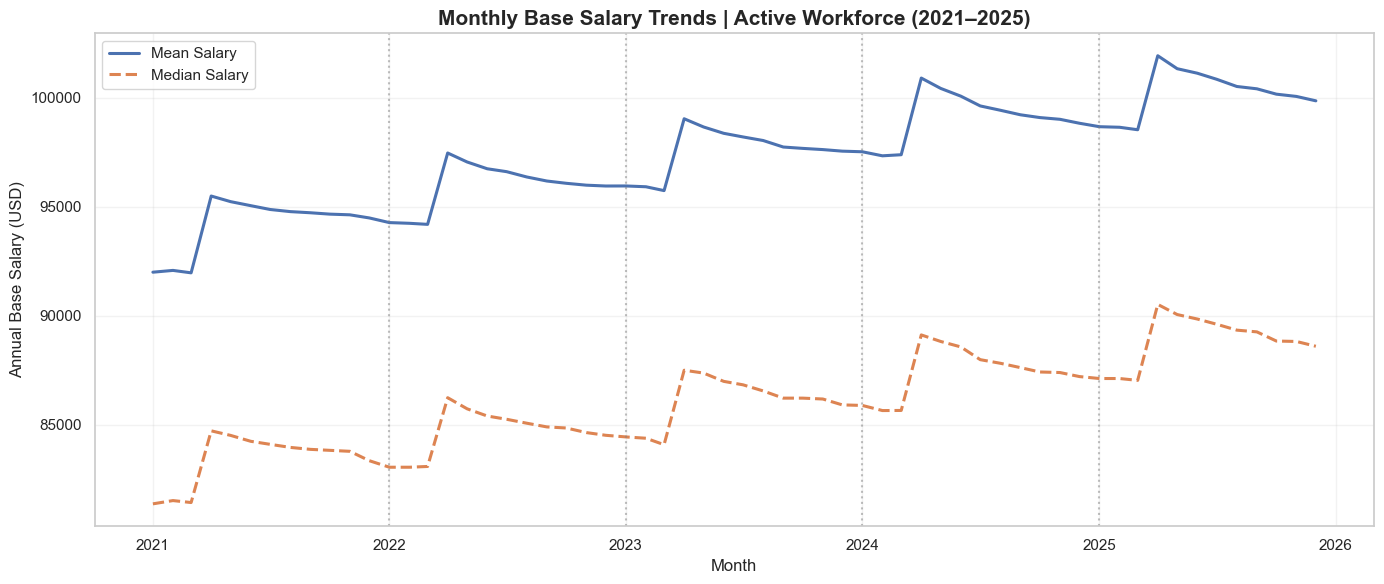

In [19]:

# ============================================================
# PHASE 5 | STEP 31
# Monthly Salary Trends and Annual Adjustment Patterns
# ============================================================

# 1. Create Monthly Salary Trend Chart
fig, ax = plt.subplots(figsize=(14, 6))

# 2. Plot Mean and Median Salaries
ax.plot(
    monthly_compensation["month_date"],
    monthly_compensation["mean_salary"],
    label="Mean Salary",
    linewidth=2.2
)

ax.plot(
    monthly_compensation["month_date"],
    monthly_compensation["median_salary"],
    label="Median Salary",
    linewidth=2.2,
    linestyle="--"
)

# 3. Highlight Year Boundaries
for year in range(2022, 2026):
    ax.axvline(
        pd.Timestamp(f"{year}-01-01"),
        color="gray",
        linestyle=":",
        alpha=0.5
    )

# 4. Format Chart
ax.set_title(
    "Monthly Base Salary Trends | Active Workforce (2021–2025)",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Month")
ax.set_ylabel("Annual Base Salary (USD)")
ax.legend()
ax.grid(alpha=0.25)

# 5. Display Chart
plt.tight_layout()
plt.show()


In [20]:

# ============================================================
# PHASE 5 | STEP 32
# Annual Salary Adjustment Pattern Analysis
# ============================================================

# 1. Prepare Monthly Salary Changes
salary_changes = monthly_compensation[
    ["month_date", "mean_salary", "median_salary", "salary_mom_pct"]
].copy()

# 2. Extract Year and Month
salary_changes["year"] = salary_changes["month_date"].dt.year
salary_changes["month"] = salary_changes["month_date"].dt.month

# 3. Calculate Median Salary Monthly Change
salary_changes["median_mom_pct"] = (
    salary_changes["median_salary"].pct_change() * 100
)

# 4. Create Year-by-Month Comparison Matrix
mean_change_matrix = salary_changes.pivot(
    index="year",
    columns="month",
    values="salary_mom_pct"
)

# 5. Calculate Average Monthly Change Across Years
monthly_pattern = (
    salary_changes
    .groupby("month")
    .agg(
        avg_mean_salary_change_pct=("salary_mom_pct", "mean"),
        avg_median_salary_change_pct=("median_mom_pct", "mean"),
        observations=("salary_mom_pct", "count")
    )
    .reset_index()
)

# 6. Display Results
print("=== MONTH-OVER-MONTH MEAN SALARY CHANGE BY YEAR ===")
display(mean_change_matrix.round(2))

print("\n=== AVERAGE SALARY CHANGE BY CALENDAR MONTH ===")
display(monthly_pattern.round(2))


=== MONTH-OVER-MONTH MEAN SALARY CHANGE BY YEAR ===


month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2021,NaN,0.09,-0.12,3.83,-0.27,-0.19,-0.18,-0.10,-0.06,-0.07,-0.03,-0.15
2022,-0.23,-0.03,-0.05,3.48,-0.42,-0.32,-0.14,-0.25,-0.19,-0.11,-0.09,-0.04
2023,0.00,-0.04,-0.18,3.44,-0.38,-0.29,-0.17,-0.17,-0.30,-0.06,-0.06,-0.07
2024,-0.03,-0.19,0.05,3.61,-0.47,-0.35,-0.45,-0.20,-0.21,-0.13,-0.08,-0.18
2025,-0.16,-0.03,-0.12,3.45,-0.58,-0.20,-0.28,-0.33,-0.11,-0.24,-0.10,-0.20



=== AVERAGE SALARY CHANGE BY CALENDAR MONTH ===


,month,avg_mean_salary_change_pct,avg_median_salary_change_pct,observations
0,1,-0.10,-0.15,4
1,2,-0.04,-0.03,5
2,3,-0.08,-0.10,5
3,4,3.56,3.99,5
4,5,-0.43,-0.37,5
5,6,-0.27,-0.33,5
6,7,-0.24,-0.29,5
7,8,-0.21,-0.24,5
8,9,-0.17,-0.20,5
9,10,-0.12,-0.16,5


In [21]:

# ============================================================
# PHASE 5 | STEP 33
# Same-Employee Monthly Salary Change Analysis
# ============================================================

# 1. Sort Employee-Month Records
employee_salary_panel = (
    active_monthly
    .sort_values(["employee_id", "month_date"])
    .copy()
)

# 2. Retrieve Previous Salary and Month
employee_salary_panel["previous_salary"] = (
    employee_salary_panel
    .groupby("employee_id")["base_salary"]
    .shift(1)
)

employee_salary_panel["previous_month"] = (
    employee_salary_panel
    .groupby("employee_id")["month_date"]
    .shift(1)
)

# 3. Retain Consecutive Month Comparisons
consecutive_month = (
    employee_salary_panel["previous_month"]
    == employee_salary_panel["month_date"]
       - pd.DateOffset(months=1)
)

salary_pairs = employee_salary_panel.loc[
    consecutive_month
].copy()

# 4. Calculate Employee-Level Salary Changes
salary_pairs["salary_change_pct"] = (
    (
        salary_pairs["base_salary"]
        / salary_pairs["previous_salary"]
    ) - 1
) * 100

salary_pairs["salary_increased"] = (
    salary_pairs["base_salary"]
    > salary_pairs["previous_salary"]
)

salary_pairs["salary_decreased"] = (
    salary_pairs["base_salary"]
    < salary_pairs["previous_salary"]
)

# 5. Aggregate by Calendar Month
salary_pairs["calendar_month"] = (
    salary_pairs["month_date"].dt.month
)

same_employee_pattern = (
    salary_pairs
    .groupby("calendar_month")
    .agg(
        employee_month_pairs=("employee_id", "size"),
        mean_change_pct=("salary_change_pct", "mean"),
        median_change_pct=("salary_change_pct", "median"),
        employees_with_increase=("salary_increased", "sum"),
        employees_with_decrease=("salary_decreased", "sum")
    )
    .reset_index()
)

# 6. Calculate Share Receiving Increases
same_employee_pattern["increase_share_pct"] = (
    same_employee_pattern["employees_with_increase"]
    / same_employee_pattern["employee_month_pairs"] * 100
)

# 7. Display Results
print("=== SAME-EMPLOYEE SALARY CHANGE BY CALENDAR MONTH ===")
display(same_employee_pattern.round(2))


=== SAME-EMPLOYEE SALARY CHANGE BY CALENDAR MONTH ===


,calendar_month,employee_month_pairs,mean_change_pct,median_change_pct,employees_with_increase,employees_with_decrease,increase_share_pct
0,1,18743,0.00,0.00,0,0,0.00
1,2,23567,0.00,0.00,0,0,0.00
2,3,23394,0.00,0.00,0,0,0.00
3,4,23364,3.87,3.24,18731,0,80.17
4,5,23376,0.00,0.00,0,0,0.00
5,6,23562,0.00,0.00,0,0,0.00
6,7,23689,0.00,0.00,0,0,0.00
7,8,23733,0.00,0.00,0,0,0.00
8,9,23723,0.00,0.00,0,0,0.00
9,10,23702,0.00,0.00,0,0,0.00


In [22]:

# ============================================================
# PHASE 5 | STEP 34
# Workforce Composition and Salary Change Analysis
# ============================================================

# 1. Prepare Active Employee-Month Records
workforce_panel = active_monthly[
    ["employee_id", "month_date", "base_salary"]
].copy()

workforce_panel = workforce_panel.sort_values(
    ["month_date", "employee_id"]
)

# 2. Compare Consecutive Monthly Workforce Populations
composition_results = []

months = sorted(workforce_panel["month_date"].unique())

for i in range(1, len(months)):

    previous = workforce_panel[
        workforce_panel["month_date"] == months[i - 1]
    ].set_index("employee_id")

    current = workforce_panel[
        workforce_panel["month_date"] == months[i]
    ].set_index("employee_id")

    continuing_ids = current.index.intersection(previous.index)
    entering_ids = current.index.difference(previous.index)
    exiting_ids = previous.index.difference(current.index)

    composition_results.append({
        "month_date": months[i],
        "continuing_employees": len(continuing_ids),
        "entering_employees": len(entering_ids),
        "exiting_employees": len(exiting_ids),
        "continuing_mean_salary": current.loc[
            continuing_ids, "base_salary"
        ].mean(),
        "entering_mean_salary": current.loc[
            entering_ids, "base_salary"
        ].mean(),
        "exiting_mean_salary": previous.loc[
            exiting_ids, "base_salary"
        ].mean()
    })

# 3. Create Monthly Composition DataFrame
composition_df = pd.DataFrame(composition_results)

# 4. Display Results for 2025
print("=== WORKFORCE COMPOSITION AND SALARY | 2025 ===")

display(
    composition_df.loc[
        composition_df["month_date"].dt.year == 2025
    ].round(2)
)


=== WORKFORCE COMPOSITION AND SALARY | 2025 ===


,month_date,continuing_employees,entering_employees,exiting_employees,continuing_mean_salary,entering_mean_salary,exiting_mean_salary
47,2025-01-01,4737,47,57,98815.35,84399.57,100267.37
48,2025-02-01,4743,41,41,98802.49,80753.41,83777.80
49,2025-03-01,4695,53,89,98810.89,74029.06,90044.83
50,2025-04-01,4691,66,57,102207.15,82197.27,92384.39
51,2025-05-01,4712,110,45,102093.58,68821.36,84751.11
52,2025-06-01,4775,64,47,101446.79,77360.16,89933.83
53,2025-07-01,4797,74,42,101193.54,78528.65,93668.57
54,2025-08-01,4833,52,38,100790.66,75290.00,108296.05
55,2025-09-01,4841,28,44,100540.36,78258.21,98192.73
56,2025-10-01,4817,56,52,100493.04,72128.93,92925.19


In [23]:

# ============================================================
# PHASE 5 | STEP 35
# Monthly Mean Salary Change Decomposition
# ============================================================

# 1. Prepare Monthly Employee Salary Data
salary_panel = active_monthly[
    ["employee_id", "month_date", "base_salary"]
].copy()

salary_panel = salary_panel.sort_values(
    ["month_date", "employee_id"]
)

# 2. Decompose Monthly Changes
decomposition_results = []

months = sorted(salary_panel["month_date"].unique())

for i in range(1, len(months)):

    previous = salary_panel.loc[
        salary_panel["month_date"] == months[i - 1]
    ].set_index("employee_id")["base_salary"]

    current = salary_panel.loc[
        salary_panel["month_date"] == months[i]
    ].set_index("employee_id")["base_salary"]

    continuing = current.index.intersection(previous.index)
    entering = current.index.difference(previous.index)
    exiting = previous.index.difference(current.index)

    previous_mean = previous.mean()
    current_mean = current.mean()

    # Within-employee salary changes, weighted by current headcount
    within_effect = (
        current.loc[continuing].sum()
        - previous.loc[continuing].sum()
    ) / len(current)

    # Effect of entrants relative to the previous workforce mean
    entry_effect = (
        current.loc[entering].sum()
        - len(entering) * previous_mean
    ) / len(current)

    # Effect of removing leavers relative to the previous workforce mean
    exit_effect = (
        len(exiting) * previous_mean
        - previous.loc[exiting].sum()
    ) / len(current)

    actual_change = current_mean - previous_mean

    decomposition_results.append({
        "month_date": months[i],
        "actual_mean_change": actual_change,
        "within_employee_effect": within_effect,
        "entry_effect": entry_effect,
        "exit_effect": exit_effect,
        "reconstructed_change": (
            within_effect + entry_effect + exit_effect
        )
    })

# 3. Create Decomposition DataFrame
salary_decomposition = pd.DataFrame(decomposition_results)

# 4. Validate Exact Reconciliation
salary_decomposition["reconciliation_error"] = (
    salary_decomposition["actual_mean_change"]
    - salary_decomposition["reconstructed_change"]
)

print("=== DECOMPOSITION VALIDATION ===")
print(
    "Maximum Absolute Reconciliation Error:",
    salary_decomposition["reconciliation_error"].abs().max()
)

# 5. Display 2025 Results
print("\n=== MONTHLY SALARY CHANGE DECOMPOSITION | 2025 ===")

display(
    salary_decomposition.loc[
        salary_decomposition["month_date"].dt.year == 2025
    ].round(2)
)


=== DECOMPOSITION VALIDATION ===
Maximum Absolute Reconciliation Error: 1.290345608140342e-11

=== MONTHLY SALARY CHANGE DECOMPOSITION | 2025 ===


,month_date,actual_mean_change,within_employee_effect,entry_effect,exit_effect,reconstructed_change,reconciliation_error
47,2025-01-01,-158.89,0.00,-141.80,-17.09,-158.89,-0.0
48,2025-02-01,-25.92,0.00,-153.58,127.66,-25.92,0.0
49,2025-03-01,-113.55,0.00,-274.81,161.26,-113.55,-0.0
50,2025-04-01,3395.27,3548.24,-226.66,73.69,3395.27,0.0
51,2025-05-01,-594.95,0.00,-755.27,160.31,-594.95,0.0
52,2025-06-01,-206.35,0.00,-317.08,110.73,-206.35,-0.0
53,2025-07-01,-279.01,0.00,-343.33,64.32,-279.01,0.0
54,2025-08-01,-330.00,0.00,-272.07,-57.93,-330.00,-0.0
55,2025-09-01,-106.99,0.00,-128.02,21.02,-106.99,-0.0
56,2025-10-01,-245.13,0.00,-325.03,79.89,-245.13,-0.0


In [24]:

# ============================================================
# PHASE 5 | STEP 36
# Validate Annual Employee Salary Adjustment Cycle
# ============================================================

# 1. Extract Year and Month from Salary Comparison Records
salary_pairs["year"] = salary_pairs["month_date"].dt.year
salary_pairs["month"] = salary_pairs["month_date"].dt.month

# 2. Calculate Employee Salary Changes by Year and Month
annual_adjustment_pattern = (
    salary_pairs
    .groupby(["year", "month"])
    .agg(
        employee_pairs=("employee_id", "size"),
        employees_with_increase=("salary_increased", "sum"),
        employees_with_decrease=("salary_decreased", "sum"),
        mean_change_pct=("salary_change_pct", "mean"),
        median_change_pct=("salary_change_pct", "median")
    )
    .reset_index()
)

# 3. Calculate Share of Employees Receiving Salary Increases
annual_adjustment_pattern["increase_share_pct"] = (
    annual_adjustment_pattern["employees_with_increase"]
    / annual_adjustment_pattern["employee_pairs"] * 100
)

# 4. Summarize April Adjustments by Year
april_adjustments = annual_adjustment_pattern.loc[
    annual_adjustment_pattern["month"] == 4
].copy()

# 5. Verify Salary Changes Outside April
outside_april = annual_adjustment_pattern.loc[
    annual_adjustment_pattern["month"] != 4
]

print("=== APRIL SALARY ADJUSTMENTS BY YEAR ===")
display(april_adjustments.round(2))

print("\n=== SALARY CHANGES OUTSIDE APRIL ===")
print(
    "Total Increases:",
    outside_april["employees_with_increase"].sum()
)
print(
    "Total Decreases:",
    outside_april["employees_with_decrease"].sum()
)


=== APRIL SALARY ADJUSTMENTS BY YEAR ===


,year,month,employee_pairs,employees_with_increase,employees_with_decrease,mean_change_pct,median_change_pct,increase_share_pct
2,2021,4,4763,3882,0,3.78,3.30,81.50
14,2022,4,4609,3692,0,3.95,3.31,80.10
26,2023,4,4651,3703,0,3.83,3.20,79.62
38,2024,4,4650,3746,0,3.94,3.16,80.56
50,2025,4,4691,3708,0,3.83,3.17,79.04



=== SALARY CHANGES OUTSIDE APRIL ===
Total Increases: 0
Total Decreases: 0


In [25]:

# ============================================================
# PHASE 5 | STEP 37
# Annual Salary Increase Analysis by Job Level
# ============================================================

# 1. Select April Employee Salary Comparisons
april_salary_pairs = salary_pairs.loc[
    salary_pairs["month_date"].dt.month == 4
].copy()

# 2. Calculate Salary Adjustment Metrics by Job Level
level_adjustments = (
    april_salary_pairs
    .groupby("job_level")
    .agg(
        employee_year_pairs=("employee_id", "size"),
        employees_with_increase=("salary_increased", "sum"),
        mean_change_all_pct=("salary_change_pct", "mean"),
        median_change_all_pct=("salary_change_pct", "median")
    )
)

# 3. Calculate Mean Increase for Raise Recipients Only
recipient_increases = (
    april_salary_pairs.loc[
        april_salary_pairs["salary_increased"]
    ]
    .groupby("job_level")["salary_change_pct"]
    .mean()
)

level_adjustments["mean_raise_recipients_pct"] = (
    recipient_increases
)

# 4. Calculate Share Receiving an Increase
level_adjustments["increase_share_pct"] = (
    level_adjustments["employees_with_increase"]
    / level_adjustments["employee_year_pairs"] * 100
)

# 5. Display Results
print("=== APRIL SALARY ADJUSTMENTS BY JOB LEVEL | 2021–2025 ===")
display(level_adjustments.round(2))


=== APRIL SALARY ADJUSTMENTS BY JOB LEVEL | 2021–2025 ===


,employee_year_pairs,employees_with_increase,mean_change_all_pct,median_change_all_pct,mean_raise_recipients_pct,increase_share_pct
job_level,,,,,,
L1,5149,3473,2.42,2.34,3.59,67.45
L2,7606,6237,4.22,3.43,5.15,82.00
L3,6663,5661,4.37,3.42,5.14,84.96
L4,2518,2128,4.29,3.41,5.08,84.51
L5,1024,882,4.31,3.49,5.01,86.13
L6,363,311,3.67,3.23,4.28,85.67
L7,36,34,2.94,2.72,3.11,94.44
L8,5,5,2.84,3.05,2.84,100.00


In [26]:

# ============================================================
# PHASE 5 | STEP 38
# Annual Salary Increase Patterns by Employee Tenure
# ============================================================

# 1. Define Employee Tenure Groups
tenure_bins = [-1, 5, 11, 23, 59, float("inf")]

tenure_labels = [
    "0–5 months",
    "6–11 months",
    "12–23 months",
    "24–59 months",
    "60+ months"
]

# 2. Assign Tenure Groups to April Salary Comparisons
april_salary_pairs["tenure_group"] = pd.cut(
    april_salary_pairs["organizational_tenure_months"],
    bins=tenure_bins,
    labels=tenure_labels
)

# 3. Calculate Salary Increase Metrics by Tenure
tenure_raise_analysis = (
    april_salary_pairs
    .groupby("tenure_group", observed=True)
    .agg(
        employee_year_pairs=("employee_id", "size"),
        employees_with_increase=("salary_increased", "sum"),
        mean_change_all_pct=("salary_change_pct", "mean")
    )
)

# 4. Calculate Raise Participation Rate
tenure_raise_analysis["increase_share_pct"] = (
    tenure_raise_analysis["employees_with_increase"]
    / tenure_raise_analysis["employee_year_pairs"] * 100
)

# 5. Calculate Average Raise Among Recipients
recipient_raise_by_tenure = (
    april_salary_pairs.loc[
        april_salary_pairs["salary_increased"]
    ]
    .groupby("tenure_group", observed=True)["salary_change_pct"]
    .mean()
)

tenure_raise_analysis["mean_raise_recipients_pct"] = (
    recipient_raise_by_tenure
)

# 6. Display Results
print("=== APRIL SALARY INCREASES BY EMPLOYEE TENURE ===")
display(tenure_raise_analysis.round(2))


=== APRIL SALARY INCREASES BY EMPLOYEE TENURE ===


,employee_year_pairs,employees_with_increase,mean_change_all_pct,increase_share_pct,mean_raise_recipients_pct
tenure_group,,,,,
0–5 months,888,0,0.00,0.00,NaN
6–11 months,1567,339,0.88,21.63,4.07
12–23 months,2739,2417,4.82,88.24,5.47
24–59 months,7068,6315,4.91,89.35,5.50
60+ months,11102,9660,3.70,87.01,4.25


In [27]:

# ============================================================
# PHASE 5 | STEP 39
# Salary Raise Participation by Job Level and Tenure
# ============================================================

# 1. Calculate Raise Participation by Job Level and Tenure
level_tenure_raises = (
    april_salary_pairs
    .groupby(
        ["job_level", "tenure_group"],
        observed=True
    )
    .agg(
        employee_year_pairs=("employee_id", "size"),
        employees_with_increase=("salary_increased", "sum")
    )
    .reset_index()
)

# 2. Calculate Raise Participation Percentage
level_tenure_raises["increase_share_pct"] = (
    level_tenure_raises["employees_with_increase"]
    / level_tenure_raises["employee_year_pairs"] * 100
)

# 3. Create Raise Participation Matrix
raise_rate_matrix = level_tenure_raises.pivot(
    index="job_level",
    columns="tenure_group",
    values="increase_share_pct"
)

# 4. Create Observation Count Matrix
raise_count_matrix = level_tenure_raises.pivot(
    index="job_level",
    columns="tenure_group",
    values="employee_year_pairs"
)

# 5. Display Results
print("=== RAISE PARTICIPATION RATE BY JOB LEVEL AND TENURE ===")
display(raise_rate_matrix.round(2))

print("\n=== EMPLOYEE-YEAR COMPARISONS BY JOB LEVEL AND TENURE ===")
display(raise_count_matrix)


=== RAISE PARTICIPATION RATE BY JOB LEVEL AND TENURE ===


tenure_group,0–5 months,6–11 months,12–23 months,24–59 months,60+ months
job_level,,,,,
L1,0.0,22.70,85.80,84.22,83.06
L2,0.0,23.16,91.01,90.26,87.10
L3,0.0,16.04,89.53,92.34,87.57
L4,0.0,14.00,85.85,92.52,86.46
L5,0.0,20.00,85.19,92.79,87.78
L6,0.0,0.00,100.00,96.15,88.42
L7,NaN,50.00,100.00,0.00,100.00
L8,NaN,NaN,NaN,NaN,100.00



=== EMPLOYEE-YEAR COMPARISONS BY JOB LEVEL AND TENURE ===


tenure_group,0–5 months,6–11 months,12–23 months,24–59 months,60+ months
job_level,,,,,
L1,419.0,846.0,1218.0,1869.0,797.0
L2,255.0,462.0,945.0,2937.0,3007.0
L3,147.0,187.0,430.0,1683.0,4216.0
L4,45.0,50.0,106.0,441.0,1876.0
L5,17.0,10.0,27.0,111.0,859.0
L6,5.0,10.0,11.0,26.0,311.0
L7,NaN,2.0,2.0,1.0,31.0
L8,NaN,NaN,NaN,NaN,5.0


In [28]:

# ============================================================
# PHASE 5 | STEP 40
# Prior Performance Rating and Annual Salary Increases
# ============================================================

# 1. Select March Performance Ratings
march_ratings = active_monthly.loc[
    active_monthly["month_date"].dt.month == 3,
    ["employee_id", "year", "latest_performance_rating"]
].copy()

march_ratings = march_ratings.rename(
    columns={
        "latest_performance_rating": "prior_performance_rating"
    }
)

# 2. Attach Prior Ratings to April Salary Comparisons
april_performance = april_salary_pairs.merge(
    march_ratings,
    on=["employee_id", "year"],
    how="left",
    validate="one_to_one"
)

# 3. Calculate Rating Coverage
print("=== PRIOR PERFORMANCE RATING COVERAGE ===")
print("April Comparisons:", f"{len(april_performance):,}")
print(
    "Available Prior Ratings:",
    f"{april_performance['prior_performance_rating'].notna().sum():,}"
)
print(
    "Missing Prior Ratings:",
    f"{april_performance['prior_performance_rating'].isna().sum():,}"
)

# 4. Calculate Salary Increase Metrics by Performance Rating
performance_raise_analysis = (
    april_performance
    .groupby("prior_performance_rating", dropna=False)
    .agg(
        employee_year_pairs=("employee_id", "size"),
        employees_with_increase=("salary_increased", "sum"),
        mean_change_all_pct=("salary_change_pct", "mean")
    )
)

# 5. Calculate Raise Participation Rate
performance_raise_analysis["increase_share_pct"] = (
    performance_raise_analysis["employees_with_increase"]
    / performance_raise_analysis["employee_year_pairs"] * 100
)

# 6. Calculate Mean Raise Among Recipients
recipient_raises = (
    april_performance.loc[
        april_performance["salary_increased"]
    ]
    .groupby("prior_performance_rating", dropna=False)[
        "salary_change_pct"
    ]
    .mean()
)

performance_raise_analysis["mean_raise_recipients_pct"] = (
    recipient_raises
)

# 7. Display Results
print("\n=== SALARY INCREASES BY PRIOR PERFORMANCE RATING ===")
display(performance_raise_analysis.round(2))


=== PRIOR PERFORMANCE RATING COVERAGE ===
April Comparisons: 23,364
Available Prior Ratings: 21,296
Missing Prior Ratings: 2,068

=== SALARY INCREASES BY PRIOR PERFORMANCE RATING ===


,employee_year_pairs,employees_with_increase,mean_change_all_pct,increase_share_pct,mean_raise_recipients_pct
prior_performance_rating,,,,,
1.0,1082,0,0.00,0.00,NaN
2.0,4392,3221,1.33,73.34,1.81
3.0,10502,10300,4.42,98.08,4.50
4.0,4332,4252,6.71,98.15,6.84
5.0,988,958,9.19,96.96,9.47
NaN,2068,0,0.00,0.00,NaN


In [29]:

# ============================================================
# PHASE 5 | STEP 41
# Performance-Based Salary Raises by Employee Tenure
# ============================================================

# 1. Define Tenure Categories
tenure_bins = [-1, 5, 11, 23, 59, float("inf")]

tenure_labels = [
    "0–5 months",
    "6–11 months",
    "12–23 months",
    "24–59 months",
    "60+ months"
]

# 2. Add Tenure Groups
april_performance["tenure_group"] = pd.cut(
    april_performance["organizational_tenure_months"],
    bins=tenure_bins,
    labels=tenure_labels
)

# 3. Calculate Raise Participation by Performance and Tenure
performance_tenure_analysis = (
    april_performance
    .groupby(
        ["tenure_group", "prior_performance_rating"],
        observed=True,
        dropna=False
    )
    .agg(
        employee_year_pairs=("employee_id", "size"),
        employees_with_increase=("salary_increased", "sum"),
        mean_salary_change_pct=("salary_change_pct", "mean")
    )
    .reset_index()
)

# 4. Calculate Raise Participation Percentage
performance_tenure_analysis["increase_share_pct"] = (
    performance_tenure_analysis["employees_with_increase"]
    / performance_tenure_analysis["employee_year_pairs"] * 100
)

# 5. Display Detailed Results
print("=== PERFORMANCE, TENURE, AND SALARY INCREASES ===")
display(
    performance_tenure_analysis.round(2)
    .sort_values(["tenure_group", "prior_performance_rating"])
)


=== PERFORMANCE, TENURE, AND SALARY INCREASES ===


,tenure_group,prior_performance_rating,employee_year_pairs,employees_with_increase,mean_salary_change_pct,increase_share_pct
0,0–5 months,NaN,888,0,0.00,0.00
1,6–11 months,1.0,23,0,0.00,0.00
2,6–11 months,2.0,88,63,1.39,71.59
3,6–11 months,3.0,193,193,3.94,100.00
4,6–11 months,4.0,67,67,5.66,100.00
5,6–11 months,5.0,16,16,7.47,100.00
6,6–11 months,NaN,1180,0,0.00,0.00
7,12–23 months,1.0,166,0,0.00,0.00
8,12–23 months,2.0,595,444,1.47,74.62
9,12–23 months,3.0,1340,1336,5.22,99.70


In [30]:

# ============================================================
# PHASE 5 | STEP 42
# Performance-Based Salary Raises by Job Level
# ============================================================

# 1. Select Employees with 12+ Months of Service
eligible_performance = april_performance.loc[
    (april_performance["organizational_tenure_months"] >= 12)
    & (april_performance["prior_performance_rating"].between(2, 5))
].copy()

# 2. Calculate Salary Increase Statistics
level_performance_analysis = (
    eligible_performance
    .groupby(["job_level", "prior_performance_rating"])
    .agg(
        employee_year_pairs=("employee_id", "size"),
        employees_with_increase=("salary_increased", "sum"),
        mean_change_pct=("salary_change_pct", "mean")
    )
    .reset_index()
)

# 3. Calculate Raise Participation
level_performance_analysis["increase_share_pct"] = (
    level_performance_analysis["employees_with_increase"]
    / level_performance_analysis["employee_year_pairs"] * 100
)

# 4. Create Mean Salary Change Matrix
mean_raise_matrix = level_performance_analysis.pivot(
    index="job_level",
    columns="prior_performance_rating",
    values="mean_change_pct"
)

# 5. Create Observation Count Matrix
observation_matrix = level_performance_analysis.pivot(
    index="job_level",
    columns="prior_performance_rating",
    values="employee_year_pairs"
)

# 6. Display Results
print("=== MEAN SALARY CHANGE BY JOB LEVEL AND PERFORMANCE ===")
display(mean_raise_matrix.round(2))

print("\n=== EMPLOYEE-YEAR COMPARISONS BY JOB LEVEL AND PERFORMANCE ===")
display(observation_matrix)


=== MEAN SALARY CHANGE BY JOB LEVEL AND PERFORMANCE ===


prior_performance_rating,2.0,3.0,4.0,5.0
job_level,,,,
L1,1.33,3.55,5.20,7.11
L2,1.38,4.91,7.07,9.17
L3,1.30,4.48,7.03,9.57
L4,1.22,4.33,6.76,9.99
L5,1.31,4.42,7.12,9.82
L6,1.19,3.80,5.57,6.48
L7,1.27,2.59,4.16,7.02
L8,NaN,2.60,2.13,4.72



=== EMPLOYEE-YEAR COMPARISONS BY JOB LEVEL AND PERFORMANCE ===


prior_performance_rating,2.0,3.0,4.0,5.0
job_level,,,,
L1,1093.0,1848.0,581.0,91.0
L2,1373.0,3494.0,1401.0,296.0
L3,1115.0,3135.0,1441.0,349.0
L4,456.0,1144.0,551.0,156.0
L5,201.0,490.0,205.0,53.0
L6,57.0,182.0,76.0,23.0
L7,9.0,14.0,8.0,3.0
L8,NaN,2.0,2.0,1.0


In [31]:

# ============================================================
# PHASE 5 | STEP 43
# Multivariable Regression of Annual Salary Changes
# ============================================================

# 1. Import Statistical Modeling Library
import statsmodels.formula.api as smf

# 2. Prepare Regression Dataset
regression_df = april_performance.loc[
    april_performance["job_level"].isin(
        ["L1", "L2", "L3", "L4", "L5"]
    )
    & april_performance["prior_performance_rating"].notna()
    & (april_performance["organizational_tenure_months"] >= 12)
].copy()

# 3. Convert Year to Categorical Variable
regression_df["year"] = regression_df["year"].astype("category")

# 4. Fit OLS Regression with Employee-Clustered Standard Errors
salary_model = smf.ols(
    formula=(
        "salary_change_pct ~ "
        "C(prior_performance_rating) + "
        "C(job_level) + "
        "C(tenure_group) + "
        "C(year)"
    ),
    data=regression_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": regression_df["employee_id"]
    }
)

# 5. Display Regression Summary
print("=== MULTIVARIABLE SALARY INCREASE REGRESSION ===")
print("Observations:", f"{len(regression_df):,}")
print("Unique Employees:", f"{regression_df['employee_id'].nunique():,}")

print(salary_model.summary())


=== MULTIVARIABLE SALARY INCREASE REGRESSION ===
Observations: 20,522
Unique Employees: 6,193
                            OLS Regression Results                            
Dep. Variable:      salary_change_pct   R-squared:                       0.364
Model:                            OLS   Adj. R-squared:                  0.363
Method:                 Least Squares   F-statistic:                 1.408e-13
Date:                Tue, 13 Oct 2026   Prob (F-statistic):               1.00
Time:                        21:02:07   Log-Likelihood:                -53029.
No. Observations:               20522   AIC:                         1.061e+05
Df Residuals:                   20507   BIC:                         1.062e+05
Df Model:                          14                                         
Covariance Type:              cluster                                         
                                         coef    std err          z      P>|z|      [0.025      0.975]
-------------

c:\Users\azzaw\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\base\model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 16, but rank is 1
  warnings.warn('covariance of constraints does not have full '
c:\Users\azzaw\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\regression\linear_model.py:1884: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(np.diag(self.cov_params()))


In [ ]:
# ============================================================
# PHASE 5 | STEP 44
# Correct Regression Specification and Validate Model
# Efficient Matrix Construction (Without Patsy)
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

# 1. Preserve the complete regression dataset for downstream steps.
regression_clean = regression_df.copy().reset_index(drop=True)

required_columns = [
    "salary_change_pct",
    "employee_id",
    "prior_performance_rating",
    "job_level",
    "tenure_group",
    "year"
]

# Stop if incomplete records would make the outcome, predictors, and
# cluster groups inconsistent during estimation.
missing_counts = regression_clean[required_columns].isna().sum()
if missing_counts.any():
    raise ValueError(
        "Step 44 contains missing regression values:\n"
        + missing_counts[missing_counts > 0].to_string()
    )

# Retain categorical dtypes used by later notebook steps.
regression_clean["tenure_group"] = (
    regression_clean["tenure_group"]
    .astype("category")
    .cat.remove_unused_categories()
)
regression_clean["year"] = (
    regression_clean["year"]
    .astype("category")
    .cat.remove_unused_categories()
)


model_features = [
    ("prior_performance_rating", 1, "Rating"),
    ("job_level", "L1", "JobLevel"),
    ("tenure_group", "12–23 months", "Tenure"),
    ("year", 2021, "Year")
]

feature_matrices = []
for col, reference, prefix in model_features:
    series = regression_clean[col]
    if col in ("prior_performance_rating", "year"):
        series = pd.to_numeric(series)

    observed = list(pd.unique(series))
    if reference not in observed:
        raise ValueError(
            f"Step 44 reference category {reference!r} not found in {col}. "
            f"Observed: {observed}"
        )

    # Reference always appears first, so drop_first=True excludes it.
    if isinstance(regression_clean[col].dtype, pd.CategoricalDtype):
        category_order = [
            value for value in regression_clean[col].cat.categories
            if value in observed and value != reference
        ]
    else:
        category_order = sorted(v for v in observed if v != reference)
    ordered_categories = [reference] + category_order

    encoded = pd.Categorical(series, categories=ordered_categories)
    if pd.isna(encoded).any():
        raise ValueError(f"Step 44 could not encode some values in {col}.")

    dummies = pd.get_dummies(
        encoded,
        prefix=prefix,
        drop_first=True,
        dtype=float
    )
    feature_matrices.append(dummies)

X = pd.concat(feature_matrices, axis=1)
X = sm.add_constant(X, has_constant="add")
y = pd.to_numeric(regression_clean["salary_change_pct"]).astype(float)

# 3. Validate design matrix before fitting.
matrix_rank = int(np.linalg.matrix_rank(X.to_numpy()))
full_rank = matrix_rank == X.shape[1]
if not full_rank:
    raise ValueError("Step 44 design matrix is rank-deficient.")

# 4. Fit the same OLS specification with employee-clustered standard errors.
salary_model_corrected = sm.OLS(y, X).fit(
    cov_type="cluster",
    cov_kwds={"groups": regression_clean["employee_id"]}
)

# 5. Print one consolidated validation and regression output.
report = [
    "=" * 80,
    "PHASE 5 | STEP 44 — CORRECTED MULTIVARIABLE SALARY REGRESSION",
    "=" * 80,
    f"Observations: {int(salary_model_corrected.nobs):,}",
    f"Unique Employees: {regression_clean['employee_id'].nunique():,}",
    f"Design Matrix Columns: {X.shape[1]}",
    f"Design Matrix Rank: {matrix_rank}",
    f"Full Column Rank: {full_rank}",
    f"Condition Number: {np.linalg.cond(X.to_numpy()):.2f}",
    "Reference Categories: Rating=1, Job Level=L1, "
    "Tenure=12–23 months, Year=2021",
    "Method: OLS with employee-clustered standard errors",
    "",
    salary_model_corrected.summary().as_text(),
    "=" * 80
]
print("\n".join(report))


PHASE 5 | STEP 44 — CORRECTED MULTIVARIABLE SALARY REGRESSION
Observations: 20,522
Unique Employees: 6,193
Design Matrix Columns: 15
Design Matrix Rank: 15
Full Column Rank: True
Condition Number: 15.15
Reference Categories: Rating=1, Job Level=L1, Tenure=12–23 months, Year=2021
Method: OLS with employee-clustered standard errors

                            OLS Regression Results                            
Dep. Variable:      salary_change_pct   R-squared:                       0.364
Model:                            OLS   Adj. R-squared:                  0.363
Method:                 Least Squares   F-statistic:                     1110.
Date:                Tue, 13 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:02:11   Log-Likelihood:                -53029.
No. Observations:               20522   AIC:                         1.061e+05
Df Residuals:                   20507   BIC:                         1.062e+05
Df Model:                          

In [33]:

# ============================================================
# PHASE 5 | STEP 45
# Regression of Salary Increase Amount Among Raise Recipients
# ============================================================

# 1. Select Employees Who Received a Salary Increase
raise_recipients_df = regression_clean.loc[
    regression_clean["salary_change_pct"] > 0
].copy()

# 2. Remove Unused Categorical Levels
for col in ["tenure_group", "year"]:
    raise_recipients_df[col] = (
        raise_recipients_df[col]
        .cat.remove_unused_categories()
    )

# 3. Fit OLS Model for Raise Amount
raise_amount_model = smf.ols(
    formula=(
        "salary_change_pct ~ "
        "C(prior_performance_rating, Treatment(reference=2)) + "
        "C(job_level, Treatment(reference='L1')) + "
        "C(tenure_group, Treatment(reference='12–23 months')) + "
        "C(year, Treatment(reference=2021))"
    ),
    data=raise_recipients_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": raise_recipients_df["employee_id"]
    }
)

# 4. Validate Model Design
design_matrix = raise_amount_model.model.exog

print("=== RAISE AMOUNT MODEL VALIDATION ===")
print("Observations:", f"{len(raise_recipients_df):,}")
print(
    "Unique Employees:",
    f"{raise_recipients_df['employee_id'].nunique():,}"
)
print(
    "Full Column Rank:",
    np.linalg.matrix_rank(design_matrix) == design_matrix.shape[1]
)
print("Condition Number:", f"{np.linalg.cond(design_matrix):.2f}")

# 5. Display Model Results
print("\n=== RAISE AMOUNT REGRESSION | RECIPIENTS ONLY ===")
print(raise_amount_model.summary())


=== RAISE AMOUNT MODEL VALIDATION ===
Observations: 18,043
Unique Employees: 5,802
Full Column Rank: True
Condition Number: 9.70

=== RAISE AMOUNT REGRESSION | RECIPIENTS ONLY ===
                            OLS Regression Results                            
Dep. Variable:      salary_change_pct   R-squared:                       0.293
Model:                            OLS   Adj. R-squared:                  0.292
Method:                 Least Squares   F-statistic:                     797.1
Date:                Tue, 13 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:02:18   Log-Likelihood:                -47225.
No. Observations:               18043   AIC:                         9.448e+04
Df Residuals:                   18029   BIC:                         9.459e+04
Df Model:                          13                                         
Covariance Type:              cluster                                         
                              

In [34]:

# ============================================================
# PHASE 5 | STEP 46
# Salary Raise Distribution and Extreme Value Diagnostics
# ============================================================

# 1. Calculate Distribution Statistics
raise_distribution = (
    raise_recipients_df["salary_change_pct"]
    .describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
)

print("=== SALARY RAISE DISTRIBUTION ===")
display(raise_distribution.to_frame(name="raise_pct").round(2))

# 2. Examine High Salary Increases
print("\n=== HIGH RAISE FREQUENCY ===")

for threshold in [10, 15, 20, 25]:
    count = (
        raise_recipients_df["salary_change_pct"] > threshold
    ).sum()

    percentage = count / len(raise_recipients_df) * 100

    print(
        f"Raises > {threshold}%: "
        f"{count:,} ({percentage:.2f}%)"
    )

# 3. Examine the Largest Observed Raises
print("\n=== TOP 10 LARGEST SALARY INCREASES ===")

display(
    raise_recipients_df[
        [
            "employee_id",
            "year",
            "job_level",
            "organizational_tenure_months",
            "prior_performance_rating",
            "previous_salary",
            "base_salary",
            "salary_change_pct"
        ]
    ]
    .nlargest(10, "salary_change_pct")
    .round(2)
)


=== SALARY RAISE DISTRIBUTION ===


,raise_pct
count,18043.00
mean,4.85
std,3.94
min,0.02
1%,0.85
5%,1.40
25%,2.58
50%,3.77
75%,5.33
95%,13.74



=== HIGH RAISE FREQUENCY ===
Raises > 10%: 1,741 (9.65%)
Raises > 15%: 649 (3.60%)
Raises > 20%: 187 (1.04%)
Raises > 25%: 65 (0.36%)

=== TOP 10 LARGEST SALARY INCREASES ===


,employee_id,year,job_level,organizational_tenure_months,prior_performance_rating,previous_salary,base_salary,salary_change_pct
10470,EMP003017,2021,L2,12,4.0,48440.0,65590.0,35.40
15327,EMP004407,2022,L2,20,3.0,53290.0,71560.0,34.28
1722,EMP000499,2023,L3,33,5.0,41550.0,55630.0,33.89
3000,EMP000859,2021,L3,50,3.0,52360.0,70100.0,33.88
4722,EMP001338,2021,L4,29,5.0,107870.0,142680.0,32.27
19428,EMP006178,2025,L3,30,3.0,94240.0,124380.0,31.98
10736,EMP003091,2022,L3,31,4.0,62190.0,81720.0,31.40
19427,EMP006178,2024,L2,18,4.0,71760.0,94240.0,31.33
19513,EMP006240,2024,L2,17,5.0,52880.0,69340.0,31.13
13113,EMP003761,2022,L3,35,4.0,59940.0,78450.0,30.88


In [35]:

# ============================================================
# PHASE 5 | STEP 47
# Regression Robustness Check | Top 1% Salary Raises
# ============================================================

# 1. Calculate the 99th Percentile Threshold
p99_threshold = (
    raise_recipients_df["salary_change_pct"].quantile(0.99)
)

# 2. Create a Sensitivity Analysis Dataset
robustness_df = raise_recipients_df.loc[
    raise_recipients_df["salary_change_pct"] <= p99_threshold
].copy()

# 3. Fit the Same Model on the Restricted Sample
robustness_model = smf.ols(
    formula=(
        "salary_change_pct ~ "
        "C(prior_performance_rating, Treatment(reference=2)) + "
        "C(job_level, Treatment(reference='L1')) + "
        "C(tenure_group, Treatment(reference='12–23 months')) + "
        "C(year, Treatment(reference=2021))"
    ),
    data=robustness_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": robustness_df["employee_id"]
    }
)

# 4. Compare Coefficients
robustness_comparison = pd.DataFrame({
    "Original Coefficient": raise_amount_model.params,
    "Restricted Coefficient": robustness_model.params
})

robustness_comparison["Difference"] = (
    robustness_comparison["Restricted Coefficient"]
    - robustness_comparison["Original Coefficient"]
)

# 5. Display Diagnostic Results
print("=== ROBUSTNESS SAMPLE VALIDATION ===")
print(f"99th Percentile Threshold: {p99_threshold:.2f}%")
print(f"Original Observations: {len(raise_recipients_df):,}")
print(f"Restricted Observations: {len(robustness_df):,}")
print(f"Original R²: {raise_amount_model.rsquared:.4f}")
print(f"Restricted R²: {robustness_model.rsquared:.4f}")

print("\n=== COEFFICIENT STABILITY COMPARISON ===")
display(robustness_comparison.round(3))


=== ROBUSTNESS SAMPLE VALIDATION ===
99th Percentile Threshold: 20.25%
Original Observations: 18,043
Restricted Observations: 17,862
Original R²: 0.2926
Restricted R²: 0.3294

=== COEFFICIENT STABILITY COMPARISON ===


,Original Coefficient,Restricted Coefficient,Difference
Intercept,1.417,1.383,-0.035
"C(prior_performance_rating, Treatment(reference=2))[T.3.0]",2.590,2.447,-0.143
"C(prior_performance_rating, Treatment(reference=2))[T.4.0]",4.866,4.633,-0.233
"C(prior_performance_rating, Treatment(reference=2))[T.5.0]",7.445,6.996,-0.448
"C(job_level, Treatment(reference='L1'))[T.L2]",1.634,1.358,-0.276
"C(job_level, Treatment(reference='L1'))[T.L3]",1.836,1.440,-0.395
"C(job_level, Treatment(reference='L1'))[T.L4]",1.916,1.551,-0.365
"C(job_level, Treatment(reference='L1'))[T.L5]",2.147,1.685,-0.462
"C(tenure_group, Treatment(reference='12–23 months'))[T.24–59 months]",-0.433,-0.218,0.215
"C(tenure_group, Treatment(reference='12–23 months'))[T.60+ months]",-2.051,-1.567,0.484


In [36]:

# ============================================================
# PHASE 5 | STEP 48
# Pre-Adjustment Compa-Ratio and Salary Increase Analysis
# ============================================================

# 1. Extract March Compa-Ratio Before Annual Adjustments
march_compa = active_monthly.loc[
    active_monthly["month_date"].dt.month == 3,
    ["employee_id", "year", "compa_ratio"]
].copy()

march_compa = march_compa.rename(
    columns={"compa_ratio": "pre_adjustment_compa_ratio"}
)

# 2. Attach March Compa-Ratio to April Raise Records
compa_raise_df = raise_recipients_df.merge(
    march_compa,
    on=["employee_id", "year"],
    how="left",
    validate="one_to_one"
)

# 3. Create Pre-Adjustment Compa-Ratio Groups
compa_bins = [-float("inf"), 0.90, 1.00, 1.10, float("inf")]

compa_labels = [
    "Below 0.90",
    "0.90–1.00",
    "1.00–1.10",
    "Above 1.10"
]

compa_raise_df["compa_group"] = pd.cut(
    compa_raise_df["pre_adjustment_compa_ratio"],
    bins=compa_bins,
    labels=compa_labels
)

# 4. Calculate Raise Statistics by Compa-Ratio Group
compa_analysis = (
    compa_raise_df
    .groupby("compa_group", observed=True)
    .agg(
        employee_year_pairs=("employee_id", "size"),
        mean_raise_pct=("salary_change_pct", "mean"),
        median_raise_pct=("salary_change_pct", "median"),
        mean_pre_compa_ratio=("pre_adjustment_compa_ratio", "mean")
    )
)

# 5. Validate Coverage
print("=== PRE-ADJUSTMENT COMPA-RATIO COVERAGE ===")
print("Raise Recipient Comparisons:", f"{len(compa_raise_df):,}")
print(
    "Missing March Compa-Ratios:",
    f"{compa_raise_df['pre_adjustment_compa_ratio'].isna().sum():,}"
)

# 6. Display Results
print("\n=== SALARY INCREASES BY PRE-ADJUSTMENT COMPA-RATIO ===")
display(compa_analysis.round(3))


=== PRE-ADJUSTMENT COMPA-RATIO COVERAGE ===
Raise Recipient Comparisons: 18,043
Missing March Compa-Ratios: 0

=== SALARY INCREASES BY PRE-ADJUSTMENT COMPA-RATIO ===


,employee_year_pairs,mean_raise_pct,median_raise_pct,mean_pre_compa_ratio
compa_group,,,,
Below 0.90,3701,6.396,4.783,0.847
0.90–1.00,5670,5.073,4.038,0.953
1.00–1.10,5262,4.517,3.506,1.046
Above 1.10,3410,3.319,2.481,1.155


In [37]:

# ============================================================
# PHASE 5 | STEP 49
# Extended Salary Raise Regression with Pre-Adjustment Compa-Ratio
# ============================================================

# 1. Prepare the Extended Regression Dataset
extended_regression_df = compa_raise_df.copy()

extended_regression_df["compa_ratio_per_0_10"] = (
    extended_regression_df["pre_adjustment_compa_ratio"] / 0.10
)

# 2. Fit the Extended Regression Model
extended_raise_model = smf.ols(
    formula=(
        "salary_change_pct ~ "
        "C(prior_performance_rating, Treatment(reference=2)) + "
        "C(job_level, Treatment(reference='L1')) + "
        "C(tenure_group, Treatment(reference='12–23 months')) + "
        "C(year, Treatment(reference=2021)) + "
        "compa_ratio_per_0_10"
    ),
    data=extended_regression_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": extended_regression_df["employee_id"]
    }
)

# 3. Validate Extended Model
design_matrix = extended_raise_model.model.exog

print("=== EXTENDED MODEL VALIDATION ===")
print("Observations:", f"{int(extended_raise_model.nobs):,}")
print(
    "Full Column Rank:",
    np.linalg.matrix_rank(design_matrix) == design_matrix.shape[1]
)
print("Condition Number:", f"{np.linalg.cond(design_matrix):.2f}")

# 4. Compare Model Explanatory Power
print("\n=== MODEL COMPARISON ===")
print(f"Original R²: {raise_amount_model.rsquared:.4f}")
print(f"Extended R²: {extended_raise_model.rsquared:.4f}")
print(
    "Change in R²:",
    f"{extended_raise_model.rsquared - raise_amount_model.rsquared:+.4f}"
)

# 5. Compare Regression Coefficients
coefficient_comparison = pd.DataFrame({
    "Original Model": raise_amount_model.params,
    "Extended Model": extended_raise_model.params
})

print("\n=== COEFFICIENT COMPARISON ===")
display(coefficient_comparison.round(4))

# 6. Display Extended Regression Summary
print("\n=== EXTENDED REGRESSION SUMMARY ===")
print(extended_raise_model.summary())


=== EXTENDED MODEL VALIDATION ===
Observations: 18,043
Full Column Rank: True
Condition Number: 104.27

=== MODEL COMPARISON ===
Original R²: 0.2926
Extended R²: 0.3412
Change in R²: +0.0486

=== COEFFICIENT COMPARISON ===


,Original Model,Extended Model
"C(job_level, Treatment(reference='L1'))[T.L2]",1.6340,1.4262
"C(job_level, Treatment(reference='L1'))[T.L3]",1.8357,1.6467
"C(job_level, Treatment(reference='L1'))[T.L4]",1.9160,1.7051
"C(job_level, Treatment(reference='L1'))[T.L5]",2.1472,1.8786
"C(prior_performance_rating, Treatment(reference=2))[T.3.0]",2.5900,2.6462
"C(prior_performance_rating, Treatment(reference=2))[T.4.0]",4.8662,4.9823
"C(prior_performance_rating, Treatment(reference=2))[T.5.0]",7.4450,7.5391
"C(tenure_group, Treatment(reference='12–23 months'))[T.24–59 months]",-0.4326,-0.2345
"C(tenure_group, Treatment(reference='12–23 months'))[T.60+ months]",-2.0511,-1.3467
"C(year, Treatment(reference=2021))[T.2022]",0.3656,0.4903



=== EXTENDED REGRESSION SUMMARY ===
                            OLS Regression Results                            
Dep. Variable:      salary_change_pct   R-squared:                       0.341
Model:                            OLS   Adj. R-squared:                  0.341
Method:                 Least Squares   F-statistic:                     915.8
Date:                Tue, 13 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:02:38   Log-Likelihood:                -46582.
No. Observations:               18043   AIC:                         9.319e+04
Df Residuals:                   18028   BIC:                         9.331e+04
Df Model:                          14                                         
Covariance Type:              cluster                                         
                                                                           coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------

In [38]:

# ============================================================
# PHASE 5 | STEP 50
# Test Nonlinear Compa-Ratio Effects on Salary Raises
# ============================================================

# 1. Create Centered Compa-Ratio Variables
nonlinear_df = extended_regression_df.copy()

nonlinear_df["compa_centered"] = (
    nonlinear_df["pre_adjustment_compa_ratio"] - 1.0
) / 0.10

nonlinear_df["compa_squared"] = (
    nonlinear_df["compa_centered"] ** 2
)

# 2. Fit Quadratic Compa-Ratio Model
nonlinear_model = smf.ols(
    formula=(
        "salary_change_pct ~ "
        "C(prior_performance_rating, Treatment(reference=2)) + "
        "C(job_level, Treatment(reference='L1')) + "
        "C(tenure_group, Treatment(reference='12–23 months')) + "
        "C(year, Treatment(reference=2021)) + "
        "compa_centered + compa_squared"
    ),
    data=nonlinear_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": nonlinear_df["employee_id"]
    }
)

# 3. Compare Model Fit
print("=== LINEAR VS. QUADRATIC MODEL ===")
print(f"Linear R²: {extended_raise_model.rsquared:.4f}")
print(f"Quadratic R²: {nonlinear_model.rsquared:.4f}")
print(f"Linear AIC: {extended_raise_model.aic:.2f}")
print(f"Quadratic AIC: {nonlinear_model.aic:.2f}")

# 4. Inspect Compa-Ratio Coefficients
print("\n=== NONLINEAR COMPA-RATIO COEFFICIENTS ===")

display(
    pd.DataFrame({
        "coefficient": nonlinear_model.params,
        "std_error": nonlinear_model.bse,
        "p_value": nonlinear_model.pvalues
    })
    .loc[["compa_centered", "compa_squared"]]
    .round(5)
)

# 5. Validate Model Design
design_matrix = nonlinear_model.model.exog

print("\n=== MODEL VALIDATION ===")
print(
    "Full Column Rank:",
    np.linalg.matrix_rank(design_matrix) == design_matrix.shape[1]
)
print("Condition Number:", f"{np.linalg.cond(design_matrix):.2f}")


=== LINEAR VS. QUADRATIC MODEL ===
Linear R²: 0.3412
Quadratic R²: 0.3418
Linear AIC: 93194.20
Quadratic AIC: 93180.10

=== NONLINEAR COMPA-RATIO COEFFICIENTS ===


,coefficient,std_error,p_value
compa_centered,-0.85219,0.02679,0.00000
compa_squared,-0.07192,0.02233,0.00128



=== MODEL VALIDATION ===
Full Column Rank: True
Condition Number: 13.86


In [39]:

# ============================================================
# PHASE 5 | STEP 51
# Logistic Regression | Annual Salary Raise Participation
# ============================================================

# 1. Prepare Logistic Regression Dataset
logistic_df = regression_clean.loc[
    regression_clean["prior_performance_rating"].between(2, 5)
].copy()

logistic_df["raise_received"] = (
    logistic_df["salary_change_pct"] > 0
).astype(int)

# 2. Remove Unused Categories
for col in ["tenure_group", "year"]:
    logistic_df[col] = (
        logistic_df[col].cat.remove_unused_categories()
    )

# 3. Validate Outcome Distribution
print("=== RAISE PARTICIPATION MODEL DATA ===")
print("Observations:", f"{len(logistic_df):,}")
print("Unique Employees:", f"{logistic_df['employee_id'].nunique():,}")

display(
    logistic_df["raise_received"]
    .value_counts()
    .rename(index={0: "No Raise", 1: "Received Raise"})
    .to_frame(name="observations")
)

# 4. Check Outcome Variation by Performance Rating
print("\n=== OUTCOME BY PERFORMANCE RATING ===")

display(
    pd.crosstab(
        logistic_df["prior_performance_rating"],
        logistic_df["raise_received"]
    )
)

# 5. Check Outcome Variation by Tenure and Job Level
print("\n=== OUTCOME BY TENURE ===")

display(
    pd.crosstab(
        logistic_df["tenure_group"],
        logistic_df["raise_received"]
    )
)


=== RAISE PARTICIPATION MODEL DATA ===
Observations: 19,473
Unique Employees: 5,988


,observations
raise_received,
Received Raise,18043
No Raise,1430



=== OUTCOME BY PERFORMANCE RATING ===


raise_received,0,1
prior_performance_rating,,
2.0,1129,3109
3.0,195,9916
4.0,77,4102
5.0,29,916



=== OUTCOME BY TENURE ===


raise_received,0,1
tenure_group,,
12–23 months,156,2404
24–59 months,405,6290
60+ months,869,9349


In [40]:

# ============================================================
# PHASE 5 | STEP 52
# Logistic Regression for Annual Salary Raise Participation
# Single Consolidated Text Output
# ============================================================

# 1. Import Required Libraries
import statsmodels.formula.api as smf
import numpy as np
import pandas as pd

# 2. Add Pre-Adjustment Compa-Ratio
logistic_model_df = logistic_df.merge(
    march_compa,
    on=["employee_id", "year"],
    how="left",
    validate="one_to_one"
)

# 3. Prepare Model Variables
logistic_model_df["compa_centered"] = (
    logistic_model_df["pre_adjustment_compa_ratio"] - 1.0
) / 0.10

# 4. Fit Logistic Regression with Cluster-Robust Standard Errors
logistic_model = smf.logit(
    formula=(
        "raise_received ~ "
        "C(prior_performance_rating, Treatment(reference=2)) + "
        "C(job_level, Treatment(reference='L1')) + "
        "C(tenure_group, Treatment(reference='12–23 months')) + "
        "C(year, Treatment(reference=2021)) + "
        "compa_centered"
    ),
    data=logistic_model_df
).fit(
    disp=False,
    cov_type="cluster",
    cov_kwds={
        "groups": logistic_model_df["employee_id"]
    },
    maxiter=200
)

# 5. Calculate Odds Ratios and Confidence Intervals
confidence_intervals = logistic_model.conf_int()

logistic_results = pd.DataFrame({
    "Coefficient": logistic_model.params,
    "Odds_Ratio": np.exp(logistic_model.params),
    "OR_CI_Lower": np.exp(confidence_intervals[0]),
    "OR_CI_Upper": np.exp(confidence_intervals[1]),
    "P_Value": logistic_model.pvalues
})

# 6. Consolidate All Results into One Text Output
report = []

report.append("=" * 75)
report.append("PHASE 5 | STEP 52")
report.append("LOGISTIC REGRESSION — ANNUAL SALARY RAISE PARTICIPATION")
report.append("=" * 75)

report.append(f"Observations: {int(logistic_model.nobs):,}")
report.append(
    f"Unique Employees: {logistic_model_df['employee_id'].nunique():,}"
)
report.append(f"Converged: {logistic_model.mle_retvals['converged']}")
report.append(f"Pseudo R²: {logistic_model.prsquared:.4f}")
report.append(f"AIC: {logistic_model.aic:.2f}")

report.append("\n" + "=" * 75)
report.append("COEFFICIENTS AND ODDS RATIOS")
report.append("=" * 75)

report.append(
    logistic_results.round(4).to_string()
)

report.append("\n" + "=" * 75)
report.append("MODEL SUMMARY")
report.append("=" * 75)

report.append(logistic_model.summary().as_text())

# 7. Print Everything as a Single Output
print("\n".join(report))


PHASE 5 | STEP 52
LOGISTIC REGRESSION — ANNUAL SALARY RAISE PARTICIPATION
Observations: 19,473
Unique Employees: 5,988
Converged: True
Pseudo R²: 0.2817
AIC: 7371.19

COEFFICIENTS AND ODDS RATIOS
                                                                      Coefficient  Odds_Ratio  OR_CI_Lower  OR_CI_Upper  P_Value
Intercept                                                                  0.9449      2.5726       2.0356       3.2512   0.0000
C(prior_performance_rating, Treatment(reference=2))[T.3.0]                 3.0988     22.1705      18.2975      26.8634   0.0000
C(prior_performance_rating, Treatment(reference=2))[T.4.0]                 3.1953     24.4166      19.1252      31.1721   0.0000
C(prior_performance_rating, Treatment(reference=2))[T.5.0]                 2.6862     14.6753      10.1071      21.3082   0.0000
C(job_level, Treatment(reference='L1'))[T.L2]                              0.0982      1.1032       0.8995       1.3529   0.3456
C(job_level, Treatment(referen

In [41]:

# ============================================================
# PHASE 5 | STEP 53
# Logistic Regression Classification Diagnostics
# Single Consolidated Text Output
# ============================================================

# 1. Import Classification Metrics
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    brier_score_loss
)

# 2. Generate In-Sample Predicted Probabilities
y_true = logistic_model_df["raise_received"].astype(int)

y_probability = logistic_model.predict(logistic_model_df)

# 3. Apply a 0.50 Classification Threshold
classification_threshold = 0.50

y_predicted = (
    y_probability >= classification_threshold
).astype(int)

# 4. Calculate Evaluation Metrics
roc_auc = roc_auc_score(y_true, y_probability)

pr_auc = average_precision_score(
    y_true,
    y_probability
)

brier_score = brier_score_loss(
    y_true,
    y_probability
)

baseline_prevalence = y_true.mean()

confusion = confusion_matrix(
    y_true,
    y_predicted,
    labels=[0, 1]
)

# 5. Consolidate All Results
report = []

report.append("=" * 75)
report.append("PHASE 5 | STEP 53")
report.append("LOGISTIC MODEL — CLASSIFICATION DIAGNOSTICS")
report.append("=" * 75)

report.append(f"Observations: {len(y_true):,}")
report.append(f"Raise Prevalence: {baseline_prevalence:.4f}")
report.append(f"Classification Threshold: {classification_threshold:.2f}")

report.append("\n=== PROBABILITY-BASED METRICS ===")
report.append(f"ROC-AUC: {roc_auc:.4f}")
report.append(f"PR-AUC: {pr_auc:.4f}")
report.append(f"PR-AUC Baseline (Prevalence): {baseline_prevalence:.4f}")
report.append(f"Brier Score: {brier_score:.4f}")

report.append("\n=== CONFUSION MATRIX ===")
report.append("Rows = Actual | Columns = Predicted")
report.append("Labels: 0 = No Raise, 1 = Received Raise")
report.append(np.array2string(confusion))

report.append("\n=== CLASSIFICATION REPORT ===")
report.append(
    classification_report(
        y_true,
        y_predicted,
        labels=[0, 1],
        target_names=["No Raise", "Received Raise"],
        digits=4,
        zero_division=0
    )
)

# 6. Print One Consolidated Output
print("\n".join(report))


PHASE 5 | STEP 53
LOGISTIC MODEL — CLASSIFICATION DIAGNOSTICS
Observations: 19,473
Raise Prevalence: 0.9266
Classification Threshold: 0.50

=== PROBABILITY-BASED METRICS ===
ROC-AUC: 0.8978
PR-AUC: 0.9917
PR-AUC Baseline (Prevalence): 0.9266
Brier Score: 0.0585

=== CONFUSION MATRIX ===
Rows = Actual | Columns = Predicted
Labels: 0 = No Raise, 1 = Received Raise
[[  109  1321]
 [  154 17889]]

=== CLASSIFICATION REPORT ===
                precision    recall  f1-score   support

      No Raise     0.4144    0.0762    0.1288      1430
Received Raise     0.9312    0.9915    0.9604     18043

      accuracy                         0.9243     19473
     macro avg     0.6728    0.5338    0.5446     19473
  weighted avg     0.8933    0.9243    0.8993     19473



In [42]:

# ============================================================
# PHASE 5 | STEP 54
# Classification Threshold Sensitivity Analysis
# Single Consolidated Text Output
# ============================================================

# 1. Import Required Metrics
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)
import pandas as pd

# 2. Define Classification Thresholds
thresholds = [
    0.50, 0.60, 0.70, 0.75,
    0.80, 0.85, 0.90, 0.95
]

# 3. Evaluate Each Threshold
threshold_results = []

for threshold in thresholds:

    predictions = (y_probability >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "threshold": threshold,
        "no_raise_precision": precision_score(
            y_true, predictions, pos_label=0, zero_division=0
        ),
        "no_raise_recall": recall_score(
            y_true, predictions, pos_label=0, zero_division=0
        ),
        "no_raise_f1": f1_score(
            y_true, predictions, pos_label=0, zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_true, predictions
        ),
        "correct_no_raise": tn,
        "missed_no_raise": fp,
        "incorrect_no_raise": fn
    })

# 4. Create Results Table
threshold_comparison = pd.DataFrame(threshold_results)

# 5. Format Single Text Report
report = []

report.append("=" * 80)
report.append("PHASE 5 | STEP 54")
report.append("CLASSIFICATION THRESHOLD SENSITIVITY ANALYSIS")
report.append("=" * 80)

report.append(
    "Evaluation: In-sample diagnostic only"
)

report.append(
    "Positive Class: Received Raise (1)"
)

report.append(
    "Target Minority Class: No Raise (0)"
)

report.append("\n=== THRESHOLD COMPARISON ===")

report.append(
    threshold_comparison.round(4).to_string(index=False)
)

# 6. Print One Consolidated Output
print("\n".join(report))


PHASE 5 | STEP 54
CLASSIFICATION THRESHOLD SENSITIVITY ANALYSIS
Evaluation: In-sample diagnostic only
Positive Class: Received Raise (1)
Target Minority Class: No Raise (0)

=== THRESHOLD COMPARISON ===
 threshold  no_raise_precision  no_raise_recall  no_raise_f1  balanced_accuracy  correct_no_raise  missed_no_raise  incorrect_no_raise
      0.50              0.4144           0.0762       0.1288             0.5338               109             1321                 154
      0.60              0.3052           0.1545       0.2052             0.5633               221             1209                 503
      0.70              0.2809           0.2846       0.2827             0.6134               407             1023                1042
      0.75              0.2725           0.3839       0.3187             0.6513               549              881                1466
      0.80              0.2729           0.5098       0.3555             0.7011               729              701        

In [43]:

# ============================================================
# PHASE 5 | STEP 55
# Temporal Out-of-Sample Validation | 2025 Holdout
# Single Consolidated Text Output
# ============================================================

# 1. Prepare Temporal Train/Test Split
temporal_df = logistic_model_df.copy()

temporal_df["analysis_year"] = temporal_df["month_date"].dt.year

train_df = temporal_df.loc[
    temporal_df["analysis_year"] < 2025
].copy()

test_df = temporal_df.loc[
    temporal_df["analysis_year"] == 2025
].copy()

# 2. Fit Model Without Year Fixed Effects
# Year 2025 is unseen in training, so it cannot have
# a learned categorical year coefficient.
temporal_formula = (
    "raise_received ~ "
    "C(prior_performance_rating, Treatment(reference=2)) + "
    "C(job_level, Treatment(reference='L1')) + "
    "C(tenure_group, Treatment(reference='12–23 months')) + "
    "compa_centered"
)

temporal_model = smf.logit(
    formula=temporal_formula,
    data=train_df
).fit(disp=False, maxiter=200)

# 3. Generate Probabilities on the 2025 Test Set
test_probabilities = temporal_model.predict(test_df)
test_actual = test_df["raise_received"].astype(int)

# 4. Calculate Probability Metrics
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)

# 5. Evaluate Fixed Thresholds
threshold_results = []

for threshold in [0.50, 0.90]:

    predictions = (test_probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        test_actual, predictions, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "threshold": threshold,
        "no_raise_precision": precision_score(
            test_actual, predictions, pos_label=0, zero_division=0
        ),
        "no_raise_recall": recall_score(
            test_actual, predictions, pos_label=0, zero_division=0
        ),
        "no_raise_f1": f1_score(
            test_actual, predictions, pos_label=0, zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(
            test_actual, predictions
        ),
        "correct_no_raise": tn,
        "missed_no_raise": fp,
        "incorrect_no_raise": fn
    })

# 6. Build One Consolidated Report
report = []

report.append("=" * 80)
report.append("PHASE 5 | STEP 55")
report.append("TEMPORAL OUT-OF-SAMPLE VALIDATION")
report.append("=" * 80)

report.append(f"Training Records (2021-2024): {len(train_df):,}")
report.append(f"Test Records (2025): {len(test_df):,}")
report.append(f"Model Converged: {temporal_model.mle_retvals['converged']}")

report.append("\n=== 2025 TEST PERFORMANCE ===")
report.append(f"Raise Prevalence: {test_actual.mean():.4f}")
report.append(
    f"ROC-AUC: {roc_auc_score(test_actual, test_probabilities):.4f}"
)
report.append(
    f"PR-AUC: {average_precision_score(test_actual, test_probabilities):.4f}"
)
report.append(
    f"Brier Score: {brier_score_loss(test_actual, test_probabilities):.4f}"
)

report.append("\n=== FIXED THRESHOLD COMPARISON ===")
report.append(
    pd.DataFrame(threshold_results).round(4).to_string(index=False)
)

# 7. Print All Results Together
print("\n".join(report))


PHASE 5 | STEP 55
TEMPORAL OUT-OF-SAMPLE VALIDATION
Training Records (2021-2024): 15,566
Test Records (2025): 3,907
Model Converged: True

=== 2025 TEST PERFORMANCE ===
Raise Prevalence: 0.9143
ROC-AUC: 0.8889
PR-AUC: 0.9894
Brier Score: 0.0694

=== FIXED THRESHOLD COMPARISON ===
 threshold  no_raise_precision  no_raise_recall  no_raise_f1  balanced_accuracy  correct_no_raise  missed_no_raise  incorrect_no_raise
       0.5              0.3788           0.0746       0.1247             0.5316                25              310                  41
       0.9              0.2736           0.6657       0.3878             0.7500               223              112                 592


In [44]:

# =============================================================================
# PHASE 5 — STEP 56
# TURNOVER & RETENTION ANALYSIS
# Separation Data Structure & Analytical Readiness Assessment
# =============================================================================

import pandas as pd

# Identify existing workforce DataFrames in the notebook.
candidate_frames = {
    name: obj
    for name, obj in globals().items()
    if isinstance(obj, pd.DataFrame)
    and not name.startswith("_")
    and any(
        term in name.lower()
        for term in [
            "employee", "workforce", "separation",
            "turnover", "retention", "monthly", "exit"
        ]
    )
}

output = []

output.append("=" * 78)
output.append("STEP 56 — SEPARATION DATA STRUCTURE & ANALYTICAL READINESS")
output.append("=" * 78)

output.append("\n1. AVAILABLE WORKFORCE DATAFRAMES")

if not candidate_frames:
    output.append("No matching DataFrames found in the current notebook session.")
else:
    inventory = pd.DataFrame([
        {
            "DataFrame": name,
            "Rows": len(df),
            "Columns": len(df.columns),
            "Duplicate Columns": int(df.columns.duplicated().sum())
        }
        for name, df in candidate_frames.items()
    ])

    output.append(inventory.to_string(index=False))

    # Inspect fields relevant to turnover and retention.
    keywords = [
        "employee", "separation", "termination",
        "hire", "exit", "status", "date",
        "month", "year", "reason", "type",
        "voluntary", "active", "tenure"
    ]

    for name, df in candidate_frames.items():

        output.append("\n" + "-" * 78)
        output.append(f"DATAFRAME: {name}")
        output.append("-" * 78)

        relevant_cols = [
            col for col in df.columns
            if any(k in str(col).lower() for k in keywords)
        ]

        output.append("\n2. RELEVANT COLUMNS")

        if relevant_cols:
            column_info = pd.DataFrame({
                "Column": relevant_cols,
                "Data Type": [
                    str(df[col].dtype)
                    for col in relevant_cols
                ],
                "Missing %": [
                    round(df[col].isna().mean() * 100, 2)
                    for col in relevant_cols
                ]
            })

            output.append(column_info.to_string(index=False))
        else:
            output.append("No matching columns found.")

        # Inspect categorical separation and employment-status fields.
        categorical_cols = [
            col for col in relevant_cols
            if any(
                k in str(col).lower()
                for k in ["status", "type", "reason", "voluntary"]
            )
        ]

        output.append("\n3. EMPLOYMENT AND SEPARATION CATEGORIES")

        for col in categorical_cols:
            output.append(f"\n{col}:")

            counts = (
                df[col]
                .astype("string")
                .fillna("<MISSING>")
                .value_counts(dropna=False)
                .head(15)
            )

            output.append(counts.to_string())

output.append("\n" + "=" * 78)
output.append("STEP 56 ASSESSMENT COMPLETE")
output.append("=" * 78)

# Print all results as one consolidated text output.
print("\n".join(output))


STEP 56 — SEPARATION DATA STRUCTURE & ANALYTICAL READINESS

1. AVAILABLE WORKFORCE DATAFRAMES
              DataFrame   Rows  Columns  Duplicate Columns
latest_employee_records   8430       23                  0
       monthly_snapshot   4907       23                  0
         active_monthly 286475       23                  0
   monthly_compensation     60        8                  0
        monthly_pattern     12        4                  0
  employee_salary_panel 286475       25                  0
  same_employee_pattern     12        7                  0
        workforce_panel 286475        3                  0

------------------------------------------------------------------------------
DATAFRAME: latest_employee_records
------------------------------------------------------------------------------

2. RELEVANT COLUMNS
                      Column      Data Type  Missing %
                 employee_id         object        0.0
                  month_date datetime64[ns]       

In [45]:

# =============================================================================
# PHASE 5 — STEP 57
# TURNOVER & RETENTION ANALYSIS
# Employee Separation Timeline & Status Transition Validation
# =============================================================================

import pandas as pd

output = []

output.append("=" * 78)
output.append("STEP 57 — EMPLOYEE SEPARATION TIMELINE & STATUS TRANSITIONS")
output.append("=" * 78)

# 1. Validate employee-level uniqueness and observation dates.
latest = latest_employee_records.copy()

output.append("\n1. EMPLOYEE-LEVEL RECORD VALIDATION")
output.append(f"Total Records: {len(latest):,}")
output.append(f"Unique Employees: {latest['employee_id'].nunique():,}")
output.append(f"Duplicate Employee IDs: {latest['employee_id'].duplicated().sum():,}")
output.append(f"Earliest Final Record: {latest['month_date'].min()}")
output.append(f"Latest Final Record: {latest['month_date'].max()}")

# 2. Examine final-record timing by employment status.
latest["record_year"] = latest["month_date"].dt.year

annual_status = pd.crosstab(
    latest["record_year"],
    latest["employment_status"]
)

output.append("\n2. FINAL RECORD YEAR BY EMPLOYMENT STATUS")
output.append(annual_status.to_string())

# 3. Examine terminated employees' final recorded months.
terminated = latest[
    latest["employment_status"].eq("Terminated")
].copy()

terminated["record_period"] = (
    terminated["month_date"].dt.to_period("M")
)

termination_timeline = (
    terminated.groupby("record_period")
    .agg(
        terminated_records=("employee_id", "nunique")
    )
    .reset_index()
)

output.append("\n3. TERMINATED EMPLOYEES BY FINAL RECORDED MONTH")
output.append(termination_timeline.to_string(index=False))

# 4. Validate month-level status transitions across employee records.
# Use the complete monthly snapshot source when available.
monthly_candidates = [
    (name, df)
    for name, df in globals().items()
    if isinstance(df, pd.DataFrame)
    and {"employee_id", "month_date", "employment_status"}.issubset(df.columns)
    and len(df) > len(latest)
]

output.append("\n4. MONTHLY STATUS TRANSITION VALIDATION")

if monthly_candidates:
    source_name, source_df = max(
        monthly_candidates,
        key=lambda item: len(item[1])
    )

    panel = (
        source_df[
            ["employee_id", "month_date", "employment_status"]
        ]
        .drop_duplicates()
        .sort_values(["employee_id", "month_date"])
        .copy()
    )

    panel["previous_status"] = (
        panel.groupby("employee_id")["employment_status"].shift(1)
    )

    transitions = (
        panel.dropna(subset=["previous_status"])
        .groupby(
            ["previous_status", "employment_status"]
        )
        .size()
        .reset_index(name="transitions")
    )

    output.append(f"Selected Source: {source_name}")
    output.append(f"Source Records: {len(source_df):,}")
    output.append(f"Unique Employee-Month Status Records: {len(panel):,}")
    output.append(transitions.to_string(index=False))

    duplicate_months = source_df.duplicated(
        subset=["employee_id", "month_date"]
    ).sum()

    output.append(
        f"Duplicate Employee-Month Records: {duplicate_months:,}"
    )

else:
    output.append(
        "No full employee-month status history found in memory."
    )

output.append("\n" + "=" * 78)
output.append("STEP 57 VALIDATION COMPLETE")
output.append("=" * 78)

# Print all analytical results in one consolidated output.
print("\n".join(output))


STEP 57 — EMPLOYEE SEPARATION TIMELINE & STATUS TRANSITIONS

1. EMPLOYEE-LEVEL RECORD VALIDATION
Total Records: 8,430
Unique Employees: 8,430
Duplicate Employee IDs: 0
Earliest Final Record: 2021-01-01 00:00:00
Latest Final Record: 2025-12-01 00:00:00

2. FINAL RECORD YEAR BY EMPLOYMENT STATUS
employment_status  Active  Terminated
record_year                          
2021                    0         780
2022                    0         725
2023                    0         704
2024                    0         730
2025                 4891         600

3. TERMINATED EMPLOYEES BY FINAL RECORDED MONTH
record_period  terminated_records
      2021-01                  77
      2021-02                  85
      2021-03                  62
      2021-04                  63
      2021-05                  59
      2021-06                  67
      2021-07                  56
      2021-08                  62
      2021-09                  62
      2021-10                  67
      2021-11   

In [46]:

# =============================================================================
# PHASE 5 — STEP 58
# TURNOVER & RETENTION ANALYSIS
# Separation Event Reconciliation & Discrepancy Investigation
# =============================================================================

import pandas as pd

output = []

output.append("=" * 78)
output.append("STEP 58 — SEPARATION EVENT RECONCILIATION")
output.append("=" * 78)

# 1. Prepare the complete employee-month status history.
panel = (
    df_analysis[
        ["employee_id", "month_date", "employment_status"]
    ]
    .copy()
    .sort_values(["employee_id", "month_date"])
)

panel["previous_status"] = (
    panel.groupby("employee_id")["employment_status"].shift(1)
)

panel["record_sequence"] = (
    panel.groupby("employee_id").cumcount() + 1
)

# 2. Identify all recorded termination events.
termination_events = panel[
    panel["employment_status"].eq("Terminated")
].copy()

termination_events["event_category"] = "Other"

termination_events.loc[
    termination_events["previous_status"].eq("Active"),
    "event_category"
] = "Active to Terminated"

termination_events.loc[
    termination_events["previous_status"].isna(),
    "event_category"
] = "Terminated on First Observed Record"

termination_events.loc[
    termination_events["previous_status"].eq("Terminated"),
    "event_category"
] = "Repeated Terminated Status"

output.append("\n1. TERMINATION EVENT CLASSIFICATION")

classification = (
    termination_events["event_category"]
    .value_counts(dropna=False)
    .rename_axis("Event Category")
    .reset_index(name="Records")
)

output.append(classification.to_string(index=False))

# 3. Compare termination records with final employee statuses.
final_terminated_ids = set(
    latest_employee_records.loc[
        latest_employee_records["employment_status"].eq("Terminated"),
        "employee_id"
    ]
)

event_terminated_ids = set(
    termination_events["employee_id"]
)

output.append("\n2. EMPLOYEE-LEVEL TERMINATION RECONCILIATION")
output.append(f"Final Terminated Employees: {len(final_terminated_ids):,}")
output.append(f"Employees with Termination Events: {len(event_terminated_ids):,}")
output.append(
    f"Final Terminated Without Event: "
    f"{len(final_terminated_ids - event_terminated_ids):,}"
)
output.append(
    f"Termination Event Without Final Terminated Status: "
    f"{len(event_terminated_ids - final_terminated_ids):,}"
)

# 4. Examine first-observation termination cases.
first_record_terminations = termination_events[
    termination_events["event_category"].eq(
        "Terminated on First Observed Record"
    )
].copy()

first_record_terminations["year"] = (
    first_record_terminations["month_date"].dt.year
)

output.append("\n3. FIRST-OBSERVATION TERMINATIONS BY YEAR")

first_year_counts = (
    first_record_terminations["year"]
    .value_counts()
    .sort_index()
    .rename_axis("Year")
    .reset_index(name="Terminations")
)

output.append(first_year_counts.to_string(index=False))

# 5. Check whether employees have multiple termination records.
termination_frequency = (
    termination_events.groupby("employee_id")
    .size()
)

output.append("\n4. MULTIPLE TERMINATION RECORD VALIDATION")
output.append(
    f"Employees with Multiple Termination Records: "
    f"{(termination_frequency > 1).sum():,}"
)
output.append(
    f"Maximum Termination Records per Employee: "
    f"{termination_frequency.max() if len(termination_frequency) else 0:,}"
)

# 6. Compare annual separation counts from both sources.
termination_events["year"] = (
    termination_events["month_date"].dt.year
)

latest_terminated = latest_employee_records[
    latest_employee_records["employment_status"].eq("Terminated")
].copy()

latest_terminated["year"] = (
    latest_terminated["month_date"].dt.year
)

annual_reconciliation = pd.concat(
    [
        latest_terminated.groupby("year")["employee_id"]
        .nunique()
        .rename("Final_Status_Terminations"),
        termination_events.groupby("year")["employee_id"]
        .nunique()
        .rename("Termination_Event_Employees")
    ],
    axis=1
).fillna(0).astype(int)

annual_reconciliation["Difference"] = (
    annual_reconciliation["Final_Status_Terminations"]
    - annual_reconciliation["Termination_Event_Employees"]
)

output.append("\n5. ANNUAL SEPARATION RECONCILIATION")
output.append(annual_reconciliation.to_string())

output.append("\n" + "=" * 78)
output.append("STEP 58 RECONCILIATION COMPLETE")
output.append("=" * 78)

# Print all results in one consolidated text output.
print("\n".join(output))


STEP 58 — SEPARATION EVENT RECONCILIATION

1. TERMINATION EVENT CLASSIFICATION
                     Event Category  Records
               Active to Terminated     3415
Terminated on First Observed Record      124

2. EMPLOYEE-LEVEL TERMINATION RECONCILIATION
Final Terminated Employees: 3,539
Employees with Termination Events: 3,539
Final Terminated Without Event: 0
Termination Event Without Final Terminated Status: 0

3. FIRST-OBSERVATION TERMINATIONS BY YEAR
 Year  Terminations
 2021            87
 2022             9
 2023             9
 2024            10
 2025             9

4. MULTIPLE TERMINATION RECORD VALIDATION
Employees with Multiple Termination Records: 0
Maximum Termination Records per Employee: 1

5. ANNUAL SEPARATION RECONCILIATION
      Final_Status_Terminations  Termination_Event_Employees  Difference
year                                                                    
2021                        780                          780           0
2022                     

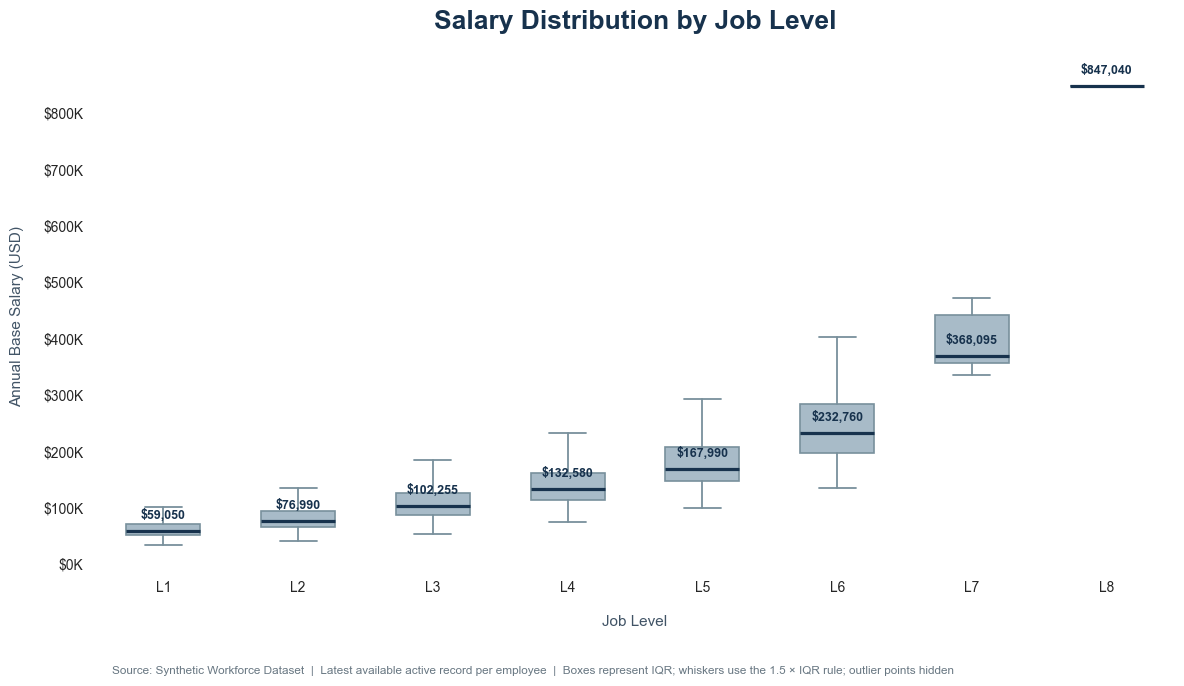

VISUALIZATION 10 — SALARY DISTRIBUTION BY JOB LEVEL
Saved File: c:\Projects\Raymond-James\1. workforce_data\reports\images\10_salary_distribution_by_job_level.png
Unique Employees: 8,306

SALARY DISTRIBUTION SUMMARY
           Employees  Median_Salary  Mean_Salary   Minimum   Maximum
job_level                                                           
L1              2224        59050.0     62445.61   33370.0  128280.0
L2              2670        76990.0     81761.03   41490.0  177000.0
L3              2190       102255.0    109023.96   53670.0  223650.0
L4               785       132580.0    139869.58   73860.0  286770.0
L5               315       167990.0    179161.68   98840.0  334040.0
L6               111       232760.0    247940.09  134790.0  455610.0
L7                10       368095.0    392917.00  335510.0  472150.0
L8                 1       847040.0    847040.00  847040.0  847040.0

Methodology: Latest available active employee record.
Boxplot outlier markers are hidden for 

In [47]:

# =============================================================================
# VISUALIZATION 10 — SALARY DISTRIBUTION BY JOB LEVEL
# Phase 5 | Compensation Analytics
# Salary Dispersion, Median Differences and Outlier Assessment
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Configure the visualization output directory.
current_dir = Path.cwd()

project_root = (
    current_dir.parent.parent
    if current_dir.name.lower() == "notebooks"
    else current_dir
)

output_dir = project_root / "reports" / "images"
output_dir.mkdir(parents=True, exist_ok=True)

# 2. Use the most recent active workforce snapshot.
# This prevents repeated employee-month observations from
# disproportionately affecting the salary distribution.
workforce = df_analysis.copy()

required_columns = [
    "employee_id",
    "month_date",
    "employment_status",
    "job_level",
    "base_salary"
]

missing = [
    col for col in required_columns
    if col not in workforce.columns
]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

workforce["month_date"] = pd.to_datetime(workforce["month_date"])

active_records = workforce[
    workforce["employment_status"].eq("Active")
].copy()

latest_active = (
    active_records
    .sort_values(["employee_id", "month_date"])
    .drop_duplicates("employee_id", keep="last")
    .copy()
)

latest_active["base_salary"] = pd.to_numeric(
    latest_active["base_salary"],
    errors="coerce"
)

latest_active = latest_active.dropna(
    subset=["job_level", "base_salary"]
)

# 3. Order job levels and prepare distributions.
job_levels = sorted(
    latest_active["job_level"].unique(),
    key=lambda value: int(str(value).replace("L", ""))
)

salary_groups = [
    latest_active.loc[
        latest_active["job_level"].eq(level),
        "base_salary"
    ].to_numpy()
    for level in job_levels
]

# 4. Calculate salary statistics for the report.
salary_summary = (
    latest_active.groupby("job_level")["base_salary"]
    .agg(
        Employees="count",
        Median_Salary="median",
        Mean_Salary="mean",
        Minimum="min",
        Maximum="max"
    )
    .reindex(job_levels)
)

# 5. Create a clean publication-ready boxplot.
fig, ax = plt.subplots(figsize=(12, 7))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

box = ax.boxplot(
    salary_groups,
    tick_labels=job_levels,
    patch_artist=True,
    widths=0.55,
    showfliers=False,
    medianprops={
        "color": "#17324D",
        "linewidth": 2.3
    },
    whiskerprops={
        "color": "#78909C",
        "linewidth": 1.3
    },
    capprops={
        "color": "#78909C",
        "linewidth": 1.3
    },
    boxprops={
        "linewidth": 1.2,
        "edgecolor": "#78909C"
    }
)

# Apply a consistent color palette.
for patch in box["boxes"]:
    patch.set_facecolor("#A8BBC8")

# 6. Annotate median salary values.
for i, level in enumerate(job_levels, start=1):
    median = salary_summary.loc[level, "Median_Salary"]

    ax.annotate(
        f"${median:,.0f}",
        (i, median),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        color="#17324D",
        fontweight="bold"
    )

# 7. Apply clean statistical-report formatting.
ax.set_title(
    "Salary Distribution by Job Level",
    fontsize=19,
    fontweight="bold",
    color="#17324D",
    pad=25
)

ax.set_xlabel(
    "Job Level",
    fontsize=11,
    color="#415466",
    labelpad=14
)

ax.set_ylabel(
    "Annual Base Salary (USD)",
    fontsize=11,
    color="#415466",
    labelpad=14
)

# Remove decorative gridlines and surrounding borders.
ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    which="both",
    length=0,
    labelsize=10,
    pad=9
)

# Format salary values as currency.
from matplotlib.ticker import FuncFormatter

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, pos: f"${value/1000:,.0f}K")
)

# 8. Add methodology notes.
fig.text(
    0.10,
    0.025,
    "Source: Synthetic Workforce Dataset  |  "
    "Latest available active record per employee  |  "
    "Boxes represent IQR; whiskers use the 1.5 × IQR rule; "
    "outlier points hidden",
    fontsize=8.5,
    color="#687782"
)

plt.tight_layout(rect=[0, 0.065, 1, 1])

# 9. Export the visualization.
save_path = output_dir / "10_salary_distribution_by_job_level.png"

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# 10. Print all results in one consolidated text output.
print(
    "\n".join([
        "=" * 85,
        "VISUALIZATION 10 — SALARY DISTRIBUTION BY JOB LEVEL",
        "=" * 85,
        f"Saved File: {save_path}",
        f"Unique Employees: {len(latest_active):,}",
        "",
        "SALARY DISTRIBUTION SUMMARY",
        salary_summary.round(2).to_string(),
        "",
        "Methodology: Latest available active employee record.",
        "Boxplot outlier markers are hidden for readability.",
        "=" * 85
    ])
)


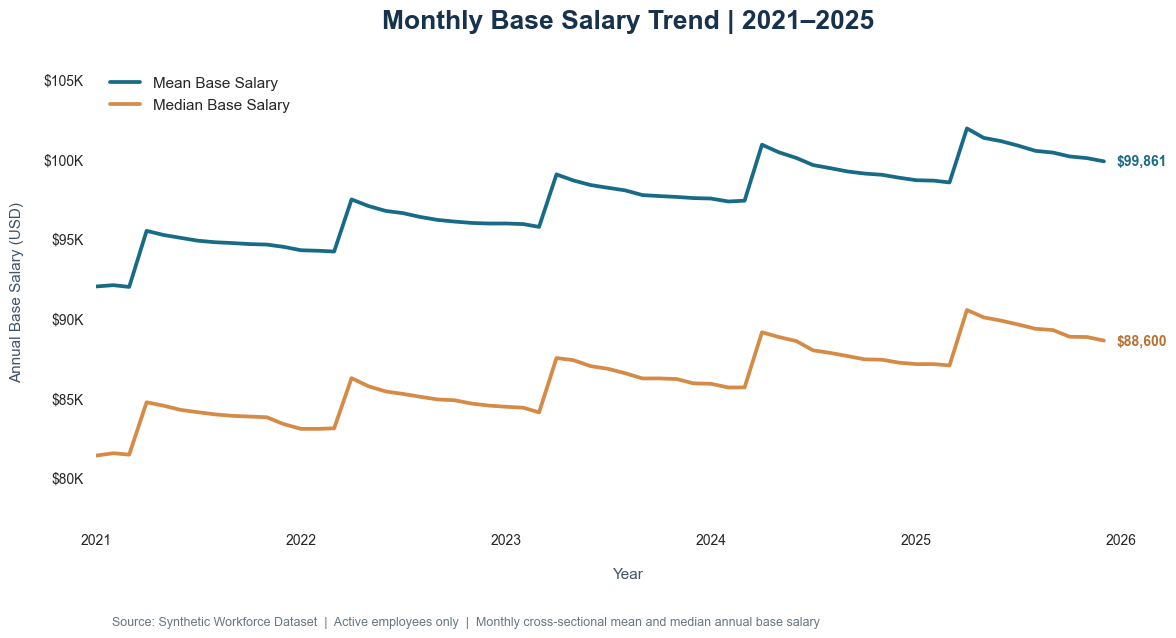

VISUALIZATION 11 — MONTHLY SALARY TREND
Saved File: c:\Projects\Raymond-James\1. workforce_data\reports\images\11_monthly_salary_trend.png
Months Analyzed: 60
Period: 2021-01 to 2025-12

FIRST VS. LAST MONTH
Starting Mean Salary: $91,998.34
Ending Mean Salary: $99,860.80
Mean Salary Change: +8.55%

Starting Median Salary: $81,370.00
Ending Median Salary: $88,600.00
Median Salary Change: +8.89%

ANNUAL SUMMARY
      Average_Monthly_Mean  Average_Monthly_Median  Average_Active_Employees
Year                                                                        
2021              94165.39                83389.58                   4793.83
2022              95929.57                84648.33                   4728.92
2023              97543.58                86056.25                   4753.50
2024              99072.85                87429.17                   4767.00
2025             100176.60                88847.50                   4829.67

Note: Changes reflect repeated cross-sectional 

In [48]:

# =============================================================================
# VISUALIZATION 11 — MONTHLY SALARY TREND
# Phase 5 | Compensation Analytics
# Mean and Median Base Salary Trends (2021–2025)
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from pathlib import Path

# 1. Configure the visualization output directory.
current_dir = Path.cwd()

project_root = (
    current_dir.parent.parent
    if current_dir.name.lower() == "notebooks"
    else current_dir
)

output_dir = project_root / "reports" / "images"
output_dir.mkdir(parents=True, exist_ok=True)

# 2. Prepare active employee-month compensation records.
required_columns = [
    "employee_id",
    "month_date",
    "employment_status",
    "base_salary"
]

missing = [
    col for col in required_columns
    if col not in df_analysis.columns
]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

salary_data = df_analysis.loc[
    df_analysis["employment_status"].eq("Active"),
    required_columns
].copy()

salary_data["month_date"] = pd.to_datetime(
    salary_data["month_date"]
)

salary_data["base_salary"] = pd.to_numeric(
    salary_data["base_salary"],
    errors="coerce"
)

# Validate employee-month uniqueness.
duplicates = salary_data.duplicated(
    ["employee_id", "month_date"]
).sum()

if duplicates:
    raise ValueError(
        f"Found {duplicates:,} duplicate employee-month records."
    )

# Exclude missing and nonpositive salaries from compensation statistics.
salary_data = salary_data[
    salary_data["base_salary"].notna()
    & (salary_data["base_salary"] > 0)
].copy()

# 3. Calculate monthly mean and median base salary.
salary_trend = (
    salary_data.groupby("month_date")
    .agg(
        Active_Employees=("employee_id", "nunique"),
        Mean_Salary=("base_salary", "mean"),
        Median_Salary=("base_salary", "median")
    )
    .sort_index()
)

if salary_trend.empty:
    raise ValueError("No valid monthly salary records found.")

salary_trend["Mean_Median_Gap"] = (
    salary_trend["Mean_Salary"]
    - salary_trend["Median_Salary"]
)

# 4. Create a professional two-series line chart.
fig, ax = plt.subplots(figsize=(12, 6.5))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

ax.plot(
    salary_trend.index,
    salary_trend["Mean_Salary"],
    color="#176B87",
    linewidth=2.7,
    label="Mean Base Salary"
)

ax.plot(
    salary_trend.index,
    salary_trend["Median_Salary"],
    color="#D58B45",
    linewidth=2.7,
    label="Median Base Salary"
)

# 5. Label the final observed values.
last_date = salary_trend.index[-1]
last_mean = salary_trend["Mean_Salary"].iloc[-1]
last_median = salary_trend["Median_Salary"].iloc[-1]

for value, color in [
    (last_mean, "#176B87"),
    (last_median, "#B87133")
]:
    ax.annotate(
        f"${value:,.0f}",
        (last_date, value),
        xytext=(9, 0),
        textcoords="offset points",
        va="center",
        fontsize=10,
        fontweight="bold",
        color=color
    )

# 6. Apply clean publication-ready formatting.
ax.set_title(
    "Monthly Base Salary Trend | 2021–2025",
    fontsize=19,
    fontweight="bold",
    color="#17324D",
    pad=25
)

ax.set_ylabel(
    "Annual Base Salary (USD)",
    fontsize=11,
    color="#415466",
    labelpad=14
)

ax.set_xlabel(
    "Year",
    fontsize=11,
    color="#415466",
    labelpad=14
)

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, pos: f"${value/1000:,.0f}K")
)

# Preserve natural scale without truncating the observed trends.
all_values = np.concatenate([
    salary_trend["Mean_Salary"].to_numpy(),
    salary_trend["Median_Salary"].to_numpy()
])

padding = max(np.ptp(all_values) * 0.2, 1000)

ax.set_ylim(
    all_values.min() - padding,
    all_values.max() + padding
)

ax.set_xlim(
    salary_trend.index.min(),
    salary_trend.index.max() + pd.Timedelta(days=100)
)

# Remove all gridlines and chart borders.
ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    which="both",
    length=0,
    labelsize=10,
    pad=9
)

ax.legend(
    loc="upper left",
    frameon=False,
    fontsize=11
)

# 7. Document the source and methodology.
fig.text(
    0.10,
    0.025,
    "Source: Synthetic Workforce Dataset  |  "
    "Active employees only  |  "
    "Monthly cross-sectional mean and median annual base salary",
    fontsize=9,
    color="#687782"
)

plt.tight_layout(rect=[0, 0.065, 1, 1])

# 8. Export the visualization.
save_path = output_dir / "11_monthly_salary_trend.png"

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# 9. Print all results in one consolidated text output.
start = salary_trend.iloc[0]
end = salary_trend.iloc[-1]

mean_change = (
    (end["Mean_Salary"] / start["Mean_Salary"] - 1) * 100
)

median_change = (
    (end["Median_Salary"] / start["Median_Salary"] - 1) * 100
)

print("\n".join([
    "=" * 85,
    "VISUALIZATION 11 — MONTHLY SALARY TREND",
    "=" * 85,
    f"Saved File: {save_path}",
    f"Months Analyzed: {len(salary_trend)}",
    f"Period: {salary_trend.index.min():%Y-%m} "
    f"to {salary_trend.index.max():%Y-%m}",
    "",
    "FIRST VS. LAST MONTH",
    f"Starting Mean Salary: ${start['Mean_Salary']:,.2f}",
    f"Ending Mean Salary: ${end['Mean_Salary']:,.2f}",
    f"Mean Salary Change: {mean_change:+.2f}%",
    "",
    f"Starting Median Salary: ${start['Median_Salary']:,.2f}",
    f"Ending Median Salary: ${end['Median_Salary']:,.2f}",
    f"Median Salary Change: {median_change:+.2f}%",
    "",
    "ANNUAL SUMMARY",
    salary_trend.assign(
        Year=salary_trend.index.year
    ).groupby("Year").agg(
        Average_Monthly_Mean=("Mean_Salary", "mean"),
        Average_Monthly_Median=("Median_Salary", "mean"),
        Average_Active_Employees=("Active_Employees", "mean")
    ).round(2).to_string(),
    "",
    "Note: Changes reflect repeated cross-sectional workforce",
    "snapshots, not salary increases for a fixed employee cohort.",
    "=" * 85
]))


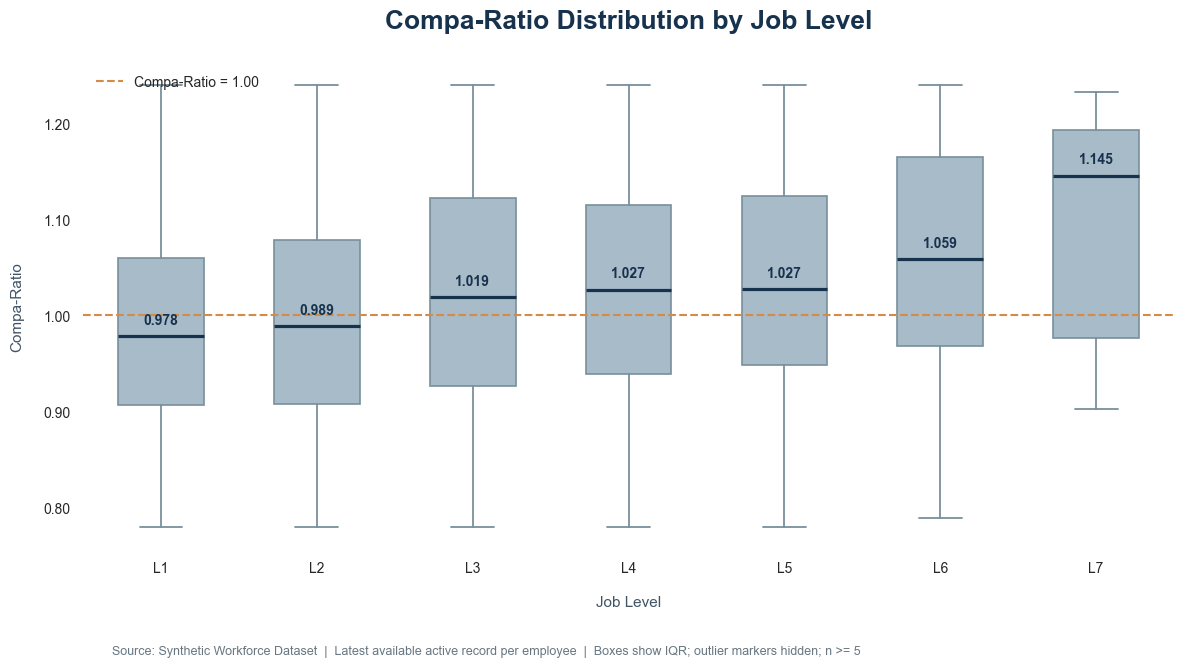

VISUALIZATION 12 — COMPA-RATIO DISTRIBUTION BY JOB LEVEL
Saved File: c:\Projects\Raymond-James\1. workforce_data\reports\images\12_compa_ratio_by_job_level.png
Unique Employees: 8,306
Plotted Job Levels: L1, L2, L3, L4, L5, L6, L7
Excluded Sparse Levels: L8

COMPA-RATIO DISTRIBUTION SUMMARY
           Employees    Mean  Median  Std_Dev  Minimum  Maximum
job_level                                                      
L1              2224  0.9886  0.9784   0.1090   0.7799   1.2401
L2              2670  0.9970  0.9885   0.1162   0.7799   1.2401
L3              2190  1.0226  1.0189   0.1246   0.7800   1.2400
L4               785  1.0301  1.0268   0.1176   0.7800   1.2400
L5               315  1.0341  1.0274   0.1180   0.7800   1.2400
L6               111  1.0583  1.0586   0.1241   0.7885   1.2400
L7                10  1.0918  1.1453   0.1312   0.9021   1.2329
L8                 1  1.2400  1.2400      NaN   1.2400   1.2400

Reference Line: Compa-Ratio = 1.00
Methodology: Latest available ac

In [49]:

# =============================================================================
# VISUALIZATION 12 — COMPA-RATIO DISTRIBUTION BY JOB LEVEL
# Phase 5 | Compensation Analytics
# Compensation Positioning, Distribution and Between-Level Differences
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter
from pathlib import Path

# 1. Configure the report visualization directory.
current_dir = Path.cwd()

project_root = (
    current_dir.parent.parent
    if current_dir.name.lower() == "notebooks"
    else current_dir
)

output_dir = project_root / "reports" / "images"
output_dir.mkdir(parents=True, exist_ok=True)

# 2. Validate the required workforce fields.
required_columns = [
    "employee_id",
    "month_date",
    "employment_status",
    "job_level",
    "compa_ratio"
]

missing = [
    col for col in required_columns
    if col not in df_analysis.columns
]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

# 3. Select each employee's latest available active record.
workforce = df_analysis[required_columns].copy()

workforce["month_date"] = pd.to_datetime(
    workforce["month_date"]
)

workforce["compa_ratio"] = pd.to_numeric(
    workforce["compa_ratio"],
    errors="coerce"
)

active = workforce[
    workforce["employment_status"].eq("Active")
].copy()

latest_active = (
    active.sort_values(["employee_id", "month_date"])
    .drop_duplicates("employee_id", keep="last")
    .dropna(subset=["job_level", "compa_ratio"])
    .copy()
)

latest_active = latest_active[
    np.isfinite(latest_active["compa_ratio"])
    & (latest_active["compa_ratio"] > 0)
]

# 4. Prepare ordered job-level distributions.
job_levels = sorted(
    latest_active["job_level"].unique(),
    key=lambda level: int(str(level).replace("L", ""))
)

group_counts = (
    latest_active.groupby("job_level")["compa_ratio"]
    .count()
    .reindex(job_levels)
)

# Exclude groups with insufficient observations from boxplots.
eligible_levels = group_counts[
    group_counts >= 5
].index.tolist()

excluded_levels = group_counts[
    group_counts < 5
].index.tolist()

if not eligible_levels:
    raise ValueError("No job levels have at least five observations.")

distributions = [
    latest_active.loc[
        latest_active["job_level"].eq(level),
        "compa_ratio"
    ].to_numpy()
    for level in eligible_levels
]

# 5. Calculate compensation positioning statistics.
compa_summary = (
    latest_active.groupby("job_level")["compa_ratio"]
    .agg(
        Employees="count",
        Mean="mean",
        Median="median",
        Std_Dev="std",
        Minimum="min",
        Maximum="max"
    )
    .reindex(job_levels)
)

# 6. Create the boxplot.
fig, ax = plt.subplots(figsize=(12, 6.8))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

box = ax.boxplot(
    distributions,
    tick_labels=eligible_levels,
    patch_artist=True,
    widths=0.55,
    showfliers=False,
    medianprops={
        "color": "#17324D",
        "linewidth": 2.3
    },
    whiskerprops={
        "color": "#78909C",
        "linewidth": 1.3
    },
    capprops={
        "color": "#78909C",
        "linewidth": 1.3
    },
    boxprops={
        "edgecolor": "#78909C",
        "linewidth": 1.2
    }
)

for patch in box["boxes"]:
    patch.set_facecolor("#A8BBC8")

# 7. Add the compensation midpoint reference line.
ax.axhline(
    1.0,
    color="#D58B45",
    linestyle="--",
    linewidth=1.5,
    label="Compa-Ratio = 1.00"
)

# 8. Annotate median values.
for position, level in enumerate(eligible_levels, start=1):
    median = compa_summary.loc[level, "Median"]

    ax.annotate(
        f"{median:.3f}",
        (position, median),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        color="#17324D",
        fontweight="bold"
    )

# 9. Apply publication-ready styling.
ax.set_title(
    "Compa-Ratio Distribution by Job Level",
    fontsize=19,
    fontweight="bold",
    color="#17324D",
    pad=25
)

ax.set_xlabel(
    "Job Level",
    fontsize=11,
    color="#415466",
    labelpad=14
)

ax.set_ylabel(
    "Compa-Ratio",
    fontsize=11,
    color="#415466",
    labelpad=14
)

ax.yaxis.set_major_formatter(
    FormatStrFormatter("%.2f")
)

# Remove decorative gridlines and borders.
ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    which="both",
    length=0,
    labelsize=10,
    pad=9
)

ax.legend(
    loc="upper left",
    frameon=False,
    fontsize=10
)

# 10. Add source and methodology notes.
fig.text(
    0.10,
    0.025,
    "Source: Synthetic Workforce Dataset  |  "
    "Latest available active record per employee  |  "
    "Boxes show IQR; outlier markers hidden; n >= 5",
    fontsize=9,
    color="#687782"
)

plt.tight_layout(rect=[0, 0.065, 1, 1])

# 11. Export the visualization.
save_path = output_dir / "12_compa_ratio_by_job_level.png"

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# 12. Print all results in one consolidated text output.
print("\n".join([
    "=" * 85,
    "VISUALIZATION 12 — COMPA-RATIO DISTRIBUTION BY JOB LEVEL",
    "=" * 85,
    f"Saved File: {save_path}",
    f"Unique Employees: {len(latest_active):,}",
    f"Plotted Job Levels: {', '.join(eligible_levels)}",
    f"Excluded Sparse Levels: {', '.join(excluded_levels) if excluded_levels else 'None'}",
    "",
    "COMPA-RATIO DISTRIBUTION SUMMARY",
    compa_summary.round(4).to_string(),
    "",
    "Reference Line: Compa-Ratio = 1.00",
    "Methodology: Latest available active record per employee.",
    "Outlier points are hidden for readability.",
    "=" * 85
]))


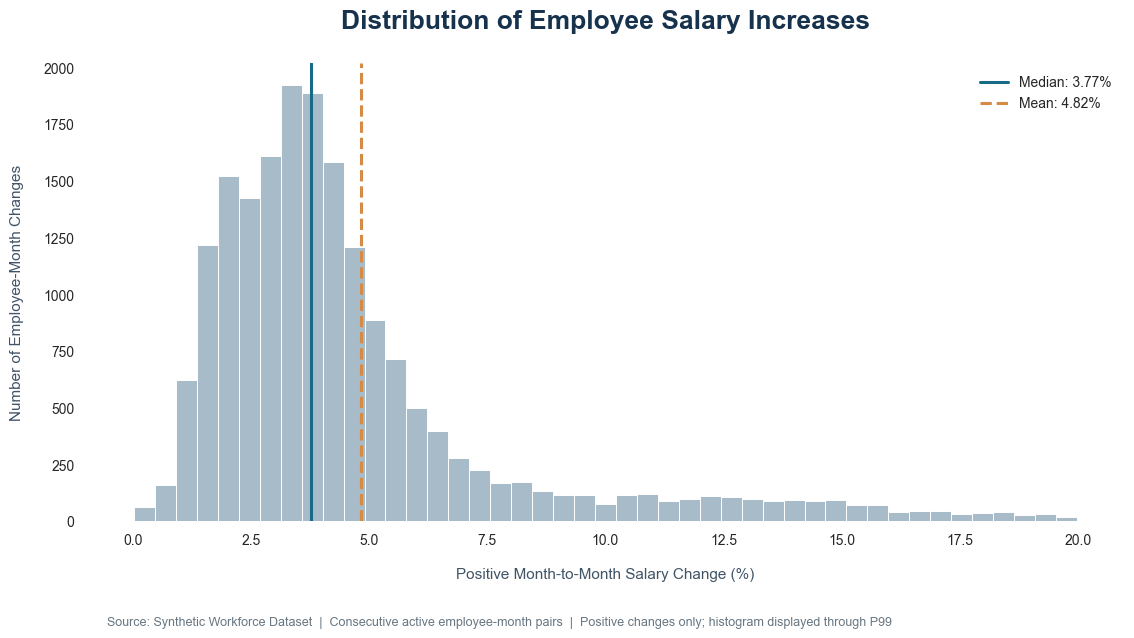

VISUALIZATION 13 — EMPLOYEE SALARY INCREASE DISTRIBUTION
Saved File: c:\Projects\Raymond-James\1. workforce_data\reports\images\13_salary_increase_distribution.png

                                Metric       Value
Valid Consecutive Employee-Month Pairs 278,169.000
               Positive Salary Changes  18,731.000
       Employees with Positive Changes   6,025.000
                     Mean Increase (%)       4.823
                   Median Increase (%)       3.770
                   90th Percentile (%)       9.485
                   95th Percentile (%)      13.625
                   99th Percentile (%)      20.020
                  Maximum Increase (%)      35.405
   Observations Displayed in Histogram  18,543.000

Each observation represents one positive consecutive-month
base salary change, not one unique employee.
The histogram excludes values above P99 for display only.
All positive changes are included in the summary statistics.


In [50]:

# =============================================================================
# VISUALIZATION 13 — EMPLOYEE SALARY INCREASE DISTRIBUTION
# Phase 5 | Compensation Analytics
# Distribution of Positive Month-to-Month Base Salary Changes
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from pathlib import Path

# 1. Configure the visualization output directory.
current_dir = Path.cwd()

project_root = (
    current_dir.parent.parent
    if current_dir.name.lower() == "notebooks"
    else current_dir
)

output_dir = project_root / "reports" / "images"
output_dir.mkdir(parents=True, exist_ok=True)

# 2. Prepare employee-level monthly salary history.
salary_panel = df_analysis[
    ["employee_id", "month_date", "employment_status", "base_salary"]
].copy()

salary_panel["month_date"] = pd.to_datetime(
    salary_panel["month_date"]
)

salary_panel["base_salary"] = pd.to_numeric(
    salary_panel["base_salary"], errors="coerce"
)

salary_panel = salary_panel[
    salary_panel["employment_status"].eq("Active")
    & salary_panel["base_salary"].gt(0)
].copy()

salary_panel = salary_panel.sort_values(
    ["employee_id", "month_date"]
)

# 3. Calculate changes only between consecutive monthly observations.
salary_panel["previous_salary"] = (
    salary_panel.groupby("employee_id")["base_salary"].shift(1)
)

salary_panel["previous_month"] = (
    salary_panel.groupby("employee_id")["month_date"].shift(1)
)

salary_panel["month_gap"] = (
    (salary_panel["month_date"].dt.year -
     salary_panel["previous_month"].dt.year) * 12
    + salary_panel["month_date"].dt.month
    - salary_panel["previous_month"].dt.month
)

salary_panel["salary_change_pct"] = (
    salary_panel["base_salary"] /
    salary_panel["previous_salary"] - 1
) * 100

valid_pairs = salary_panel[
    salary_panel["month_gap"].eq(1)
    & salary_panel["previous_salary"].gt(0)
    & np.isfinite(salary_panel["salary_change_pct"])
].copy()

# Retain positive changes only.
increases = valid_pairs.loc[
    valid_pairs["salary_change_pct"].gt(0),
    "salary_change_pct"
].copy()

if increases.empty:
    raise ValueError("No positive salary changes were detected.")

# 4. Calculate distribution statistics.
mean_increase = increases.mean()
median_increase = increases.median()
p90 = increases.quantile(0.90)
p95 = increases.quantile(0.95)
p99 = increases.quantile(0.99)

# Limit the displayed range to P99 without deleting source observations.
plot_values = increases[increases <= p99]

# 5. Create a publication-ready histogram.
fig, ax = plt.subplots(figsize=(11.5, 6.5))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

ax.hist(
    plot_values,
    bins=45,
    color="#A8BBC8",
    edgecolor="white",
    linewidth=0.7
)

# Add median and mean reference lines.
ax.axvline(
    median_increase,
    color="#176B87",
    linewidth=2.2,
    label=f"Median: {median_increase:.2f}%"
)

ax.axvline(
    mean_increase,
    color="#D58B45",
    linewidth=2.2,
    linestyle="--",
    label=f"Mean: {mean_increase:.2f}%"
)

# 6. Apply clean statistical-report styling.
ax.set_title(
    "Distribution of Employee Salary Increases",
    fontsize=19,
    fontweight="bold",
    color="#17324D",
    pad=25
)

ax.set_xlabel(
    "Positive Month-to-Month Salary Change (%)",
    fontsize=11,
    color="#415466",
    labelpad=14
)

ax.set_ylabel(
    "Number of Employee-Month Changes",
    fontsize=11,
    color="#415466",
    labelpad=14
)

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    which="both",
    length=0,
    labelsize=10,
    pad=9
)

ax.legend(
    loc="upper right",
    frameon=False,
    fontsize=10
)

# 7. Add methodology and display-scope notes.
fig.text(
    0.10,
    0.025,
    "Source: Synthetic Workforce Dataset  |  "
    "Consecutive active employee-month pairs  |  "
    "Positive changes only; histogram displayed through P99",
    fontsize=9,
    color="#687782"
)

plt.tight_layout(rect=[0, 0.065, 1, 1])

# 8. Export the visualization.
save_path = output_dir / "13_salary_increase_distribution.png"

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# 9. Print the complete numerical summary in one output.
summary = pd.DataFrame({
    "Metric": [
        "Valid Consecutive Employee-Month Pairs",
        "Positive Salary Changes",
        "Employees with Positive Changes",
        "Mean Increase (%)",
        "Median Increase (%)",
        "90th Percentile (%)",
        "95th Percentile (%)",
        "99th Percentile (%)",
        "Maximum Increase (%)",
        "Observations Displayed in Histogram"
    ],
    "Value": [
        len(valid_pairs),
        len(increases),
        valid_pairs.loc[
            valid_pairs["salary_change_pct"].gt(0),
            "employee_id"
        ].nunique(),
        mean_increase,
        median_increase,
        p90,
        p95,
        p99,
        increases.max(),
        len(plot_values)
    ]
})

print("\n".join([
    "=" * 85,
    "VISUALIZATION 13 — EMPLOYEE SALARY INCREASE DISTRIBUTION",
    "=" * 85,
    f"Saved File: {save_path}",
    "",
    summary.to_string(index=False, float_format=lambda x: f"{x:,.3f}"),
    "",
    "Each observation represents one positive consecutive-month",
    "base salary change, not one unique employee.",
    "The histogram excludes values above P99 for display only.",
    "All positive changes are included in the summary statistics.",
    "=" * 85
]))


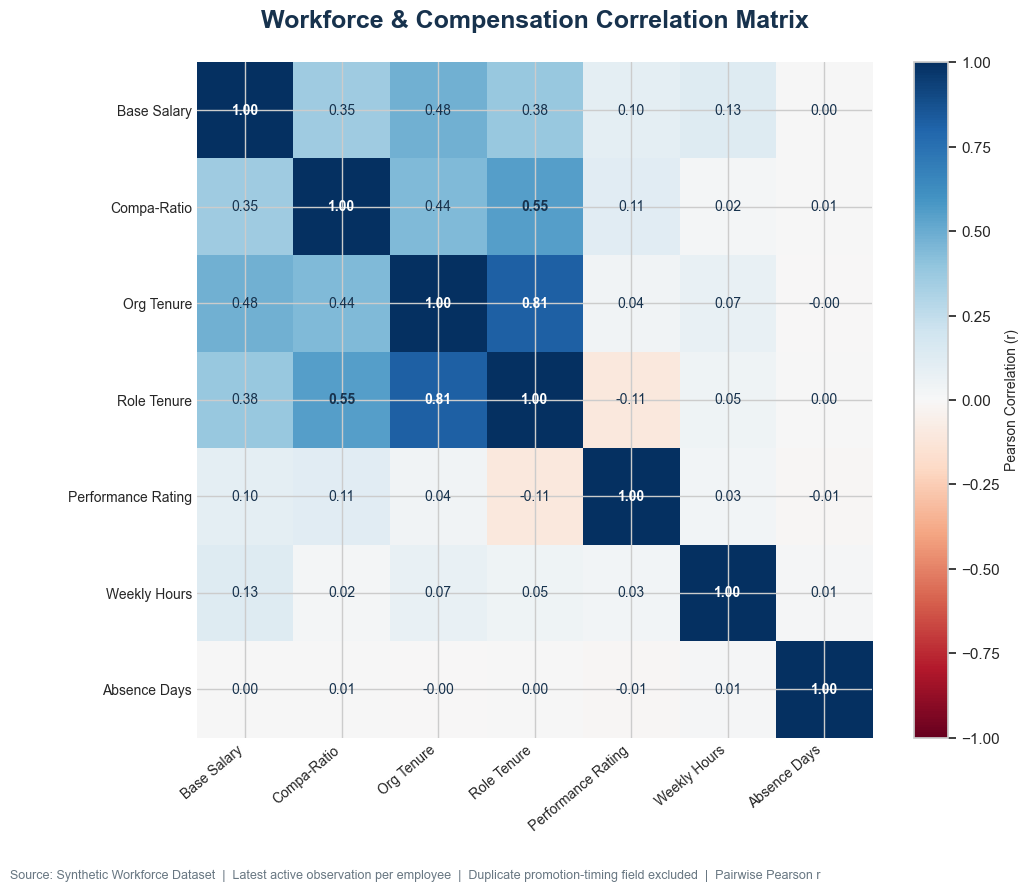

VISUALIZATION 16 — WORKFORCE CORRELATION HEATMAP
Saved File: c:\Projects\Raymond-James\1. workforce_data\reports\images\16_workforce_correlation_heatmap.png
Employees Analyzed: 8,306
Variables Included: 7

PEARSON CORRELATION MATRIX
                              base_salary  compa_ratio  organizational_tenure_months  role_tenure_months  latest_performance_rating  average_weekly_hours  unscheduled_absence_days
base_salary                        1.0000       0.3546                        0.4813              0.3786                     0.0956                0.1250                    0.0027
compa_ratio                        0.3546       1.0000                        0.4448              0.5504                     0.1102                0.0221                    0.0069
organizational_tenure_months       0.4813       0.4448                        1.0000              0.8148                     0.0359                0.0745                   -0.0048
role_tenure_months                 0.3786      

In [51]:

# =============================================================================
# VISUALIZATION 16 — WORKFORCE CORRELATION HEATMAP
# Phase 5 | Exploratory & Statistical Analysis
# Pearson Correlations Across Workforce and Compensation Indicators
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Configure the report visualization directory.
current_dir = Path.cwd()

project_root = (
    current_dir.parent.parent
    if current_dir.name.lower() == "notebooks"
    else current_dir
)

output_dir = project_root / "reports" / "images"
output_dir.mkdir(parents=True, exist_ok=True)

# 2. Prepare one latest active observation per employee.
workforce = df_analysis.copy()
workforce["month_date"] = pd.to_datetime(workforce["month_date"])

latest_active = (
    workforce.loc[
        workforce["employment_status"].eq("Active")
    ]
    .sort_values(["employee_id", "month_date"])
    .drop_duplicates("employee_id", keep="last")
    .copy()
)

# 3. Select nonredundant numerical indicators (see Step 23 and full-panel audit).
candidate_features = {
    "base_salary": "Base Salary",
    "compa_ratio": "Compa-Ratio",
    "organizational_tenure_months": "Org Tenure",
    "role_tenure_months": "Role Tenure",
    "latest_performance_rating": "Performance Rating",
    "average_weekly_hours": "Weekly Hours",
    "unscheduled_absence_days": "Absence Days"
}

available = {
    col: label
    for col, label in candidate_features.items()
    if col in latest_active.columns
}

if len(available) < 3:
    raise ValueError(
        "Insufficient numerical workforce variables for a heatmap."
    )

data = latest_active[list(available)].copy()

for col in data.columns:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# Remove constant or unusable variables.
data = data.loc[
    :,
    data.nunique(dropna=True) > 1
]

# Require a minimum number of paired valid observations.
minimum_pairs = 30

correlation = data.corr(
    method="pearson",
    min_periods=minimum_pairs
)

pair_counts = data.notna().astype(int).T.dot(
    data.notna().astype(int)
)

labels = [available[col] for col in correlation.columns]
values = correlation.to_numpy(dtype=float)

# 4. Create a clean correlation heatmap.
fig, ax = plt.subplots(figsize=(11.5, 9))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

heatmap = ax.imshow(
    values,
    cmap="RdBu",
    vmin=-1,
    vmax=1,
    aspect="equal"
)

# Add correlation coefficients inside each cell.
for i in range(len(labels)):
    for j in range(len(labels)):
        value = values[i, j]

        if np.isfinite(value):
            ax.text(
                j, i, f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=10,
                fontweight="bold" if abs(value) >= 0.5 else "normal",
                color="white" if abs(value) >= 0.65 else "#17324D"
            )

# 5. Apply publication-ready formatting.
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))

ax.set_xticklabels(
    labels,
    rotation=40,
    ha="right",
    fontsize=10
)

ax.set_yticklabels(labels, fontsize=10)

ax.set_title(
    "Workforce & Compensation Correlation Matrix",
    fontsize=18,
    fontweight="bold",
    color="#17324D",
    pad=25
)

ax.tick_params(axis="both", length=0)

for spine in ax.spines.values():
    spine.set_visible(False)

colorbar = fig.colorbar(
    heatmap,
    ax=ax,
    fraction=0.045,
    pad=0.04
)

colorbar.set_label(
    "Pearson Correlation (r)",
    fontsize=10
)

# 6. Add methodology notes.
fig.text(
    0.10,
    0.015,
    "Source: Synthetic Workforce Dataset  |  "
    "Latest active observation per employee  |  "
    "Duplicate promotion-timing field excluded  |  Pairwise Pearson r",
    fontsize=9,
    color="#687782"
)

plt.tight_layout(rect=[0, 0.045, 1, 1])

# 7. Save the visualization.
save_path = output_dir / "16_workforce_correlation_heatmap.png"

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# 8. Identify strongest non-diagonal relationships.
upper_mask = np.triu(
    np.ones(correlation.shape, dtype=bool),
    k=1
)

pairs = (
    correlation.where(upper_mask)
    .stack()
    .reset_index()
)

pairs.columns = ["Variable_1", "Variable_2", "Pearson_R"]
pairs["Absolute_R"] = pairs["Pearson_R"].abs()

pairs = pairs.sort_values(
    "Absolute_R", ascending=False
)

# 9. Print all results in one consolidated output.
print("\n".join([
    "=" * 85,
    "VISUALIZATION 16 — WORKFORCE CORRELATION HEATMAP",
    "=" * 85,
    f"Saved File: {save_path}",
    f"Employees Analyzed: {len(latest_active):,}",
    f"Variables Included: {len(correlation.columns)}",
    "",
    "PEARSON CORRELATION MATRIX",
    correlation.round(4).to_string(),
    "",
    "VALID PAIRWISE OBSERVATION COUNTS",
    pair_counts.to_string(),
    "",
    "STRONGEST OBSERVED CORRELATIONS",
    pairs.head(12).round(4).to_string(index=False),
    "",
    "Correlations are descriptive and do not establish causality.",
    "Missing values are handled using pairwise-complete observations.",
    "Redundant months_since_last_promotion excluded; see Step 23.",
    "=" * 85
]))


In [52]:

# =============================================================================
# DATA QUALITY VALIDATION — FULL PANEL FEATURE REDUNDANCY
# Verify Role Tenure and Months Since Last Promotion Across All Records
# =============================================================================

import pandas as pd
import numpy as np

# Select the complete monthly analytical population.
columns = [
    "employee_id",
    "month_date",
    "role_tenure_months",
    "months_since_last_promotion"
]

panel_check = df_analysis[columns].copy()

a = pd.to_numeric(
    panel_check["role_tenure_months"], errors="coerce"
)

b = pd.to_numeric(
    panel_check["months_since_last_promotion"], errors="coerce"
)

# Compare values, including missing-value patterns.
both_present = a.notna() & b.notna()
both_missing = a.isna() & b.isna()

exact_matches = both_present & a.eq(b)
different_values = both_present & a.ne(b)
missing_mismatch = a.isna() ^ b.isna()

# Examine differences by calendar year.
panel_check["year"] = pd.to_datetime(
    panel_check["month_date"]
).dt.year

panel_check["exact_match"] = exact_matches
panel_check["different_value"] = different_values
panel_check["missing_mismatch"] = missing_mismatch

yearly = panel_check.groupby("year").agg(
    Records=("employee_id", "size"),
    Exact_Matches=("exact_match", "sum"),
    Different_Values=("different_value", "sum"),
    Missing_Mismatches=("missing_mismatch", "sum")
)

# Produce one consolidated text output.
print("\n".join([
    "=" * 80,
    "FULL PANEL — FEATURE REDUNDANCY VALIDATION",
    "=" * 80,
    f"Total Records: {len(panel_check):,}",
    f"Both Values Present: {both_present.sum():,}",
    f"Exact Matches: {exact_matches.sum():,}",
    f"Different Values: {different_values.sum():,}",
    f"Both Values Missing: {both_missing.sum():,}",
    f"Missing-Value Mismatches: {missing_mismatch.sum():,}",
    "",
    "ANNUAL VALIDATION",
    yearly.to_string(),
    "",
    "Conclusion: Feature equivalence requires zero differing values",
    "and zero missing-value mismatches across the complete panel.",
    "=" * 80
]))


FULL PANEL — FEATURE REDUNDANCY VALIDATION
Total Records: 290,014
Both Values Present: 290,014
Exact Matches: 290,014
Different Values: 0
Both Values Missing: 0
Missing-Value Mismatches: 0

ANNUAL VALIDATION
      Records  Exact_Matches  Different_Values  Missing_Mismatches
year                                                              
2021    58306          58306                 0                   0
2022    57472          57472                 0                   0
2023    57746          57746                 0                   0
2024    57934          57934                 0                   0
2025    58556          58556                 0                   0

Conclusion: Feature equivalence requires zero differing values
and zero missing-value mismatches across the complete panel.


In [53]:

# =============================================================================
# PHASE 5 — STEP 59
# TURNOVER & RETENTION ANALYSIS
# Annual & Monthly Turnover Rates and Workforce Reconciliation
# =============================================================================

import pandas as pd

output = []
output.append("=" * 80)
output.append("STEP 59 — ANNUAL & MONTHLY TURNOVER RATE ANALYSIS")
output.append("=" * 80)

# 1. Prepare employee-month records.
panel = (
    df_analysis[
        ["employee_id", "month_date", "employment_status"]
    ]
    .drop_duplicates()
    .copy()
)

panel["month_date"] = pd.to_datetime(panel["month_date"])
panel["year"] = panel["month_date"].dt.year

# 2. Calculate monthly active headcount and separation events.
monthly = (
    panel.groupby("month_date")
    .agg(
        active_headcount=(
            "employment_status",
            lambda s: (s == "Active").sum()
        ),
        separations=(
            "employment_status",
            lambda s: (s == "Terminated").sum()
        )
    )
    .sort_index()
)

# Calculate average headcount using adjacent monthly snapshots.
monthly["previous_active"] = monthly["active_headcount"].shift(1)

monthly["average_headcount"] = (
    monthly["active_headcount"] + monthly["previous_active"]
) / 2

# The first month uses its observed active headcount as a proxy.
monthly.loc[
    monthly["average_headcount"].isna(),
    "average_headcount"
] = monthly["active_headcount"]

monthly["turnover_rate_pct"] = (
    monthly["separations"] /
    monthly["average_headcount"] * 100
)

monthly["year"] = monthly.index.year

output.append("\n1. MONTHLY TURNOVER METRICS")
output.append(
    monthly[
        [
            "active_headcount",
            "separations",
            "average_headcount",
            "turnover_rate_pct"
        ]
    ].round(3).to_string()
)

# 3. Calculate annual turnover using average monthly headcount.
annual = (
    monthly.groupby("year")
    .agg(
        annual_separations=("separations", "sum"),
        average_active_headcount=("active_headcount", "mean"),
        opening_observed_headcount=("active_headcount", "first"),
        closing_active_headcount=("active_headcount", "last")
    )
)

annual["annual_turnover_rate_pct"] = (
    annual["annual_separations"] /
    annual["average_active_headcount"] * 100
)

output.append("\n2. ANNUAL TURNOVER METRICS")
output.append(annual.round(3).to_string())

# 4. Reconcile separation totals and final active headcount.
recorded_separations = (
    panel["employment_status"].eq("Terminated").sum()
)

final_terminated = (
    latest_employee_records["employment_status"]
    .eq("Terminated").sum()
)

final_active = (
    latest_employee_records["employment_status"]
    .eq("Active").sum()
)

output.append("\n3. WORKFORCE RECONCILIATION")
output.append(f"Total Recorded Separations: {recorded_separations:,}")
output.append(f"Final Terminated Employees: {final_terminated:,}")
output.append(
    f"Separation Count Difference: "
    f"{recorded_separations - final_terminated:,}"
)
output.append(f"Final Active Employees: {final_active:,}")
output.append(
    f"December 2025 Active Headcount: "
    f"{monthly.iloc[-1]['active_headcount']:,.0f}"
)

output.append("\n4. METHODOLOGICAL NOTES")
output.append(
    "Annual turnover = annual separations / "
    "mean monthly active headcount."
)
output.append(
    "Monthly turnover = monthly separations / "
    "average of current and previous month active headcount."
)
output.append(
    "January 2021 uses observed active headcount as a proxy "
    "because December 2020 is unavailable."
)
output.append(
    "Rates are descriptive and depend on snapshot timing conventions."
)

output.append("\n" + "=" * 80)
output.append("STEP 59 ANALYSIS COMPLETE")
output.append("=" * 80)

# Print all results as one consolidated output.
print("\n".join(output))


STEP 59 — ANNUAL & MONTHLY TURNOVER RATE ANALYSIS

1. MONTHLY TURNOVER METRICS
            active_headcount  separations  average_headcount  turnover_rate_pct
month_date                                                                     
2021-01-01              4923           77             4923.0              1.564
2021-02-01              4856           85             4889.5              1.738
2021-03-01              4825           62             4840.5              1.281
2021-04-01              4795           63             4810.0              1.310
2021-05-01              4805           59             4800.0              1.229
2021-06-01              4801           67             4803.0              1.395
2021-07-01              4804           56             4802.5              1.166
2021-08-01              4778           62             4791.0              1.294
2021-09-01              4763           62             4770.5              1.300
2021-10-01              4744           67

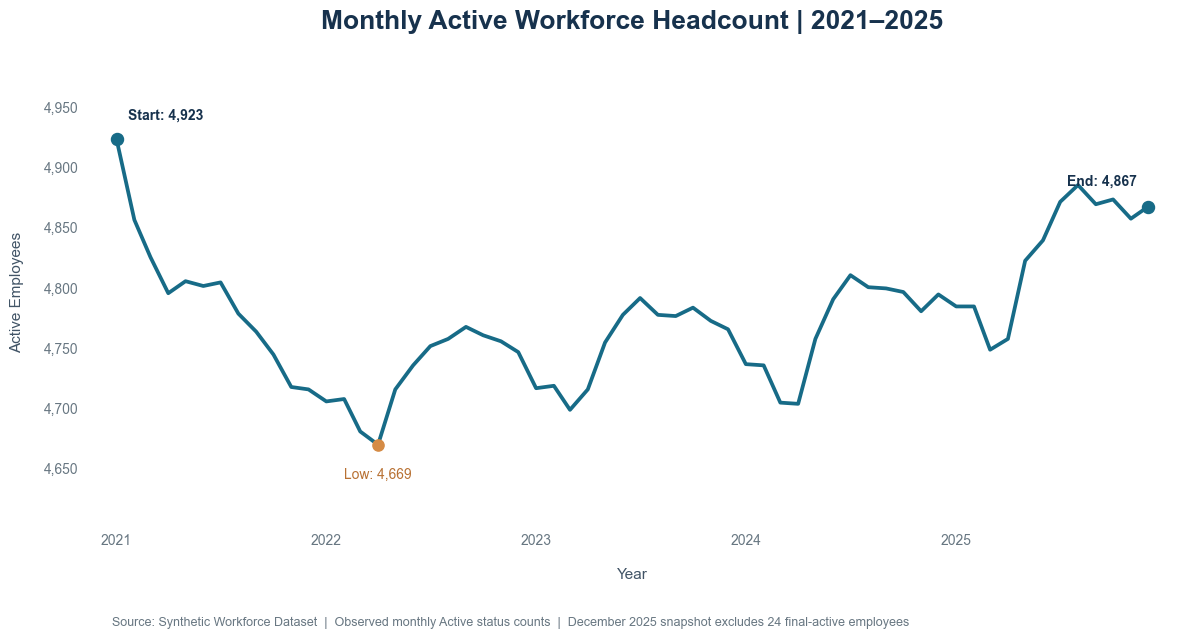

VISUALIZATION 15 — MONTHLY WORKFORCE HEADCOUNT TREND
Saved File: c:\Projects\Raymond-James\1. workforce_data\reports\images\15_monthly_workforce_headcount.png
Months Analyzed: 60

WORKFORCE CHANGE SUMMARY
Starting Headcount (2021-01): 4,923
Ending Headcount (2025-12): 4,867
Net Change: -56
Percentage Change: -1.14%
Minimum Headcount (2022-04): 4,669
Maximum Headcount (2021-01): 4,923

ANNUAL HEADCOUNT SUMMARY
      Average  Minimum  Maximum  Year_End
Year                                     
2021  4793.83     4715     4923      4715
2022  4728.92     4669     4767      4746
2023  4753.50     4698     4791      4765
2024  4767.00     4703     4810      4794
2025  4829.67     4748     4885      4867

Methodology: Observed monthly Active employee records.
These are snapshot counts, not cumulative unique employees.
Known discrepancy: 24 final-active employees lack
December 2025 Active records in the monthly panel.


In [54]:

# =============================================================================
# VISUALIZATION 15 — MONTHLY WORKFORCE HEADCOUNT TREND
# Phase 5 | Workforce & Turnover Analytics
# Active Workforce Evolution (2021–2025)
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from pathlib import Path

# 1. Configure the visualization output directory.
current_dir = Path.cwd()

project_root = (
    current_dir.parent.parent
    if current_dir.name.lower() == "notebooks"
    else current_dir
)

output_dir = project_root / "reports" / "images"
output_dir.mkdir(parents=True, exist_ok=True)

# 2. Validate monthly headcount metrics calculated in Step 59.
if "monthly" not in globals():
    raise ValueError("Run Step 59 before generating Visualization 15.")

if "active_headcount" not in monthly.columns:
    raise ValueError("Missing active_headcount in Step 59 monthly metrics.")

# Prepare the historical monthly headcount series.
headcount = monthly[["active_headcount"]].copy()
headcount.index = pd.to_datetime(headcount.index)
headcount = headcount.sort_index()

if headcount.empty:
    raise ValueError("Monthly headcount data are empty.")

# 3. Identify starting, ending, minimum and maximum headcount.
start_date = headcount.index[0]
end_date = headcount.index[-1]

start_count = int(headcount["active_headcount"].iloc[0])
end_count = int(headcount["active_headcount"].iloc[-1])

minimum_date = headcount["active_headcount"].idxmin()
maximum_date = headcount["active_headcount"].idxmax()

minimum_count = int(headcount["active_headcount"].min())
maximum_count = int(headcount["active_headcount"].max())

net_change = end_count - start_count
change_pct = net_change / start_count * 100

# 4. Create a professional workforce trend visualization.
fig, ax = plt.subplots(figsize=(12, 6.5))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

ax.plot(
    headcount.index,
    headcount["active_headcount"],
    color="#176B87",
    linewidth=2.7,
    solid_capstyle="round"
)

# Highlight the first and last observed points.
ax.scatter(
    [start_date, end_date],
    [start_count, end_count],
    color="#176B87",
    s=75,
    zorder=4
)

# 5. Add annotations for key workforce observations.
ax.annotate(
    f"Start: {start_count:,}",
    (start_date, start_count),
    xytext=(8, 15),
    textcoords="offset points",
    fontsize=10,
    fontweight="bold",
    color="#17324D"
)

ax.annotate(
    f"End: {end_count:,}",
    (end_date, end_count),
    xytext=(-8, 16),
    textcoords="offset points",
    ha="right",
    fontsize=10,
    fontweight="bold",
    color="#17324D"
)

ax.scatter(
    minimum_date,
    minimum_count,
    color="#D58B45",
    s=65,
    zorder=5
)

ax.annotate(
    f"Low: {minimum_count:,}",
    (minimum_date, minimum_count),
    xytext=(0, -24),
    textcoords="offset points",
    ha="center",
    fontsize=10,
    color="#B87133"
)

# 6. Apply clean executive-report styling.
ax.set_title(
    "Monthly Active Workforce Headcount | 2021–2025",
    fontsize=19,
    fontweight="bold",
    color="#17324D",
    pad=25
)

ax.set_xlabel(
    "Year",
    fontsize=11,
    color="#415466",
    labelpad=14
)

ax.set_ylabel(
    "Active Employees",
    fontsize=11,
    color="#415466",
    labelpad=14
)

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_xticks(pd.date_range(start="2021-01-01", end="2025-01-01", freq="YS"))

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, pos: f"{value:,.0f}")
)

# Use a focused y-axis to show month-to-month variation.
margin = max((maximum_count - minimum_count) * 0.25, 60)

ax.set_ylim(
    minimum_count - margin,
    maximum_count + margin
)

ax.set_xlim(
    start_date - pd.Timedelta(days=45),
    end_date + pd.Timedelta(days=45)
)

# Remove all decorative gridlines and chart borders.
ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    which="both",
    length=0,
    labelsize=10,
    pad=9
)

ax.tick_params(axis="x", colors="#687782")
ax.tick_params(axis="y", colors="#687782")

# 7. Add source and methodology notes.
fig.text(
    0.10,
    0.025,
    "Source: Synthetic Workforce Dataset  |  "
    "Observed monthly Active status counts  |  "
    "December 2025 snapshot excludes 24 final-active employees",
    fontsize=9,
    color="#687782"
)

plt.tight_layout(rect=[0, 0.065, 1, 1])

# 8. Export the visualization.
save_path = output_dir / "15_monthly_workforce_headcount.png"

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# 9. Print all headcount metrics in one consolidated text output.
annual_headcount = (
    headcount.assign(Year=headcount.index.year)
    .groupby("Year")["active_headcount"]
    .agg(
        Average="mean",
        Minimum="min",
        Maximum="max",
        Year_End="last"
    )
)

print("\n".join([
    "=" * 85,
    "VISUALIZATION 15 — MONTHLY WORKFORCE HEADCOUNT TREND",
    "=" * 85,
    f"Saved File: {save_path}",
    f"Months Analyzed: {len(headcount):,}",
    "",
    "WORKFORCE CHANGE SUMMARY",
    f"Starting Headcount ({start_date:%Y-%m}): {start_count:,}",
    f"Ending Headcount ({end_date:%Y-%m}): {end_count:,}",
    f"Net Change: {net_change:+,}",
    f"Percentage Change: {change_pct:+.2f}%",
    f"Minimum Headcount ({minimum_date:%Y-%m}): {minimum_count:,}",
    f"Maximum Headcount ({maximum_date:%Y-%m}): {maximum_count:,}",
    "",
    "ANNUAL HEADCOUNT SUMMARY",
    annual_headcount.round(2).to_string(),
    "",
    "Methodology: Observed monthly Active employee records.",
    "These are snapshot counts, not cumulative unique employees.",
    "Known discrepancy: 24 final-active employees lack",
    "December 2025 Active records in the monthly panel.",
    "=" * 85
]))


In [55]:

# =============================================================================
# PHASE 5 — STEP 60
# TURNOVER & RETENTION ANALYSIS
# Voluntary vs. Involuntary Separation: Source Discovery and Validation
# =============================================================================

import pandas as pd

output = []
output.append("=" * 80)
output.append("STEP 60 — VOLUNTARY VS. INVOLUNTARY TURNOVER")
output.append("SEPARATION TYPE SOURCE DISCOVERY & VALIDATION")
output.append("=" * 80)

# 1. Discover termination-related columns across existing DataFrames.
output.append("\n1. AVAILABLE TERMINATION CLASSIFICATION FIELDS")

matching_frames = {}

for name, obj in list(globals().items()):
    if not isinstance(obj, pd.DataFrame) or name.startswith("_"):
        continue

    matching_cols = [
        col for col in obj.columns
        if any(
            keyword in str(col).lower()
            for keyword in [
                "termination_type",
                "separation_type",
                "exit_type",
                "termination_reason",
                "separation_reason",
                "voluntary"
            ]
        )
    ]

    if matching_cols:
        matching_frames[name] = (obj, matching_cols)

if matching_frames:
    for name, (frame, columns) in matching_frames.items():
        output.append(
            f"{name}: {len(frame):,} rows | Fields: {', '.join(map(str, columns))}"
        )

        for col in columns:
            counts = (
                frame[col]
                .astype("string")
                .fillna("<MISSING>")
                .value_counts(dropna=False)
                .head(20)
            )

            output.append(f"\n{name}.{col}")
            output.append(counts.to_string())
else:
    output.append(
        "No separation classification field found in current DataFrames."
    )

# 2. Establish a validated termination cohort.
termination_cohort = (
    latest_employee_records.loc[
        latest_employee_records["employment_status"].eq("Terminated"),
        ["employee_id", "month_date"]
    ]
    .drop_duplicates(subset=["employee_id"])
    .copy()
)

termination_cohort["year"] = termination_cohort["month_date"].dt.year

output.append("\n2. VALIDATED TERMINATION COHORT")
output.append(f"Unique Terminated Employees: {len(termination_cohort):,}")
output.append(
    termination_cohort.groupby("year")
    .agg(separations=("employee_id", "nunique"))
    .to_string()
)

# 3. Preserve annual workforce denominators from Step 59.
output.append("\n3. ANNUAL HEADCOUNT DENOMINATORS")

if "annual" in globals() and isinstance(annual, pd.DataFrame):
    if "average_active_headcount" in annual.columns:
        output.append(
            annual[["average_active_headcount"]]
            .round(2)
            .to_string()
        )
    else:
        output.append("Annual DataFrame lacks average_active_headcount.")
else:
    output.append("Annual metrics from Step 59 not found.")

# 4. Validate readiness for separation-type analysis.
output.append("\n4. ANALYTICAL READINESS")

if matching_frames:
    output.append(
        "Potential classification fields found. Review source values "
        "before assigning voluntary/involuntary categories."
    )
else:
    output.append(
        "Separation-type source not yet available in notebook memory."
    )
    output.append(
        "Next action: locate the separation history table or CSV "
        "used in PostgreSQL Phases 1–4."
    )

output.append("\n" + "=" * 80)
output.append("STEP 60 SOURCE VALIDATION COMPLETE")
output.append("=" * 80)

# Print all results in one consolidated text output.
print("\n".join(output))


STEP 60 — VOLUNTARY VS. INVOLUNTARY TURNOVER
SEPARATION TYPE SOURCE DISCOVERY & VALIDATION

1. AVAILABLE TERMINATION CLASSIFICATION FIELDS
No separation classification field found in current DataFrames.

2. VALIDATED TERMINATION COHORT
Unique Terminated Employees: 3,539
      separations
year             
2021          780
2022          725
2023          704
2024          730
2025          600

3. ANNUAL HEADCOUNT DENOMINATORS
      average_active_headcount
year                          
2021                   4793.83
2022                   4728.92
2023                   4753.50
2024                   4767.00
2025                   4829.67

4. ANALYTICAL READINESS
Separation-type source not yet available in notebook memory.
Next action: locate the separation history table or CSV used in PostgreSQL Phases 1–4.

STEP 60 SOURCE VALIDATION COMPLETE


In [56]:

# =============================================================================
# PHASE 5 — STEP 60 (COMPLETION)
# TURNOVER & RETENTION ANALYSIS
# Voluntary vs. Involuntary Turnover and Separation Reconciliation
# =============================================================================

import pandas as pd
from pathlib import Path

output = []
output.append("=" * 80)
output.append("STEP 60 — VOLUNTARY VS. INVOLUNTARY TURNOVER")
output.append("=" * 80)

# 1. Locate the cleaned separation history file.
filename = "separation_history_clean.csv"
roots = [
    Path.cwd(),
    Path.cwd().parent,
    Path.cwd().parent.parent
]

matches = []
for root in roots:
    if root.exists():
        matches.extend(root.rglob(filename))

matches = sorted(set(matches))

output.append("\n1. SEPARATION HISTORY SOURCE")

if not matches:
    output.append("Source file not found.")
    output.append("Expected filename: separation_history_clean.csv")

else:
    source_path = matches[0]
    separation_history = pd.read_csv(source_path)

    output.append(f"Source: {source_path}")
    output.append(f"Records: {len(separation_history):,}")
    output.append(f"Columns: {list(separation_history.columns)}")

    # 2. Identify classification and employee ID columns.
    columns = {
        str(col).strip().lower(): col
        for col in separation_history.columns
    }

    id_col = columns.get("employee_id")

    type_col = next(
        (
            original
            for normalized, original in columns.items()
            if normalized in [
                "termination_type",
                "separation_type",
                "exit_type"
            ]
        ),
        None
    )

    date_col = next(
        (
            original
            for normalized, original in columns.items()
            if normalized in [
                "termination_date",
                "separation_date",
                "exit_date"
            ]
        ),
        None
    )

    output.append("\n2. IDENTIFIED SOURCE FIELDS")
    output.append(f"Employee ID: {id_col}")
    output.append(f"Separation Type: {type_col}")
    output.append(f"Separation Date: {date_col}")

    if id_col is not None and type_col is not None:

        # 3. Profile separation categories.
        output.append("\n3. RAW SEPARATION CLASSIFICATIONS")
        output.append(
            separation_history[type_col]
            .astype("string")
            .fillna("<MISSING>")
            .value_counts(dropna=False)
            .to_string()
        )

        # 4. Reconcile against the validated termination cohort.
        sep = separation_history.copy()

        sep[id_col] = sep[id_col].astype("string").str.strip()

        cohort = termination_cohort.copy()
        cohort["employee_id"] = (
            cohort["employee_id"].astype("string").str.strip()
        )

        matched = sep.merge(
            cohort[["employee_id", "year"]],
            left_on=id_col,
            right_on="employee_id",
            how="inner",
            validate="many_to_one"
        )

        output.append("\n4. TERMINATION COHORT RECONCILIATION")
        output.append(
            f"Unique Matched Employees: {matched[id_col].nunique():,}"
        )
        output.append(
            f"Expected Terminated Employees: {len(cohort):,}"
        )
        output.append(
            f"Duplicate Source Employee IDs: {sep[id_col].duplicated().sum():,}"
        )

        # 5. Normalize known separation classifications.
        labels = (
            matched[type_col]
            .astype("string")
            .str.strip()
            .str.lower()
        )

        matched["separation_category"] = labels.map({
            "voluntary": "Voluntary",
            "involuntary": "Involuntary"
        }).fillna("Unclassified")

        output.append("\n5. CLASSIFICATION COVERAGE")
        output.append(
            matched["separation_category"]
            .value_counts()
            .to_string()
        )

        # 6. Calculate annual separation-type turnover rates.
        if "annual" in globals() and (
            "average_active_headcount" in annual.columns
        ):

            yearly_types = pd.crosstab(
                matched["year"],
                matched["separation_category"]
            )

            yearly_types = yearly_types.reindex(
                columns=["Voluntary", "Involuntary", "Unclassified"],
                fill_value=0
            )

            yearly_types = yearly_types.reindex(
                annual.index,
                fill_value=0
            )

            denominator = annual["average_active_headcount"]

            yearly_types["Voluntary_Rate_Pct"] = (
                yearly_types["Voluntary"] / denominator * 100
            )

            yearly_types["Involuntary_Rate_Pct"] = (
                yearly_types["Involuntary"] / denominator * 100
            )

            yearly_types["Total_Separations"] = (
                yearly_types[
                    ["Voluntary", "Involuntary", "Unclassified"]
                ].sum(axis=1)
            )

            output.append("\n6. ANNUAL SEPARATION-TYPE TURNOVER")
            output.append(yearly_types.round(3).to_string())

    else:
        output.append(
            "\nRequired classification fields not found. "
            "Review the source schema before continuing."
        )

output.append("\n" + "=" * 80)
output.append("STEP 60 COMPLETION CHECK FINISHED")
output.append("=" * 80)

# Print all results in one consolidated output.
print("\n".join(output))


STEP 60 — VOLUNTARY VS. INVOLUNTARY TURNOVER

1. SEPARATION HISTORY SOURCE
Source: c:\Projects\Raymond-James\1. workforce_data\Project-Data\separation_history_clean.csv
Records: 3,580
Columns: ['Employee_ID', 'Termination_Date', 'Termination_Type', 'Department', 'Job_Role', 'Job_Level', 'Tenure_At_Exit_Months', 'Salary_At_Exit', 'Last_Performance_Rating']

2. IDENTIFIED SOURCE FIELDS
Employee ID: Employee_ID
Separation Type: Termination_Type
Separation Date: Termination_Date

3. RAW SEPARATION CLASSIFICATIONS
Termination_Type
Voluntary      2812
Involuntary     768

4. TERMINATION COHORT RECONCILIATION
Unique Matched Employees: 3,539
Expected Terminated Employees: 3,539
Duplicate Source Employee IDs: 0

5. CLASSIFICATION COVERAGE
separation_category
Voluntary      2777
Involuntary     762

6. ANNUAL SEPARATION-TYPE TURNOVER
separation_category  Voluntary  Involuntary  Unclassified  Voluntary_Rate_Pct  Involuntary_Rate_Pct  Total_Separations
year                                         

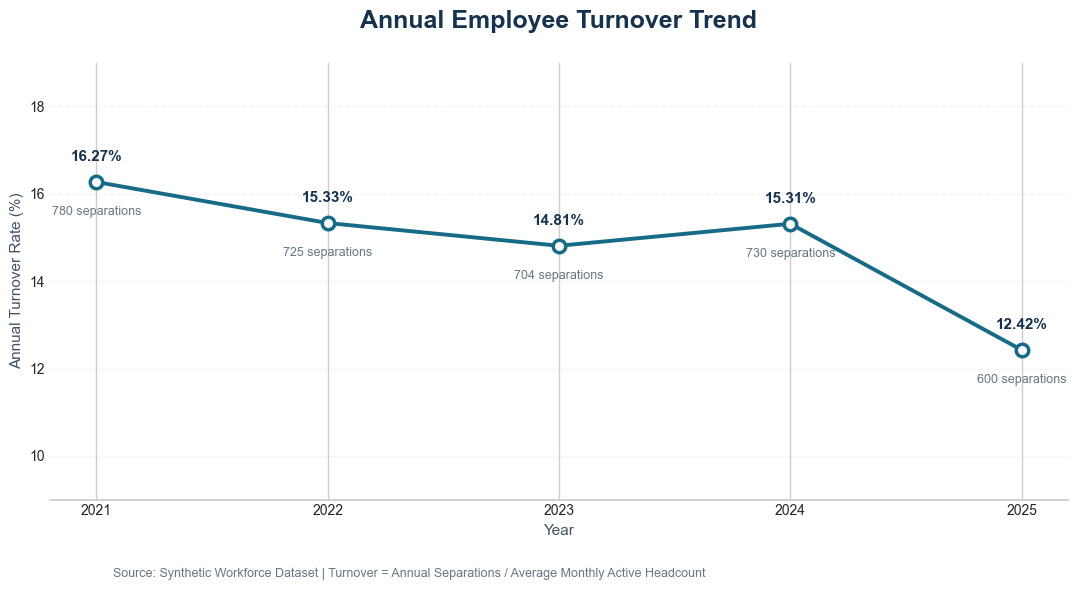

VISUALIZATION 01 — ANNUAL EMPLOYEE TURNOVER TREND
Saved File: c:\Projects\Raymond-James\1. workforce_data\reports\images\01_annual_turnover_trend.png
Years: 2021–2025
Starting Turnover Rate: 16.27%
Ending Turnover Rate: 12.42%
Change: -3.85 percentage points
Total Separations: 3,539


In [57]:

# =============================================================================
# VISUALIZATION 01 — ANNUAL EMPLOYEE TURNOVER TREND
# Phase 5 | Step 59
# Executive and Statistical Reporting
# =============================================================================

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# Identify the project directory from the notebook location.
current_dir = Path.cwd()

if current_dir.name.lower() == "notebooks":
    project_root = current_dir.parent.parent
else:
    project_root = current_dir

# Create an output directory for report visualizations.
output_dir = project_root / "reports" / "images"
output_dir.mkdir(parents=True, exist_ok=True)

# Prepare the validated annual turnover metrics.
years = annual.index.astype(int).to_numpy()
rates = annual["annual_turnover_rate_pct"].to_numpy()
separations = annual["annual_separations"].to_numpy()

# Create a professional, publication-ready figure.
fig, ax = plt.subplots(figsize=(11, 6))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# Plot annual turnover rates.
ax.plot(
    years,
    rates,
    color="#176B87",
    linewidth=2.8,
    marker="o",
    markersize=9,
    markerfacecolor="white",
    markeredgewidth=2.5
)

# Display rate and separation count for each year.
for year, rate, count in zip(years, rates, separations):
    ax.annotate(
        f"{rate:.2f}%",
        (year, rate),
        xytext=(0, 15),
        textcoords="offset points",
        ha="center",
        fontsize=11,
        fontweight="bold",
        color="#17324D"
    )

    ax.annotate(
        f"{count:,} separations",
        (year, rate),
        xytext=(0, -24),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        color="#687782"
    )

# Apply clean business-report styling.
ax.set_title(
    "Annual Employee Turnover Trend",
    fontsize=18,
    fontweight="bold",
    color="#17324D",
    pad=25
)

ax.set_ylabel(
    "Annual Turnover Rate (%)",
    fontsize=11,
    color="#415466"
)

ax.set_xlabel("Year", fontsize=11, color="#415466")

ax.set_xticks(years)
ax.set_ylim(9, 19)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.22
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.tick_params(axis="both", length=0, labelsize=10)

# Add source and methodology information.
fig.text(
    0.11, 0.025,
    "Source: Synthetic Workforce Dataset | "
    "Turnover = Annual Separations / Average Monthly Active Headcount",
    fontsize=9,
    color="#687782"
)

plt.tight_layout(rect=[0, 0.06, 1, 1])

# Save the figure for Markdown reports.
save_path = output_dir / "01_annual_turnover_trend.png"

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# Print a consolidated visualization summary.
print(
    "\n".join([
        "=" * 70,
        "VISUALIZATION 01 — ANNUAL EMPLOYEE TURNOVER TREND",
        "=" * 70,
        f"Saved File: {save_path}",
        f"Years: {years.min()}–{years.max()}",
        f"Starting Turnover Rate: {rates[0]:.2f}%",
        f"Ending Turnover Rate: {rates[-1]:.2f}%",
        f"Change: {rates[-1] - rates[0]:+.2f} percentage points",
        f"Total Separations: {separations.sum():,}",
        "=" * 70
    ])
)


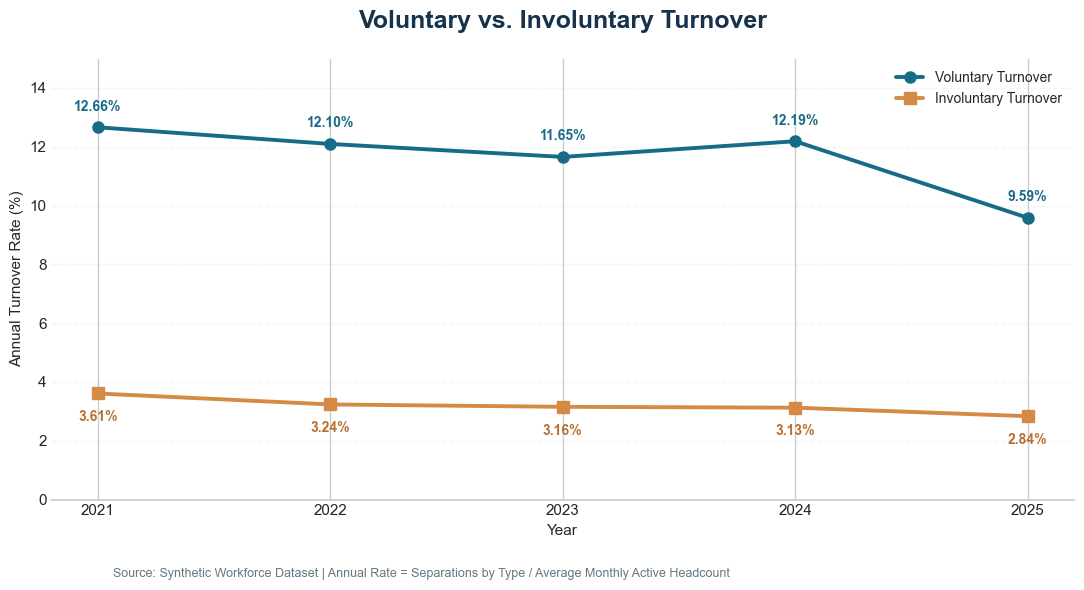

VISUALIZATION 02 — SEPARATION-TYPE TURNOVER
Saved File: c:\Projects\Raymond-James\1. workforce_data\reports\images\02_voluntary_involuntary_turnover.png

ANNUAL SEPARATION-TYPE METRICS
separation_category  Voluntary  Involuntary  Voluntary_Rate_Pct  Involuntary_Rate_Pct
year                                                                                 
2021                       607          173              12.662                 3.609
2022                       572          153              12.096                 3.235
2023                       554          150              11.655                 3.156
2024                       581          149              12.188                 3.126
2025                       463          137               9.587                 2.837

Total Voluntary Separations: 2,777
Total Involuntary Separations: 762


In [58]:

# =============================================================================
# VISUALIZATION 02 — VOLUNTARY VS. INVOLUNTARY TURNOVER
# Phase 5 | Step 60
# Annual Separation-Type Turnover Trend
# =============================================================================

import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

# Define the output directory.
current_dir = Path.cwd()

if current_dir.name.lower() == "notebooks":
    project_root = current_dir.parent.parent
else:
    project_root = current_dir

output_dir = project_root / "reports" / "images"
output_dir.mkdir(parents=True, exist_ok=True)

# Validate the calculated separation-type metrics from Step 60.
required_columns = [
    "Voluntary",
    "Involuntary",
    "Voluntary_Rate_Pct",
    "Involuntary_Rate_Pct"
]

missing = [
    col for col in required_columns
    if col not in yearly_types.columns
]

if missing:
    raise ValueError(f"Missing Step 60 metrics: {missing}")

# Prepare annual turnover metrics.
plot_data = yearly_types.sort_index().copy()

years = plot_data.index.astype(int).to_numpy()
voluntary_rates = plot_data["Voluntary_Rate_Pct"].to_numpy()
involuntary_rates = plot_data["Involuntary_Rate_Pct"].to_numpy()

# Create the visualization.
fig, ax = plt.subplots(figsize=(11, 6))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

ax.plot(
    years,
    voluntary_rates,
    marker="o",
    linewidth=2.8,
    markersize=8,
    color="#176B87",
    label="Voluntary Turnover"
)

ax.plot(
    years,
    involuntary_rates,
    marker="s",
    linewidth=2.8,
    markersize=8,
    color="#D58B45",
    label="Involuntary Turnover"
)

# Add direct value labels.
for year, rate in zip(years, voluntary_rates):
    ax.annotate(
        f"{rate:.2f}%",
        (year, rate),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold",
        color="#176B87"
    )

for year, rate in zip(years, involuntary_rates):
    ax.annotate(
        f"{rate:.2f}%",
        (year, rate),
        xytext=(0, -20),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold",
        color="#B87133"
    )

# Apply professional report styling.
ax.set_title(
    "Voluntary vs. Involuntary Turnover",
    fontsize=18,
    fontweight="bold",
    color="#17324D",
    pad=22
)

ax.set_ylabel("Annual Turnover Rate (%)", fontsize=11)
ax.set_xlabel("Year", fontsize=11)

ax.set_xticks(years)
ax.set_ylim(0, 15)

ax.legend(
    loc="upper right",
    frameon=False,
    fontsize=10
)

ax.grid(axis="y", linestyle="--", alpha=0.2)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.tick_params(axis="both", length=0)

# Document the methodology and data source.
fig.text(
    0.11, 0.025,
    "Source: Synthetic Workforce Dataset | "
    "Annual Rate = Separations by Type / Average Monthly Active Headcount",
    fontsize=9,
    color="#687782"
)

plt.tight_layout(rect=[0, 0.06, 1, 1])

# Export the visualization.
save_path = output_dir / "02_voluntary_involuntary_turnover.png"

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# Print all visualization metrics in one text output.
print(
    "\n".join([
        "=" * 75,
        "VISUALIZATION 02 — SEPARATION-TYPE TURNOVER",
        "=" * 75,
        f"Saved File: {save_path}",
        "",
        "ANNUAL SEPARATION-TYPE METRICS",
        plot_data[required_columns].round(3).to_string(),
        "",
        f"Total Voluntary Separations: {plot_data['Voluntary'].sum():,}",
        f"Total Involuntary Separations: {plot_data['Involuntary'].sum():,}",
        "=" * 75
    ])
)


In [59]:

# =============================================================================
# PHASE 5 — STEP 61
# TURNOVER & RETENTION ANALYSIS
# Turnover Segmentation by Department, Job Level, Location and Tenure
# =============================================================================

import pandas as pd
import numpy as np

output = []
output.append("=" * 85)
output.append("STEP 61 — WORKFORCE TURNOVER SEGMENTATION")
output.append("=" * 85)

# 1. Prepare the active workforce exposure population.
workforce = df_analysis.copy()
workforce.columns = workforce.columns.str.lower()

workforce["month_date"] = pd.to_datetime(workforce["month_date"])
workforce["year"] = workforce["month_date"].dt.year

active = workforce[
    workforce["employment_status"].eq("Active")
].copy()

# 2. Prepare and classify validated separation records.
sep = separation_history.copy()
sep.columns = sep.columns.str.lower()

sep["employee_id"] = sep["employee_id"].astype("string").str.strip()
sep["termination_date"] = pd.to_datetime(
    sep["termination_date"], errors="coerce"
)

valid_ids = set(
    latest_employee_records.loc[
        latest_employee_records["employment_status"].eq("Terminated"),
        "employee_id"
    ].astype("string").str.strip()
)

sep = sep[sep["employee_id"].isin(valid_ids)].copy()

sep["year"] = sep["termination_date"].dt.year
sep["separation_category"] = (
    sep["termination_type"].astype("string").str.strip()
)

# 3. Derive mutually exclusive tenure segments.
tenure_column = next(
    (
        col for col in active.columns
        if col in ["organizational_tenure_months", "tenure_months"]
    ),
    None
)

if tenure_column:
    active["turnover_tenure_group"] = pd.cut(
        active[tenure_column],
        bins=[-1, 12, 36, 60, 120, np.inf],
        labels=["0–1 Year", "1–3 Years", "3–5 Years",
                "5–10 Years", "10+ Years"]
    )

sep["turnover_tenure_group"] = pd.cut(
    sep["tenure_at_exit_months"],
    bins=[-1, 12, 36, 60, 120, np.inf],
    labels=["0–1 Year", "1–3 Years", "3–5 Years",
            "5–10 Years", "10+ Years"]
)

# 4. Define compatible segmentation dimensions.
dimensions = [
    ("department", "Department"),
    ("job_level", "Job Level"),
    ("location", "Location"),
    ("turnover_tenure_group", "Tenure")
]

for column, title in dimensions:

    output.append("\n" + "-" * 85)
    output.append(f"{title.upper()} — TURNOVER SEGMENTATION")
    output.append("-" * 85)

    if column not in active.columns or column not in sep.columns:
        output.append(
            f"SKIPPED: '{column}' unavailable in one of the sources."
        )
        continue

    # Count observed active employee-months by segment.
    exposure = (
        active.groupby(column, observed=True)
        .size()
        .rename("Active_Employee_Months")
    )

    # Count employee separations by segment and category.
    separation_counts = pd.crosstab(
        sep[column],
        sep["separation_category"]
    )

    result = exposure.to_frame().join(
        separation_counts, how="outer"
    ).fillna(0)

    for category in ["Voluntary", "Involuntary"]:
        if category not in result.columns:
            result[category] = 0

    result["Total_Separations"] = (
        result["Voluntary"] + result["Involuntary"]
    )

    # Annualized separation incidence per active employee-month exposure.
    result["Annualized_Turnover_Pct"] = np.where(
        result["Active_Employee_Months"] > 0,
        result["Total_Separations"] * 12 /
        result["Active_Employee_Months"] * 100,
        np.nan
    )

    result["Voluntary_Turnover_Pct"] = np.where(
        result["Active_Employee_Months"] > 0,
        result["Voluntary"] * 12 /
        result["Active_Employee_Months"] * 100,
        np.nan
    )

    # Require at least 120 active employee-months for rate ranking.
    eligible = result[
        result["Active_Employee_Months"] >= 120
    ].sort_values("Annualized_Turnover_Pct", ascending=False)

    output.append(
        f"\nSegments: {len(result)} | "
        f"Eligible for Rate Ranking: {len(eligible)}"
    )

    output.append("\nHIGHEST ANNUALIZED TURNOVER RATES")
    output.append(
        eligible[
            [
                "Active_Employee_Months",
                "Total_Separations",
                "Voluntary",
                "Involuntary",
                "Annualized_Turnover_Pct",
                "Voluntary_Turnover_Pct"
            ]
        ].head(15).round(2).to_string()
    )

    output.append("\nLARGEST SEPARATION COUNTS")
    output.append(
        result.sort_values(
            "Total_Separations", ascending=False
        )[
            [
                "Active_Employee_Months",
                "Total_Separations",
                "Annualized_Turnover_Pct"
            ]
        ].head(10).round(2).to_string()
    )

output.append("\n" + "=" * 85)
output.append("STEP 61 SEGMENTATION COMPLETE")
output.append("=" * 85)

# Print all results in one consolidated output.
print("\n".join(output))


STEP 61 — WORKFORCE TURNOVER SEGMENTATION

-------------------------------------------------------------------------------------
DEPARTMENT — TURNOVER SEGMENTATION
-------------------------------------------------------------------------------------

Segments: 8 | Eligible for Rate Ranking: 8

HIGHEST ANNUALIZED TURNOVER RATES
                    Active_Employee_Months  Total_Separations  Voluntary  Involuntary  Annualized_Turnover_Pct  Voluntary_Turnover_Pct
department                                                                                                                            
Human Resources                      16455                219        163           56                    15.97                   11.89
Corporate Services                   25780                334        265           69                    15.55                   12.34
Risk & Compliance                    20621                262        205           57                    15.25                   11

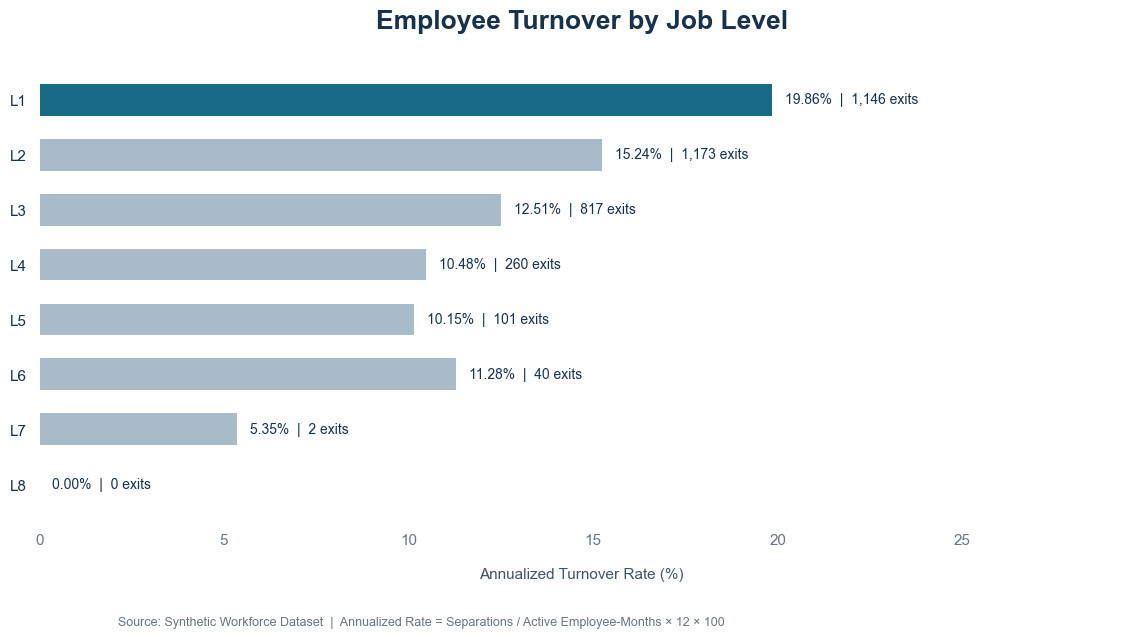

VISUALIZATION 03 — EMPLOYEE TURNOVER BY JOB LEVEL
Saved File: c:\Projects\Raymond-James\1. workforce_data\reports\images\03_turnover_by_job_level.png

           Employee_Months  Separations  Annualized_Turnover_Pct
job_level                                                       
L1                   69258       1146.0                   19.856
L2                   92339       1173.0                   15.244
L3                   78393        817.0                   12.506
L4                   29782        260.0                   10.476
L5                   11939        101.0                   10.152
L6                    4255         40.0                   11.281
L7                     449          2.0                    5.345
L8                      60          0.0                    0.000

Total Separations: 3,539


In [60]:

# =============================================================================
# VISUALIZATION 03 — EMPLOYEE TURNOVER BY JOB LEVEL
# Phase 5 | Step 61
# Annualized Turnover Rate and Separation Volume
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Configure the visualization output directory.
current_dir = Path.cwd()

project_root = (
    current_dir.parent.parent
    if current_dir.name.lower() == "notebooks"
    else current_dir
)

output_dir = project_root / "reports" / "images"
output_dir.mkdir(parents=True, exist_ok=True)

# 2. Calculate active employee-month exposure by job level.
active_records = df_analysis.loc[
    df_analysis["employment_status"].eq("Active")
].copy()

active_exposure = (
    active_records.groupby("job_level")
    .size()
    .rename("Employee_Months")
)

# 3. Retrieve validated employee separations.
valid_ids = set(
    latest_employee_records.loc[
        latest_employee_records["employment_status"].eq("Terminated"),
        "employee_id"
    ].astype(str).str.strip()
)

separations = separation_history.copy()
separations.columns = separations.columns.str.lower()

separations["employee_id"] = (
    separations["employee_id"].astype(str).str.strip()
)

separations = separations[
    separations["employee_id"].isin(valid_ids)
].copy()

separation_counts = (
    separations.groupby("job_level")
    .size()
    .rename("Separations")
)

# 4. Calculate annualized turnover rates.
job_level_metrics = (
    active_exposure.to_frame()
    .join(separation_counts, how="outer")
    .fillna(0)
)

job_level_metrics["Annualized_Turnover_Pct"] = np.where(
    job_level_metrics["Employee_Months"] > 0,
    job_level_metrics["Separations"] * 12 /
    job_level_metrics["Employee_Months"] * 100,
    np.nan
)

job_level_metrics = job_level_metrics.sort_index()

# 5. Prepare visualization data.
levels = job_level_metrics.index.astype(str).tolist()
rates = job_level_metrics["Annualized_Turnover_Pct"].to_numpy()
counts = job_level_metrics["Separations"].to_numpy()

# Create a clean, publication-ready horizontal bar chart.
fig, ax = plt.subplots(figsize=(11.5, 6.5))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# Highlight the highest-turnover job level.
colors = [
    "#176B87" if level == "L1" else "#A8BBC8"
    for level in levels
]

bars = ax.barh(
    levels,
    rates,
    color=colors,
    height=0.58,
    edgecolor="none",
    zorder=3
)

# 6. Add clear turnover rate and separation count labels.
for bar, rate, count in zip(bars, rates, counts):

    ax.text(
        bar.get_width() + 0.35,
        bar.get_y() + bar.get_height() / 2,
        f"{rate:.2f}%  |  {int(count):,} exits",
        va="center",
        ha="left",
        fontsize=10,
        color="#17324D",
        fontweight="medium"
    )

# 7. Apply clean executive-report styling.
ax.invert_yaxis()

ax.set_title(
    "Employee Turnover by Job Level",
    fontsize=19,
    fontweight="bold",
    color="#17324D",
    pad=25
)

ax.set_xlabel(
    "Annualized Turnover Rate (%)",
    fontsize=11,
    color="#415466",
    labelpad=14
)

ax.set_xlim(0, max(rates) * 1.48)

# Remove all gridlines, including inherited style settings.
ax.grid(False)
ax.xaxis.grid(False, which="both")
ax.yaxis.grid(False, which="both")

# Remove all surrounding axis lines.
for spine in ax.spines.values():
    spine.set_visible(False)

# Remove tick marks while preserving readable labels.
ax.tick_params(
    axis="both",
    which="both",
    length=0,
    labelsize=11,
    pad=9
)

ax.tick_params(axis="y", colors="#17324D")
ax.tick_params(axis="x", colors="#687782")

# Set clean horizontal-axis tick intervals.
ax.set_xticks(np.arange(0, 26, 5))

# 8. Add methodology and data source information.
fig.text(
    0.11,
    0.025,
    "Source: Synthetic Workforce Dataset  |  "
    "Annualized Rate = Separations / Active Employee-Months × 12 × 100",
    fontsize=9,
    color="#687782"
)

plt.tight_layout(rect=[0, 0.065, 1, 1])

# 9. Export the updated visualization.
save_path = output_dir / "03_turnover_by_job_level.png"

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# 10. Print all visualization metrics in one consolidated output.
print(
    "\n".join([
        "=" * 80,
        "VISUALIZATION 03 — EMPLOYEE TURNOVER BY JOB LEVEL",
        "=" * 80,
        f"Saved File: {save_path}",
        "",
        job_level_metrics.round(3).to_string(),
        "",
        f"Total Separations: {int(counts.sum()):,}",
        "=" * 80
    ])
)


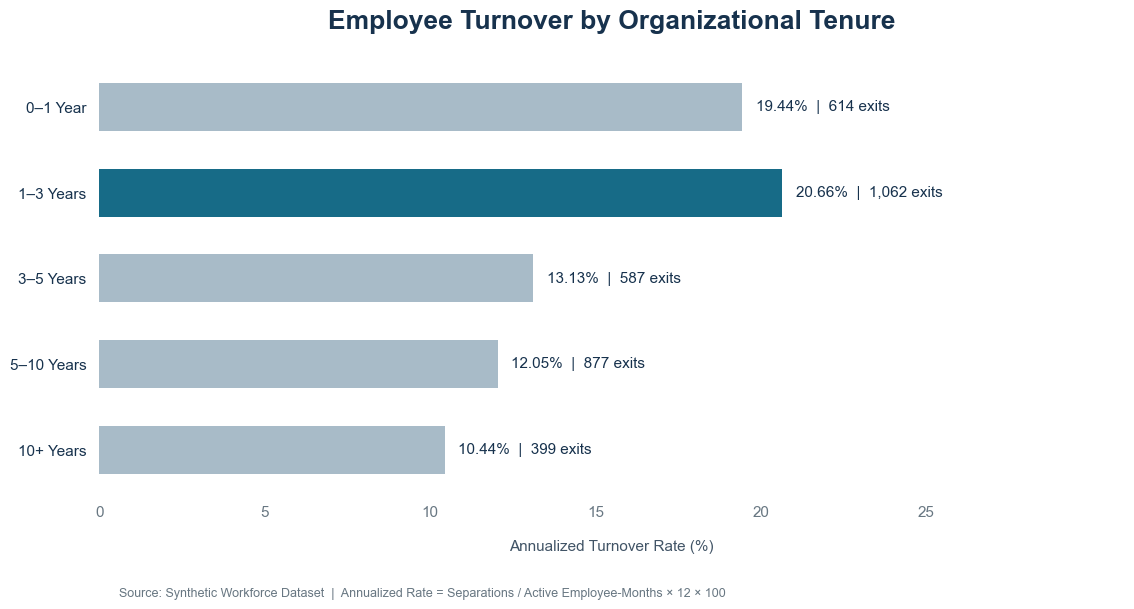

VISUALIZATION 04 — EMPLOYEE TURNOVER BY TENURE
Saved File: c:\Projects\Raymond-James\1. workforce_data\reports\images\04_turnover_by_tenure.png

                Employee_Months  Separations  Annualized_Turnover_Pct
tenure_segment                                                       
0–1 Year                  37894          614                   19.444
1–3 Years                 61699         1062                   20.655
3–5 Years                 53659          587                   13.127
5–10 Years                87358          877                   12.047
10+ Years                 45865          399                   10.439

Highest Turnover Segment: 1–3 Years
Highest Annualized Rate: 20.66%
Total Separations: 3,539


In [61]:

# =============================================================================
# VISUALIZATION 04 — EMPLOYEE TURNOVER BY ORGANIZATIONAL TENURE
# Phase 5 | Step 61
# Annualized Turnover Rate by Employee Tenure
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Configure the visualization output directory.
current_dir = Path.cwd()

project_root = (
    current_dir.parent.parent
    if current_dir.name.lower() == "notebooks"
    else current_dir
)

output_dir = project_root / "reports" / "images"
output_dir.mkdir(parents=True, exist_ok=True)

# 2. Prepare active employee-month exposure.
active_records = df_analysis.loc[
    df_analysis["employment_status"].eq("Active")
].copy()

# Define consistent tenure categories.
tenure_labels = [
    "0–1 Year",
    "1–3 Years",
    "3–5 Years",
    "5–10 Years",
    "10+ Years"
]

tenure_bins = [-1, 12, 36, 60, 120, np.inf]

active_records["tenure_segment"] = pd.cut(
    active_records["organizational_tenure_months"],
    bins=tenure_bins,
    labels=tenure_labels
)

active_exposure = (
    active_records.groupby("tenure_segment", observed=True)
    .size()
    .reindex(tenure_labels, fill_value=0)
    .rename("Employee_Months")
)

# 3. Prepare validated employee separations.
valid_ids = set(
    latest_employee_records.loc[
        latest_employee_records["employment_status"].eq("Terminated"),
        "employee_id"
    ].astype(str).str.strip()
)

separations = separation_history.copy()
separations.columns = separations.columns.str.lower()

separations["employee_id"] = (
    separations["employee_id"].astype(str).str.strip()
)

separations = separations[
    separations["employee_id"].isin(valid_ids)
].copy()

separations["tenure_segment"] = pd.cut(
    pd.to_numeric(
        separations["tenure_at_exit_months"],
        errors="coerce"
    ),
    bins=tenure_bins,
    labels=tenure_labels
)

separation_counts = (
    separations.groupby("tenure_segment", observed=True)
    .size()
    .reindex(tenure_labels, fill_value=0)
    .rename("Separations")
)

# 4. Calculate annualized turnover incidence.
tenure_metrics = pd.concat(
    [active_exposure, separation_counts],
    axis=1
).fillna(0)

tenure_metrics["Annualized_Turnover_Pct"] = np.where(
    tenure_metrics["Employee_Months"] > 0,
    tenure_metrics["Separations"] * 12 /
    tenure_metrics["Employee_Months"] * 100,
    np.nan
)

# 5. Prepare plotting values.
labels = tenure_metrics.index.astype(str).tolist()
rates = tenure_metrics["Annualized_Turnover_Pct"].to_numpy()
counts = tenure_metrics["Separations"].to_numpy()

highest_index = int(np.nanargmax(rates))

# 6. Create a clean horizontal bar chart.
fig, ax = plt.subplots(figsize=(11.5, 6.2))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

colors = [
    "#176B87" if i == highest_index else "#A8BBC8"
    for i in range(len(labels))
]

bars = ax.barh(
    labels,
    rates,
    height=0.56,
    color=colors,
    edgecolor="none"
)

# 7. Annotate turnover percentages and separation counts.
for bar, rate, count in zip(bars, rates, counts):
    ax.text(
        bar.get_width() + 0.4,
        bar.get_y() + bar.get_height() / 2,
        f"{rate:.2f}%  |  {int(count):,} exits",
        ha="left",
        va="center",
        fontsize=11,
        color="#17324D"
    )

# 8. Apply publication-ready styling.
ax.invert_yaxis()

ax.set_title(
    "Employee Turnover by Organizational Tenure",
    fontsize=19,
    fontweight="bold",
    color="#17324D",
    pad=25
)

ax.set_xlabel(
    "Annualized Turnover Rate (%)",
    fontsize=11,
    color="#415466",
    labelpad=14
)

ax.set_xlim(0, max(rates) * 1.5)
ax.set_xticks(np.arange(0, 26, 5))

# Remove all gridlines and plot borders.
ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    which="both",
    length=0,
    labelsize=11,
    pad=9
)

ax.tick_params(axis="y", colors="#17324D")
ax.tick_params(axis="x", colors="#687782")

# 9. Add source and methodology notes.
fig.text(
    0.11,
    0.025,
    "Source: Synthetic Workforce Dataset  |  "
    "Annualized Rate = Separations / Active Employee-Months × 12 × 100",
    fontsize=9,
    color="#687782"
)

plt.tight_layout(rect=[0, 0.065, 1, 1])

# 10. Save the visualization.
save_path = output_dir / "04_turnover_by_tenure.png"

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# 11. Print all visualization metrics in one consolidated output.
print(
    "\n".join([
        "=" * 80,
        "VISUALIZATION 04 — EMPLOYEE TURNOVER BY TENURE",
        "=" * 80,
        f"Saved File: {save_path}",
        "",
        tenure_metrics.round(3).to_string(),
        "",
        f"Highest Turnover Segment: {labels[highest_index]}",
        f"Highest Annualized Rate: {rates[highest_index]:.2f}%",
        f"Total Separations: {int(counts.sum()):,}",
        "=" * 80
    ])
)


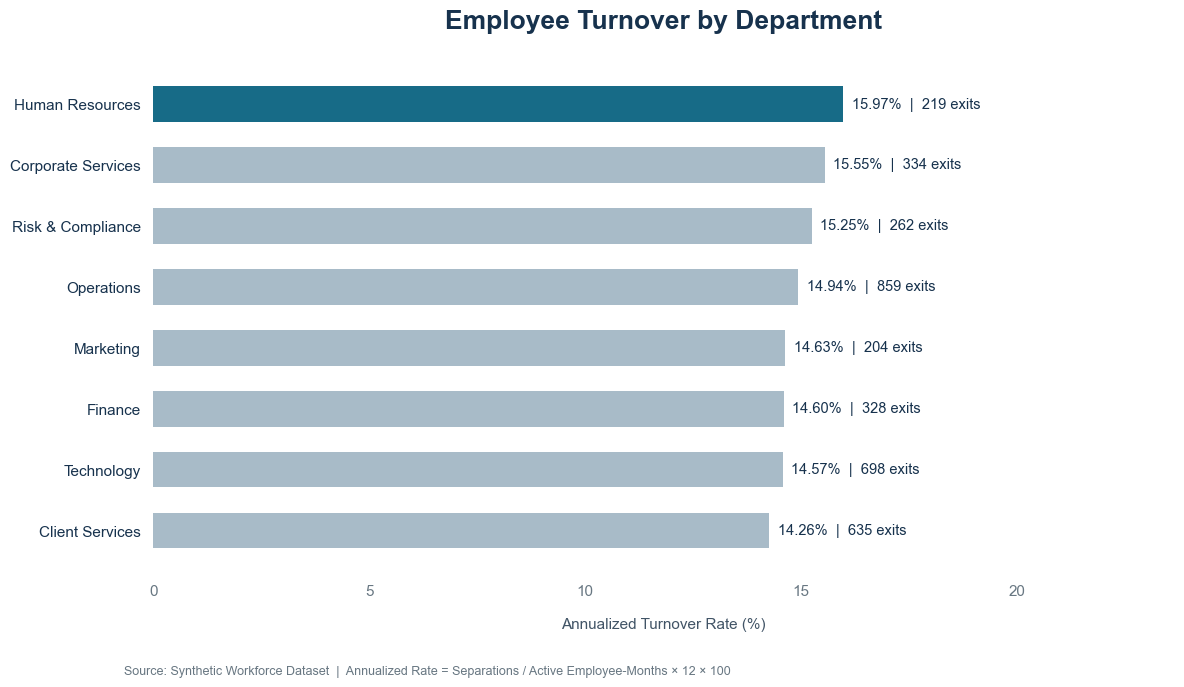

VISUALIZATION 09 — EMPLOYEE TURNOVER BY DEPARTMENT
Saved File: c:\Projects\Raymond-James\1. workforce_data\reports\images\09_turnover_by_department.png

                    Employee_Months  Separations  Annualized_Turnover_Pct
department                                                               
Human Resources               16455          219                   15.971
Corporate Services            25780          334                   15.547
Risk & Compliance             20621          262                   15.247
Operations                    69009          859                   14.937
Marketing                     16730          204                   14.632
Finance                       26956          328                   14.602
Technology                    57481          698                   14.572
Client Services               53443          635                   14.258

Highest Turnover Department: Human Resources
Highest Annualized Rate: 15.97%


In [63]:

# =============================================================================
# VISUALIZATION 09 — EMPLOYEE TURNOVER BY DEPARTMENT
# Phase 5 | Step 61
# Department-Level Annualized Turnover and Separation Volume
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Configure the visualization output directory.
current_dir = Path.cwd()

project_root = (
    current_dir.parent.parent
    if current_dir.name.lower() == "notebooks"
    else current_dir
)

output_dir = project_root / "reports" / "images"
output_dir.mkdir(parents=True, exist_ok=True)

# 2. Calculate active employee-month exposure by department.
active_records = df_analysis.loc[
    df_analysis["employment_status"].eq("Active")
].copy()

active_exposure = (
    active_records.groupby("department")
    .size()
    .rename("Employee_Months")
)

# 3. Prepare validated separation records.
valid_ids = set(
    latest_employee_records.loc[
        latest_employee_records["employment_status"].eq("Terminated"),
        "employee_id"
    ].astype(str).str.strip()
)

separations = separation_history.copy()
separations.columns = separations.columns.str.lower()

separations["employee_id"] = (
    separations["employee_id"].astype(str).str.strip()
)

separations = separations[
    separations["employee_id"].isin(valid_ids)
].copy()

separation_counts = (
    separations.groupby("department")
    .size()
    .rename("Separations")
)

# 4. Calculate annualized turnover by department.
department_metrics = (
    active_exposure.to_frame()
    .join(separation_counts, how="outer")
    .fillna(0)
)

department_metrics["Annualized_Turnover_Pct"] = np.where(
    department_metrics["Employee_Months"] > 0,
    department_metrics["Separations"] * 12 /
    department_metrics["Employee_Months"] * 100,
    np.nan
)

department_metrics = department_metrics.sort_values(
    "Annualized_Turnover_Pct", ascending=False
)

# 5. Prepare visualization values.
labels = department_metrics.index.astype(str).tolist()
rates = department_metrics["Annualized_Turnover_Pct"].to_numpy()
counts = department_metrics["Separations"].to_numpy()

# 6. Create the horizontal bar chart.
fig, ax = plt.subplots(figsize=(12, 7))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

colors = [
    "#176B87" if i == 0 else "#A8BBC8"
    for i in range(len(labels))
]

bars = ax.barh(
    labels,
    rates,
    color=colors,
    height=0.58,
    edgecolor="none"
)

# Add turnover rates and separation counts.
for bar, rate, count in zip(bars, rates, counts):
    ax.text(
        bar.get_width() + 0.2,
        bar.get_y() + bar.get_height() / 2,
        f"{rate:.2f}%  |  {int(count):,} exits",
        ha="left",
        va="center",
        fontsize=10.5,
        color="#17324D"
    )

# 7. Apply clean report styling.
ax.invert_yaxis()

ax.set_title(
    "Employee Turnover by Department",
    fontsize=19,
    fontweight="bold",
    color="#17324D",
    pad=25
)

ax.set_xlabel(
    "Annualized Turnover Rate (%)",
    fontsize=11,
    color="#415466",
    labelpad=14
)

ax.set_xlim(0, np.nanmax(rates) * 1.48)

# Remove all gridlines and chart borders.
ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    which="both",
    length=0,
    labelsize=11,
    pad=9
)

ax.tick_params(axis="y", colors="#17324D")
ax.tick_params(axis="x", colors="#687782")

# 8. Add source and methodology notes.
fig.text(
    0.11,
    0.025,
    "Source: Synthetic Workforce Dataset  |  "
    "Annualized Rate = Separations / Active Employee-Months × 12 × 100",
    fontsize=9,
    color="#687782"
)

plt.tight_layout(rect=[0, 0.06, 1, 1])

# 9. Export the visualization.
save_path = output_dir / "09_turnover_by_department.png"

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# 10. Print all results in one consolidated text output.
print(
    "\n".join([
        "=" * 80,
        "VISUALIZATION 09 — EMPLOYEE TURNOVER BY DEPARTMENT",
        "=" * 80,
        f"Saved File: {save_path}",
        "",
        department_metrics.round(3).to_string(),
        "",
        f"Highest Turnover Department: {labels[0]}",
        f"Highest Annualized Rate: {rates[0]:.2f}%",
        "=" * 80
    ])
)


In [65]:

# =============================================================================
# PHASE 5 — STEP 62
# TURNOVER & RETENTION ANALYSIS
# Compensation, Performance & Time in Current Role Before Separation
# =============================================================================

import pandas as pd
import numpy as np

output = []
output.append("=" * 85)
output.append("STEP 62 — PRE-SEPARATION WORKFORCE FACTOR ANALYSIS")
output.append("=" * 85)

# 1. Prepare monthly workforce observations.
panel = df_analysis.copy()
panel.columns = panel.columns.str.lower()
panel["month_date"] = pd.to_datetime(panel["month_date"])

panel = panel.sort_values(["employee_id", "month_date"])

# 2. Identify termination records.
termination_dates = (
    panel.loc[
        panel["employment_status"].eq("Terminated"),
        ["employee_id", "month_date"]
    ]
    .drop_duplicates("employee_id")
    .rename(columns={"month_date": "termination_month"})
)

# 3. Select active employee-month observations.
active_panel = panel[
    panel["employment_status"].eq("Active")
].copy()

# 4. Link future termination outcome without using future predictors.
active_panel = active_panel.merge(
    termination_dates,
    on="employee_id",
    how="left",
    validate="many_to_one"
)

active_panel["next_month"] = (
    active_panel["month_date"] + pd.offsets.MonthBegin(1)
)

active_panel["exit_next_month"] = (
    active_panel["termination_month"].eq(active_panel["next_month"])
).astype(int)

# Exclude the last observation month (future outcome unavailable).
last_month = active_panel["month_date"].max()

analysis_panel = active_panel[
    active_panel["month_date"] < last_month
].copy()

output.append("\n1. ANALYTICAL POPULATION")
output.append(f"Active Employee-Month Observations: {len(analysis_panel):,}")
output.append(f"Next-Month Separation Events: {analysis_panel['exit_next_month'].sum():,}")
output.append(
    f"Next-Month Separation Rate: "
    f"{analysis_panel['exit_next_month'].mean() * 100:.3f}%"
)

# 5. Define nonredundant workforce risk factors.
# Role tenure replaces the identical promotion-timing source field.
factors = {
    "compa_ratio": {
        "bins": [-np.inf, 0.8, 0.9, 1.0, 1.1, np.inf],
        "labels": ["<0.80", "0.80–0.89", "0.90–0.99",
                   "1.00–1.09", "1.10+"]
    },
    "latest_performance_rating": {
        "bins": [-np.inf, 2, 3, 4, np.inf],
        "labels": ["Low (≤2)", "3", "4", "High (>4)"]
    },
    "role_tenure_months": {
        "bins": [-np.inf, 12, 24, 48, np.inf],
        "labels": ["0–12 Months", "13–24 Months",
                   "25–48 Months", "49+ Months"]
    }
}

# 6. Calculate next-month separation rates by factor.
for column, config in factors.items():

    output.append("\n" + "-" * 85)
    output.append(f"FACTOR: {column.upper()}")
    output.append("-" * 85)

    if column not in analysis_panel.columns:
        output.append("SKIPPED: Column unavailable.")
        continue

    values = pd.to_numeric(
        analysis_panel[column], errors="coerce"
    )

    groups = pd.cut(
        values,
        bins=config["bins"],
        labels=config["labels"],
        include_lowest=True
    )

    groups = groups.astype("object").fillna("Missing")

    summary = (
        analysis_panel
        .assign(factor_group=groups)
        .groupby("factor_group")
        .agg(
            Employee_Months=("employee_id", "size"),
            Separations_Next_Month=("exit_next_month", "sum"),
            Separation_Rate=("exit_next_month", "mean")
        )
    )

    summary["Separation_Rate_Pct"] = (
        summary["Separation_Rate"] * 100
    )

    summary["Annualized_Rate_Pct"] = (
        summary["Separation_Rate"] * 12 * 100
    )

    output.append(
        summary[
            [
                "Employee_Months",
                "Separations_Next_Month",
                "Separation_Rate_Pct",
                "Annualized_Rate_Pct"
            ]
        ].round(3).to_string()
    )

output.append("\n" + "=" * 85)
output.append("STEP 62 ANALYSIS COMPLETE")
output.append("=" * 85)

# Print all results in one consolidated output.
print("\n".join(output))


STEP 62 — PRE-SEPARATION WORKFORCE FACTOR ANALYSIS

1. ANALYTICAL POPULATION
Active Employee-Month Observations: 281,608
Next-Month Separation Events: 3,415
Next-Month Separation Rate: 1.213%

-------------------------------------------------------------------------------------
FACTOR: COMPA_RATIO
-------------------------------------------------------------------------------------
              Employee_Months  Separations_Next_Month  Separation_Rate_Pct  Annualized_Rate_Pct
factor_group                                                                                   
0.80–0.89               48563                     675                1.390               16.679
0.90–0.99               84560                    1116                1.320               15.837
1.00–1.09               79888                     923                1.155               13.864
1.10+                   61297                     589                0.961               11.531
<0.80                    7300          

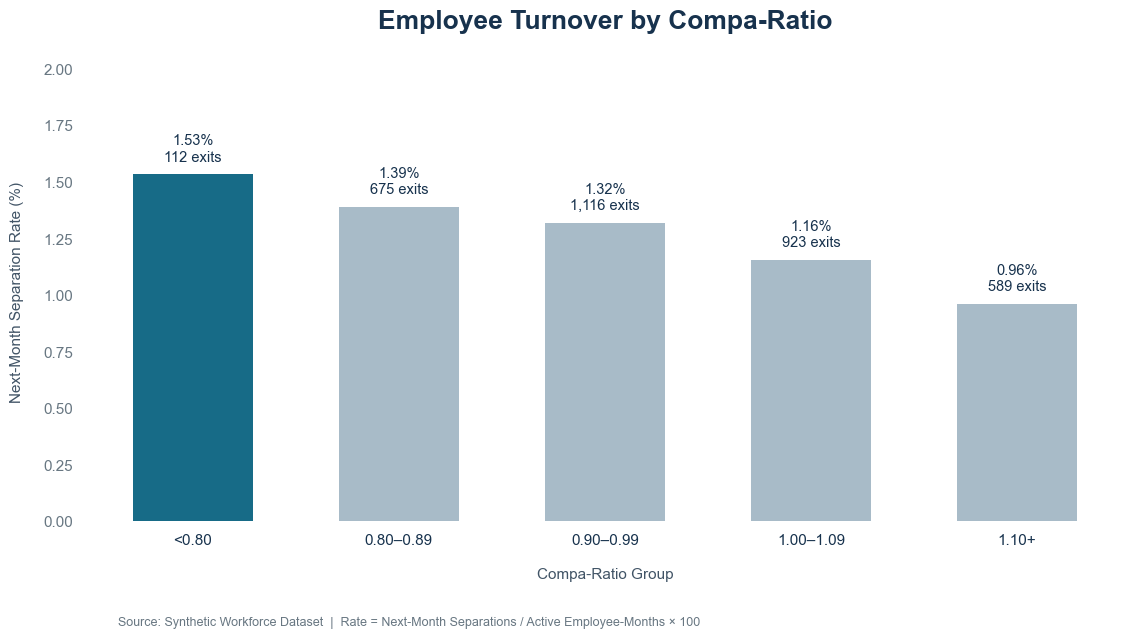

VISUALIZATION 05 — COMPA-RATIO VS. EMPLOYEE TURNOVER
Saved File: c:\Projects\Raymond-James\1. workforce_data\reports\images\05_turnover_by_compa_ratio.png

               Employee_Months  Separations  Separation_Rate_Pct
compa_segment                                                   
<0.80                     7300          112               1.5342
0.80–0.89                48563          675               1.3899
0.90–0.99                84560         1116               1.3198
1.00–1.09                79888          923               1.1554
1.10+                    61297          589               0.9609

Highest Separation Rate: <0.80
Highest Rate: 1.534%


In [66]:

# =============================================================================
# VISUALIZATION 05 — COMPA-RATIO VS. EMPLOYEE TURNOVER
# Phase 5 | Step 62
# Next-Month Separation Rate by Compensation Position
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Configure the report visualization directory.
current_dir = Path.cwd()

project_root = (
    current_dir.parent.parent
    if current_dir.name.lower() == "notebooks"
    else current_dir
)

output_dir = project_root / "reports" / "images"
output_dir.mkdir(parents=True, exist_ok=True)

# 2. Use the validated pre-separation analytical population.
df = analysis_panel.copy()

# Define compensation positioning categories.
group_labels = [
    "<0.80",
    "0.80–0.89",
    "0.90–0.99",
    "1.00–1.09",
    "1.10+"
]

df["compa_segment"] = pd.cut(
    pd.to_numeric(df["compa_ratio"], errors="coerce"),
    bins=[-np.inf, 0.8, 0.9, 1.0, 1.1, np.inf],
    labels=group_labels,
    include_lowest=True
)

# 3. Calculate next-month separation incidence by group.
compa_metrics = (
    df.groupby("compa_segment", observed=True)
    .agg(
        Employee_Months=("employee_id", "size"),
        Separations=("exit_next_month", "sum")
    )
    .reindex(group_labels)
)

compa_metrics["Separation_Rate_Pct"] = (
    compa_metrics["Separations"] /
    compa_metrics["Employee_Months"] * 100
)

# 4. Prepare visualization values.
labels = compa_metrics.index.astype(str).tolist()
rates = compa_metrics["Separation_Rate_Pct"].to_numpy()
counts = compa_metrics["Separations"].to_numpy()

# 5. Create a clean vertical bar chart.
fig, ax = plt.subplots(figsize=(11.5, 6.5))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# Highlight the lowest compensation-position group.
colors = [
    "#176B87" if label == "<0.80" else "#A8BBC8"
    for label in labels
]

bars = ax.bar(
    labels,
    rates,
    color=colors,
    width=0.58,
    edgecolor="none"
)

# 6. Annotate rates and separation event counts.
for bar, rate, count in zip(bars, rates, counts):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.045,
        f"{rate:.2f}%\n{int(count):,} exits",
        ha="center",
        va="bottom",
        fontsize=10.5,
        color="#17324D",
        fontweight="medium"
    )

# 7. Apply publication-ready styling.
ax.set_title(
    "Employee Turnover by Compa-Ratio",
    fontsize=19,
    fontweight="bold",
    color="#17324D",
    pad=25
)

ax.set_xlabel(
    "Compa-Ratio Group",
    fontsize=11,
    color="#415466",
    labelpad=14
)

ax.set_ylabel(
    "Next-Month Separation Rate (%)",
    fontsize=11,
    color="#415466",
    labelpad=14
)

ax.set_ylim(0, max(rates) * 1.32)

# Remove all gridlines and plot borders.
ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    which="both",
    length=0,
    labelsize=11,
    pad=9
)

ax.tick_params(axis="x", colors="#17324D")
ax.tick_params(axis="y", colors="#687782")

# 8. Add methodology notes.
fig.text(
    0.11,
    0.025,
    "Source: Synthetic Workforce Dataset  |  "
    "Rate = Next-Month Separations / Active Employee-Months × 100",
    fontsize=9,
    color="#687782"
)

plt.tight_layout(rect=[0, 0.065, 1, 1])

# 9. Save the visualization.
save_path = output_dir / "05_turnover_by_compa_ratio.png"

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# 10. Print all results in one consolidated text output.
print(
    "\n".join([
        "=" * 80,
        "VISUALIZATION 05 — COMPA-RATIO VS. EMPLOYEE TURNOVER",
        "=" * 80,
        f"Saved File: {save_path}",
        "",
        compa_metrics.round(4).to_string(),
        "",
        f"Highest Separation Rate: {labels[np.nanargmax(rates)]}",
        f"Highest Rate: {np.nanmax(rates):.3f}%",
        "=" * 80
    ])
)


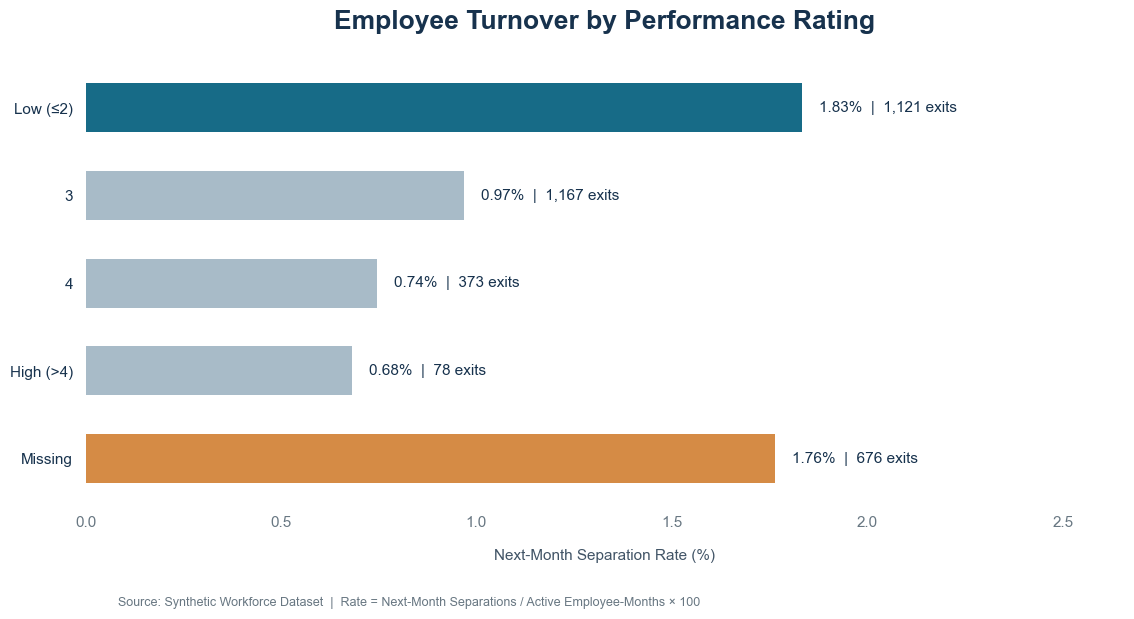

VISUALIZATION 06 — PERFORMANCE RATING VS. TURNOVER
Saved File: c:\Projects\Raymond-James\1. workforce_data\reports\images\06_turnover_by_performance.png

                     Employee_Months  Separations  Separation_Rate_Pct
performance_segment                                                   
Low (≤2)                       61176         1121               1.8324
3                             120569         1167               0.9679
4                              50085          373               0.7447
High (>4)                      11450           78               0.6812
Missing                        38328          676               1.7637

Highest Separation Rate: Low (≤2)
Highest Rate: 1.832%


In [67]:

# =============================================================================
# VISUALIZATION 06 — PERFORMANCE RATING VS. EMPLOYEE TURNOVER
# Phase 5 | Step 62
# Next-Month Separation Rate by Employee Performance Rating
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Configure the visualization output directory.
current_dir = Path.cwd()

project_root = (
    current_dir.parent.parent
    if current_dir.name.lower() == "notebooks"
    else current_dir
)

output_dir = project_root / "reports" / "images"
output_dir.mkdir(parents=True, exist_ok=True)

# 2. Prepare the validated pre-separation analytical population.
df = analysis_panel.copy()

performance_labels = [
    "Low (≤2)",
    "3",
    "4",
    "High (>4)",
    "Missing"
]

# Group performance ratings consistently with Step 62.
performance_values = pd.to_numeric(
    df["latest_performance_rating"],
    errors="coerce"
)

df["performance_segment"] = pd.cut(
    performance_values,
    bins=[-np.inf, 2, 3, 4, np.inf],
    labels=performance_labels[:-1],
    include_lowest=True
).astype("object").fillna("Missing")

# 3. Calculate next-month separation rates.
performance_metrics = (
    df.groupby("performance_segment")
    .agg(
        Employee_Months=("employee_id", "size"),
        Separations=("exit_next_month", "sum")
    )
    .reindex(performance_labels, fill_value=0)
)

performance_metrics["Separation_Rate_Pct"] = np.where(
    performance_metrics["Employee_Months"] > 0,
    performance_metrics["Separations"] /
    performance_metrics["Employee_Months"] * 100,
    np.nan
)

# 4. Prepare visualization values.
labels = performance_metrics.index.tolist()
rates = performance_metrics["Separation_Rate_Pct"].to_numpy()
counts = performance_metrics["Separations"].to_numpy()

# 5. Create the horizontal bar chart.
fig, ax = plt.subplots(figsize=(11.5, 6.3))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# Highlight low performance and distinguish missing ratings.
colors = [
    "#176B87" if label == "Low (≤2)"
    else "#D58B45" if label == "Missing"
    else "#A8BBC8"
    for label in labels
]

bars = ax.barh(
    labels,
    rates,
    color=colors,
    height=0.56,
    edgecolor="none"
)

# 6. Add separation rates and event counts.
for bar, rate, count in zip(bars, rates, counts):
    ax.text(
        bar.get_width() + 0.045,
        bar.get_y() + bar.get_height() / 2,
        f"{rate:.2f}%  |  {int(count):,} exits",
        ha="left",
        va="center",
        fontsize=11,
        color="#17324D"
    )

# 7. Apply professional report styling.
ax.invert_yaxis()

ax.set_title(
    "Employee Turnover by Performance Rating",
    fontsize=19,
    fontweight="bold",
    color="#17324D",
    pad=25
)

ax.set_xlabel(
    "Next-Month Separation Rate (%)",
    fontsize=11,
    color="#415466",
    labelpad=14
)

ax.set_xlim(0, max(rates) * 1.45)

# Remove all gridlines and chart borders.
ax.grid(False)
ax.xaxis.grid(False, which="both")
ax.yaxis.grid(False, which="both")

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    which="both",
    length=0,
    labelsize=11,
    pad=9
)

ax.tick_params(axis="y", colors="#17324D")
ax.tick_params(axis="x", colors="#687782")

# 8. Add source and methodology notes.
fig.text(
    0.11,
    0.025,
    "Source: Synthetic Workforce Dataset  |  "
    "Rate = Next-Month Separations / Active Employee-Months × 100",
    fontsize=9,
    color="#687782"
)

plt.tight_layout(rect=[0, 0.065, 1, 1])

# 9. Save the visualization.
save_path = output_dir / "06_turnover_by_performance.png"

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# 10. Print all results in one consolidated output.
print(
    "\n".join([
        "=" * 80,
        "VISUALIZATION 06 — PERFORMANCE RATING VS. TURNOVER",
        "=" * 80,
        f"Saved File: {save_path}",
        "",
        performance_metrics.round(4).to_string(),
        "",
        f"Highest Separation Rate: "
        f"{labels[int(np.nanargmax(rates))]}",
        f"Highest Rate: {np.nanmax(rates):.3f}%",
        "=" * 80
    ])
)


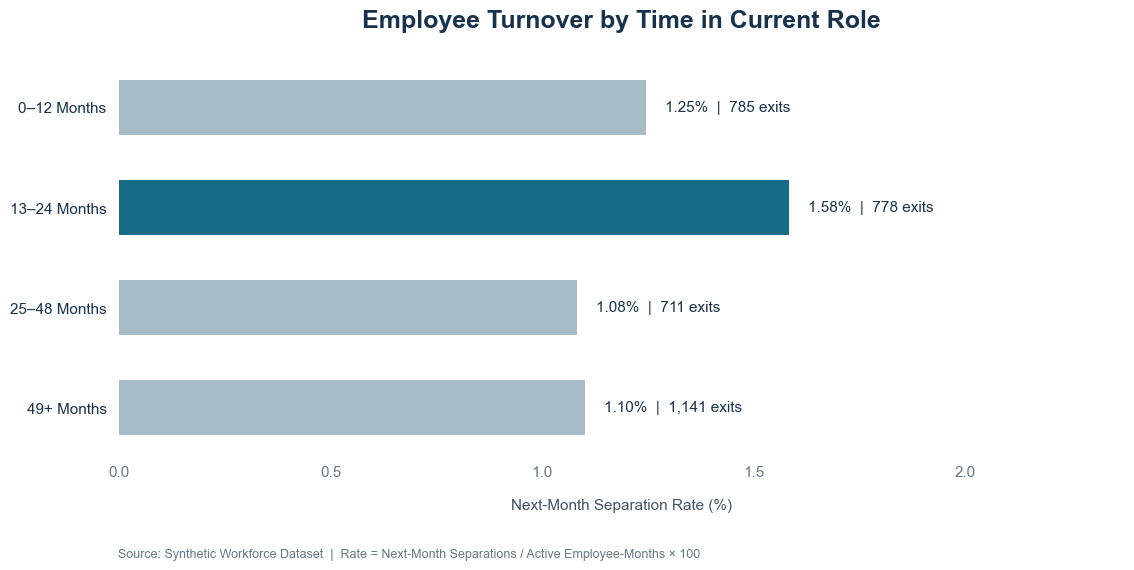

VISUALIZATION 07 — TURNOVER BY TIME IN CURRENT ROLE
Saved File: c:\Projects\Raymond-James\1. workforce_data\reports\images\07_turnover_by_role_tenure.png

              Employee_Months  Separations  Separation_Rate_Pct
role_segment                                                   
0–12 Months             63012          785               1.2458
13–24 Months            49147          778               1.5830
25–48 Months            65787          711               1.0808
49+ Months             103662         1141               1.1007

Highest Separation Rate Group: 13–24 Months
Highest Separation Rate: 1.583%


In [68]:

# =============================================================================
# VISUALIZATION 07 — TURNOVER BY TIME IN CURRENT ROLE
# Phase 5 | Step 62
# Next-Month Separation Rate by Role Tenure
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Configure the visualization output directory.
current_dir = Path.cwd()

project_root = (
    current_dir.parent.parent
    if current_dir.name.lower() == "notebooks"
    else current_dir
)

output_dir = project_root / "reports" / "images"
output_dir.mkdir(parents=True, exist_ok=True)

# 2. Use the validated pre-separation analytical population.
df = analysis_panel.copy()

# Define role-tenure categories consistent with Step 62.
role_labels = [
    "0–12 Months",
    "13–24 Months",
    "25–48 Months",
    "49+ Months"
]

df["role_segment"] = pd.cut(
    pd.to_numeric(
        df["role_tenure_months"],
        errors="coerce"
    ),
    bins=[-np.inf, 12, 24, 48, np.inf],
    labels=role_labels,
    include_lowest=True
)

# 3. Calculate next-month separation rates.
role_metrics = (
    df.groupby("role_segment", observed=True)
    .agg(
        Employee_Months=("employee_id", "size"),
        Separations=("exit_next_month", "sum")
    )
    .reindex(role_labels, fill_value=0)
)

role_metrics["Separation_Rate_Pct"] = np.where(
    role_metrics["Employee_Months"] > 0,
    role_metrics["Separations"] /
    role_metrics["Employee_Months"] * 100,
    np.nan
)

# 4. Prepare visualization data.
labels = role_metrics.index.astype(str).tolist()
rates = role_metrics["Separation_Rate_Pct"].to_numpy()
counts = role_metrics["Separations"].to_numpy()

highest_index = int(np.nanargmax(rates))

# 5. Create the horizontal bar chart.
fig, ax = plt.subplots(figsize=(11.5, 5.8))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# Highlight the group with the highest observed separation rate.
colors = [
    "#176B87" if i == highest_index else "#A8BBC8"
    for i in range(len(labels))
]

bars = ax.barh(
    labels,
    rates,
    height=0.55,
    color=colors,
    edgecolor="none"
)

# 6. Add separation rate and event-count labels.
for bar, rate, count in zip(bars, rates, counts):
    ax.text(
        bar.get_width() + 0.045,
        bar.get_y() + bar.get_height() / 2,
        f"{rate:.2f}%  |  {int(count):,} exits",
        ha="left",
        va="center",
        fontsize=11,
        color="#17324D"
    )

# 7. Apply clean, publication-ready styling.
ax.invert_yaxis()

ax.set_title(
    "Employee Turnover by Time in Current Role",
    fontsize=18,
    fontweight="bold",
    color="#17324D",
    pad=25
)

ax.set_xlabel(
    "Next-Month Separation Rate (%)",
    fontsize=11,
    color="#415466",
    labelpad=14
)

ax.set_xlim(0, np.nanmax(rates) * 1.5)

# Remove all gridlines and axis borders.
ax.grid(False)
ax.xaxis.grid(False, which="both")
ax.yaxis.grid(False, which="both")

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    which="both",
    length=0,
    labelsize=11,
    pad=9
)

ax.tick_params(axis="y", colors="#17324D")
ax.tick_params(axis="x", colors="#687782")

# 8. Add source and methodology notes.
fig.text(
    0.11,
    0.025,
    "Source: Synthetic Workforce Dataset  |  "
    "Rate = Next-Month Separations / Active Employee-Months × 100",
    fontsize=9,
    color="#687782"
)

plt.tight_layout(rect=[0, 0.07, 1, 1])

# 9. Export the visualization.
save_path = output_dir / "07_turnover_by_role_tenure.png"

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# 10. Print all results in one consolidated output.
print(
    "\n".join([
        "=" * 80,
        "VISUALIZATION 07 — TURNOVER BY TIME IN CURRENT ROLE",
        "=" * 80,
        f"Saved File: {save_path}",
        "",
        role_metrics.round(4).to_string(),
        "",
        f"Highest Separation Rate Group: {labels[highest_index]}",
        f"Highest Separation Rate: {rates[highest_index]:.3f}%",
        "=" * 80
    ])
)


In [69]:

# =============================================================================
# PHASE 5 — STEP 63
# TURNOVER & RETENTION ANALYSIS
# Statistical Association, Effect Sizes and Employee-Cluster Bootstrap
# =============================================================================

import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

output = []
output.append("=" * 85)
output.append("STEP 63 — STATISTICAL SIGNIFICANCE & EFFECT SIZE ANALYSIS")
output.append("=" * 85)

# 1. Reuse the validated pre-separation analytical population.
df = analysis_panel.copy()

output.append("\n1. ANALYTICAL POPULATION")
output.append(f"Employee-Month Observations: {len(df):,}")
output.append(f"Unique Employees: {df['employee_id'].nunique():,}")
output.append(f"Next-Month Separations: {df['exit_next_month'].sum():,}")

# 2. Define segmentation and comparison groups.
factor_specs = {
    "Compa-Ratio": (
        "compa_ratio",
        [-np.inf, 0.8, 0.9, 1.0, 1.1, np.inf],
        ["<0.80", "0.80–0.89", "0.90–0.99", "1.00–1.09", "1.10+"],
        "<0.80", "1.10+"
    ),
    "Performance Rating": (
        "latest_performance_rating",
        [-np.inf, 2, 3, 4, np.inf],
        ["Low (≤2)", "3", "4", "High (>4)"],
        "Low (≤2)", "High (>4)"
    ),
    "Time in Current Role": (
        "role_tenure_months",
        [-np.inf, 12, 24, 48, np.inf],
        ["0–12 Months", "13–24 Months", "25–48 Months", "49+ Months"],
        "13–24 Months", "25–48 Months"
    )
}

rng = np.random.default_rng(42)
bootstrap_iterations = 500

for factor_name, spec in factor_specs.items():

    column, bins, labels, reference_a, reference_b = spec

    output.append("\n" + "-" * 85)
    output.append(f"FACTOR: {factor_name.upper()}")
    output.append("-" * 85)

    if column not in df.columns:
        output.append("SKIPPED: Predictor unavailable.")
        continue

    values = pd.to_numeric(df[column], errors="coerce")

    groups = pd.cut(
        values, bins=bins, labels=labels, include_lowest=True
    ).astype("object").fillna("Missing")

    temp = pd.DataFrame({
        "employee_id": df["employee_id"].to_numpy(),
        "group": groups.to_numpy(),
        "exit": df["exit_next_month"].to_numpy()
    })

    # 3. Exploratory chi-square association test.
    contingency = pd.crosstab(temp["group"], temp["exit"])
    contingency = contingency.reindex(columns=[0, 1], fill_value=0)

    chi2, p_value, dof, expected = chi2_contingency(contingency)

    n = contingency.to_numpy().sum()
    cramer_v = np.sqrt(
        chi2 / (n * max(1, min(contingency.shape) - 1))
    )

    output.append("\nEXPLORATORY ASSOCIATION TEST")
    output.append(f"Chi-Square: {chi2:.4f}")
    output.append(f"Degrees of Freedom: {dof}")
    output.append(f"Naive P-Value: {p_value:.8g}")
    output.append(f"Cramer's V: {cramer_v:.4f}")
    output.append(
        f"Minimum Expected Cell Count: {expected.min():.2f}"
    )

    # 4. Calculate observed group separation rates.
    summary = temp.groupby("group").agg(
        Employee_Months=("exit", "size"),
        Separations=("exit", "sum")
    )

    summary["Rate_Pct"] = (
        summary["Separations"] /
        summary["Employee_Months"] * 100
    )

    output.append("\nOBSERVED SEPARATION RATES")
    output.append(summary.round(4).to_string())

    # 5. Aggregate per employee and comparison group.
    selected = temp[
        temp["group"].isin([reference_a, reference_b])
    ]

    cluster = (
        selected.groupby(["employee_id", "group"])
        .agg(events=("exit", "sum"), exposure=("exit", "size"))
        .reset_index()
    )

    employee_ids = pd.Index(cluster["employee_id"].unique())
    employee_index = pd.Series(
        np.arange(len(employee_ids)), index=employee_ids
    )

    cluster["idx"] = cluster["employee_id"].map(employee_index)

    arrays = {}

    for group_name in [reference_a, reference_b]:
        group_data = cluster[cluster["group"].eq(group_name)]

        event_array = np.zeros(len(employee_ids))
        exposure_array = np.zeros(len(employee_ids))

        indices = group_data["idx"].to_numpy(dtype=int)

        event_array[indices] = group_data["events"].to_numpy()
        exposure_array[indices] = group_data["exposure"].to_numpy()

        arrays[group_name] = (event_array, exposure_array)

    observed_a = (
        arrays[reference_a][0].sum() /
        arrays[reference_a][1].sum()
    )

    observed_b = (
        arrays[reference_b][0].sum() /
        arrays[reference_b][1].sum()
    )

    observed_difference = (observed_a - observed_b) * 100

    # 6. Employee-cluster bootstrap confidence interval.
    bootstrap_differences = []

    for _ in range(bootstrap_iterations):
        sampled_indices = rng.integers(
            0, len(employee_ids), size=len(employee_ids)
        )

        rates = []

        for group_name in [reference_a, reference_b]:
            event_array, exposure_array = arrays[group_name]

            denominator = exposure_array[sampled_indices].sum()

            rate = (
                event_array[sampled_indices].sum() / denominator
                if denominator > 0 else np.nan
            )

            rates.append(rate)

        bootstrap_differences.append(
            (rates[0] - rates[1]) * 100
        )

    ci_low, ci_high = np.nanpercentile(
        bootstrap_differences, [2.5, 97.5]
    )

    output.append("\nEMPLOYEE-CLUSTER BOOTSTRAP")
    output.append(f"Comparison: {reference_a} vs. {reference_b}")
    output.append(
        f"Observed Rate Difference: {observed_difference:.4f} pp"
    )
    output.append(
        f"95% Bootstrap CI: [{ci_low:.4f}, {ci_high:.4f}] pp"
    )
    output.append(
        f"Bootstrap Replications: {bootstrap_iterations:,}"
    )
    output.append(
        "CI excludes zero: "
        + str(bool(ci_low > 0 or ci_high < 0))
    )

output.append("\n5. INTERPRETATION NOTES")
output.append(
    "Chi-square p-values assume independent observations and are "
    "exploratory only for repeated employee-month records."
)
output.append(
    "Employee-cluster bootstrap resamples employees rather than "
    "individual months, preserving within-employee dependence."
)
output.append(
    "Statistical association does not establish causal effects."
)

output.append("\n" + "=" * 85)
output.append("STEP 63 STATISTICAL ANALYSIS COMPLETE")
output.append("=" * 85)

# Print all findings in one consolidated text output.
print("\n".join(output))


STEP 63 — STATISTICAL SIGNIFICANCE & EFFECT SIZE ANALYSIS

1. ANALYTICAL POPULATION
Employee-Month Observations: 281,608
Unique Employees: 8,244
Next-Month Separations: 3,415

-------------------------------------------------------------------------------------
FACTOR: COMPA-RATIO
-------------------------------------------------------------------------------------

EXPLORATORY ASSOCIATION TEST
Chi-Square: 61.7632
Degrees of Freedom: 4
Naive P-Value: 1.2354946e-12
Cramer's V: 0.0148
Minimum Expected Cell Count: 88.53

OBSERVED SEPARATION RATES
           Employee_Months  Separations  Rate_Pct
group                                            
0.80–0.89            48563          675    1.3899
0.90–0.99            84560         1116    1.3198
1.00–1.09            79888          923    1.1554
1.10+                61297          589    0.9609
<0.80                 7300          112    1.5342

EMPLOYEE-CLUSTER BOOTSTRAP
Comparison: <0.80 vs. 1.10+
Observed Rate Difference: 0.5734 pp
95% Boot

In [70]:

# =============================================================================
# PHASE 5 — STEP 64
# TURNOVER & RETENTION ANALYSIS
# Explicit Model Preparation, Categorization and Regression Execution
# =============================================================================

import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.metrics import roc_auc_score, brier_score_loss

output = []
output.append("=" * 90)
output.append("STEP 64 — ADJUSTED TURNOVER RISK ANALYSIS")
output.append("=" * 90)

# 1. Build the regression population explicitly from Step 62.
# The uploaded notebook previously referenced undefined regression_data
# and formula objects, which prevented a clean restart of the notebook.
# The duplicate promotion-timing source field is NOT used as a predictor.
required_predictors = [
    "employee_id", "month_date", "exit_next_month",
    "compa_ratio", "latest_performance_rating",
    "role_tenure_months", "organizational_tenure_months",
    "job_level", "department"
]
missing_predictors = [
    col for col in required_predictors if col not in analysis_panel.columns
]
if missing_predictors:
    raise ValueError(f"Missing Step 62 model inputs: {missing_predictors}")

regression_data = analysis_panel[required_predictors].copy()
regression_data["year"] = pd.to_datetime(
    regression_data["month_date"]
).dt.year

def segment_numeric(column, boundaries, labels):
    """Build mutually exclusive, labeled groups; preserve missing observations."""
    values = pd.to_numeric(regression_data[column], errors="coerce")
    grouped = pd.cut(
        values, bins=boundaries, labels=labels, include_lowest=True
    )
    return grouped.astype("object").where(grouped.notna(), "Missing").astype(str)

regression_data["compa_group"] = segment_numeric(
    "compa_ratio", [-np.inf, 0.80, 0.90, 1.00, 1.10, np.inf],
    ["Below 0.80", "0.80-0.89", "0.90-0.99", "1.00-1.09", "1.10+"]
)
regression_data["performance_group"] = segment_numeric(
    "latest_performance_rating", [-np.inf, 2, 3, 4, np.inf],
    ["Low", "3", "4", "High"]
)
regression_data["role_tenure_group"] = segment_numeric(
    "role_tenure_months", [-np.inf, 12, 24, 48, np.inf],
    ["0-12", "13-24", "25-48", "49+"]
)
regression_data["tenure_group_model"] = segment_numeric(
    "organizational_tenure_months", [-np.inf, 12, 36, 60, 120, np.inf],
    ["0-1", "1-3", "3-5", "5-10", "10+"]
)
regression_data["job_level_model"] = (
    regression_data["job_level"]
    .astype("object")
    .replace({"L6": "L6+", "L7": "L6+", "L8": "L6+"})
)
regression_data["department_model"] = regression_data["department"]

# Preserve the original model structure and reference categories. Only the
# redundant variable's business interpretation/name has been corrected.
formula = (
    'exit_next_month ~ '
    'C(compa_group, Treatment(reference="1.10+")) + '
    'C(performance_group, Treatment(reference="High")) + '
    'C(role_tenure_group, Treatment(reference="25-48")) + '
    'C(tenure_group_model, Treatment(reference="10+")) + '
    'C(job_level_model, Treatment(reference="L3")) + '
    'C(department_model) + C(year)'
)

# 2. Convert all categorical predictors to Patsy-compatible object types.
categorical_columns = [
    "compa_group",
    "performance_group",
    "role_tenure_group",
    "tenure_group_model",
    "job_level_model",
    "department_model"
]

for col in categorical_columns:
    regression_data[col] = (
        regression_data[col]
        .astype("object")
        .where(regression_data[col].notna(), "Missing")
        .astype(str)
    )

regression_data["employee_id"] = (
    regression_data["employee_id"].astype(str)
)

regression_data["year"] = (
    regression_data["year"].astype(int)
)

# 3. Verify predictor data types before model fitting.
output.append("\n1. MODEL DATA TYPE VALIDATION")
output.append(
    regression_data[
        categorical_columns + ["year", "exit_next_month"]
    ].dtypes.to_string()
)

output.append("\n2. MODEL POPULATION")
output.append(f"Observations: {len(regression_data):,}")
output.append(
    f"Unique Employees: {regression_data['employee_id'].nunique():,}"
)
output.append(
    f"Next-Month Separations: {regression_data['exit_next_month'].sum():,}"
)

# 4. Fit the multivariate binomial regression using current-role tenure.
model = smf.glm(
    formula=formula,
    data=regression_data,
    family=sm.families.Binomial()
)

result = model.fit(
    cov_type="cluster",
    cov_kwds={
        "groups": regression_data["employee_id"],
        "use_correction": True
    },
    maxiter=100
)

output.append("\n3. MODEL FIT")
output.append(f"Converged: {result.converged}")
output.append(f"Parameters: {len(result.params)}")
output.append(f"Log-Likelihood: {result.llf:.4f}")
output.append(f"AIC: {result.aic:.4f}")
output.append(f"Covariance Estimator: {result.cov_type}")

# 5. Calculate adjusted odds ratios and confidence intervals.
confidence = result.conf_int()

effects = pd.DataFrame({
    "Adjusted_OR": np.exp(result.params),
    "CI_Lower": np.exp(confidence.iloc[:, 0]),
    "CI_Upper": np.exp(confidence.iloc[:, 1]),
    "P_Value": result.pvalues
})

effects.index.name = "Predictor"

output.append("\n4. ADJUSTED ODDS RATIOS")
output.append(effects.round(5).to_string())

# 6. Extract statistically supported associations.
significant = effects.loc[
    (effects["P_Value"] < 0.05) &
    (effects.index != "Intercept")
].sort_values("Adjusted_OR", ascending=False)

output.append("\n5. ASSOCIATIONS WITH P < 0.05")

if significant.empty:
    output.append("No associations meet the nominal threshold.")
else:
    output.append(significant.round(5).to_string())

# 7. Assess in-sample model discrimination and probability accuracy.
probabilities = result.predict(regression_data)

output.append("\n6. IN-SAMPLE MODEL PERFORMANCE")
output.append(
    f"ROC-AUC: "
    f"{roc_auc_score(regression_data['exit_next_month'], probabilities):.4f}"
)
output.append(
    f"Brier Score: "
    f"{brier_score_loss(regression_data['exit_next_month'], probabilities):.5f}"
)
output.append(
    f"Average Predicted Risk: {probabilities.mean()*100:.4f}%"
)

output.append("\n7. METHODOLOGICAL NOTES")
output.append(
    "Role tenure replaces an exactly duplicated promotion-timing field. "
    "This model does not estimate an independent promotion-delay effect."
)
output.append(
    "Cluster-robust standard errors account for repeated observations "
    "within employees."
)
output.append(
    "Adjusted odds ratios represent associations, not causal effects."
)
output.append(
    "Performance metrics are in-sample and not temporally validated."
)
output.append(
    "Nominal p-values are not adjusted for multiple comparisons."
)

output.append("\n" + "=" * 90)
output.append("STEP 64 CORRECTED REGRESSION COMPLETE")
output.append("=" * 90)

# Print all analytical results in one consolidated output.
print("\n".join(output))


STEP 64 — ADJUSTED TURNOVER RISK ANALYSIS

1. MODEL DATA TYPE VALIDATION
compa_group           object
performance_group     object
role_tenure_group     object
tenure_group_model    object
job_level_model       object
department_model      object
year                   int64
exit_next_month        int64

2. MODEL POPULATION
Observations: 281,608
Unique Employees: 8,244
Next-Month Separations: 3,415

3. MODEL FIT
Converged: True
Parameters: 32
Log-Likelihood: -18099.5743
AIC: 36263.1485
Covariance Estimator: cluster

4. ADJUSTED ODDS RATIOS
                                                              Adjusted_OR  CI_Lower  CI_Upper  P_Value
Predictor                                                                                             
Intercept                                                         0.00411   0.00304   0.00557  0.00000
C(compa_group, Treatment(reference="1.10+"))[T.0.80-0.89]         1.23620   1.09296   1.39822  0.00074
C(compa_group, Treatment(reference="1.10+"

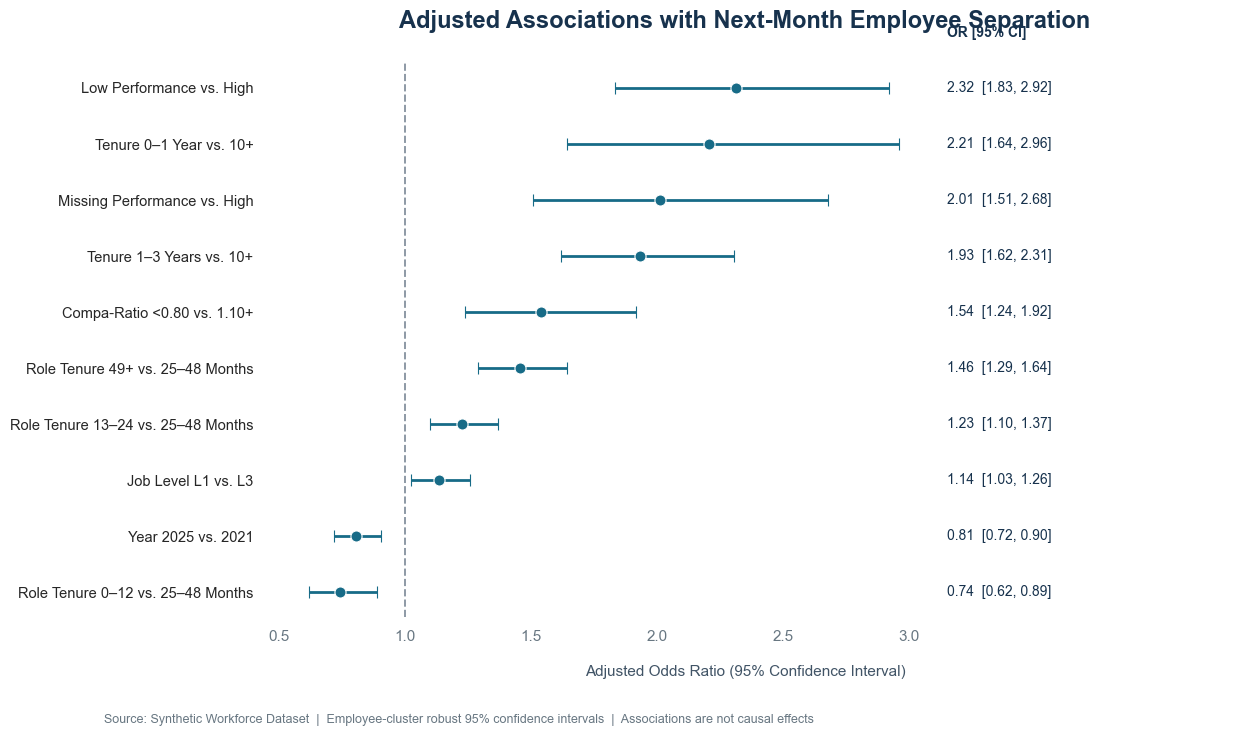

VISUALIZATION 08 — ADJUSTED TURNOVER ODDS RATIOS
Saved File: c:\Projects\Raymond-James\1. workforce_data\reports\images\08_adjusted_turnover_odds_ratios.png

                             Label  Adjusted_OR  CI_Lower  CI_Upper  P_Value
 Role Tenure 0–12 vs. 25–48 Months       0.7433    0.6208    0.8898   0.0012
                Year 2025 vs. 2021       0.8078    0.7212    0.9048   0.0002
               Job Level L1 vs. L3       1.1367    1.0270    1.2582   0.0134
Role Tenure 13–24 vs. 25–48 Months       1.2280    1.0995    1.3716   0.0003
  Role Tenure 49+ vs. 25–48 Months       1.4559    1.2907    1.6422   0.0000
       Compa-Ratio <0.80 vs. 1.10+       1.5418    1.2401    1.9169   0.0001
          Tenure 1–3 Years vs. 10+       1.9328    1.6206    2.3050   0.0000
      Missing Performance vs. High       2.0110    1.5101    2.6779   0.0000
           Tenure 0–1 Year vs. 10+       2.2058    1.6423    2.9625   0.0000
          Low Performance vs. High       2.3153    1.8342    2.9227   0.

In [71]:

# =============================================================================
# VISUALIZATION 08 — ADJUSTED TURNOVER ODDS RATIOS
# Phase 5 | Step 64
# Multivariate Logistic Regression with 95% Confidence Intervals
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Configure the report visualization directory.
current_dir = Path.cwd()

project_root = (
    current_dir.parent.parent
    if current_dir.name.lower() == "notebooks"
    else current_dir
)

output_dir = project_root / "reports" / "images"
output_dir.mkdir(parents=True, exist_ok=True)

# 2. Validate the regression results from Step 64.
required_columns = [
    "Adjusted_OR",
    "CI_Lower",
    "CI_Upper",
    "P_Value"
]

if "effects" not in globals():
    raise ValueError("Run Step 64 before creating this visualization.")

missing = [c for c in required_columns if c not in effects.columns]

if missing:
    raise ValueError(f"Missing regression result columns: {missing}")

# 3. Define selected business-relevant regression contrasts.
# Labels explicitly identify the reference category.
selected_predictors = {
    'C(performance_group, Treatment(reference="High"))[T.Low]':
        "Low Performance vs. High",
    'C(performance_group, Treatment(reference="High"))[T.Missing]':
        "Missing Performance vs. High",
    'C(tenure_group_model, Treatment(reference="10+"))[T.0-1]':
        "Tenure 0–1 Year vs. 10+",
    'C(tenure_group_model, Treatment(reference="10+"))[T.1-3]':
        "Tenure 1–3 Years vs. 10+",
    'C(compa_group, Treatment(reference="1.10+"))[T.Below 0.80]':
        "Compa-Ratio <0.80 vs. 1.10+",
    'C(role_tenure_group, Treatment(reference="25-48"))[T.49+]':
        "Role Tenure 49+ vs. 25–48 Months",
    'C(role_tenure_group, Treatment(reference="25-48"))[T.13-24]':
        "Role Tenure 13–24 vs. 25–48 Months",
    'C(role_tenure_group, Treatment(reference="25-48"))[T.0-12]':
        "Role Tenure 0–12 vs. 25–48 Months",
    'C(job_level_model, Treatment(reference="L3"))[T.L1]':
        "Job Level L1 vs. L3",
    'C(year)[T.2025]':
        "Year 2025 vs. 2021"
}

# Extract actual model estimates without hardcoding numerical results.
available = [
    predictor for predictor in selected_predictors
    if predictor in effects.index
]

if not available:
    raise ValueError("No selected regression predictors were found.")

plot_data = effects.loc[available, required_columns].copy()

plot_data["Label"] = [
    selected_predictors[p] for p in available
]

plot_data = (
    plot_data
    .sort_values("Adjusted_OR", ascending=True)
    .reset_index(drop=True)
)

# 4. Prepare odds ratios and asymmetric confidence intervals.
odds = plot_data["Adjusted_OR"].to_numpy(dtype=float)
lower = plot_data["CI_Lower"].to_numpy(dtype=float)
upper = plot_data["CI_Upper"].to_numpy(dtype=float)

errors = np.vstack([
    odds - lower,
    upper - odds
])

y_positions = np.arange(len(plot_data))

# 5. Create a publication-ready forest plot.
fig, ax = plt.subplots(figsize=(12.5, 7.5))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# Color contrasts according to whether the 95% CI excludes 1.
colors = [
    "#176B87" if (lo > 1 or hi < 1) else "#A8BBC8"
    for lo, hi in zip(lower, upper)
]

for i, (estimate, error_low, error_high) in enumerate(
    zip(odds, errors[0], errors[1])
):
    ax.errorbar(
        estimate,
        i,
        xerr=np.array([[error_low], [error_high]]),
        fmt="o",
        markersize=8,
        capsize=4,
        elinewidth=2,
        capthick=1.6,
        color=colors[i],
        ecolor=colors[i],
        markeredgecolor="white",
        markeredgewidth=0.8,
        zorder=3
    )

# The OR = 1 reference line indicates no difference in odds.
ax.axvline(
    1.0,
    color="#8D99A5",
    linewidth=1.4,
    linestyle="--",
    zorder=1
)

# 6. Add effect-size and confidence-interval labels.
for i, (estimate, lo, hi) in enumerate(zip(odds, lower, upper)):
    ax.text(
        3.15,
        i,
        f"{estimate:.2f}  [{lo:.2f}, {hi:.2f}]",
        va="center",
        ha="left",
        fontsize=10,
        color="#17324D"
    )

# 7. Apply clean statistical-report styling.
ax.set_yticks(y_positions)
ax.set_yticklabels(plot_data["Label"], fontsize=10.5)

ax.set_xlim(0.45, 4.25)

ax.set_xticks([0.5, 1.0, 1.5, 2.0, 2.5, 3.0])

ax.set_xlabel(
    "Adjusted Odds Ratio (95% Confidence Interval)",
    fontsize=11,
    color="#415466",
    labelpad=15
)

ax.set_title(
    "Adjusted Associations with Next-Month Employee Separation",
    fontsize=17,
    fontweight="bold",
    color="#17324D",
    pad=25
)

# Remove decorative gridlines and borders.
ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    which="both",
    length=0,
    pad=9
)

ax.tick_params(axis="x", colors="#687782")

# Add a column heading for numerical estimates.
ax.text(
    3.15,
    len(plot_data) - 0.15,
    "OR [95% CI]",
    fontsize=10,
    fontweight="bold",
    color="#17324D",
    va="bottom"
)

# 8. Add a methodological footnote.
fig.text(
    0.09,
    0.025,
    "Source: Synthetic Workforce Dataset  |  "
    "Employee-cluster robust 95% confidence intervals  |  "
    "Associations are not causal effects",
    fontsize=9,
    color="#687782"
)

plt.tight_layout(rect=[0, 0.06, 1, 1])

# 9. Save the figure.
save_path = output_dir / "08_adjusted_turnover_odds_ratios.png"

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# 10. Print all plotted estimates in one consolidated output.
print(
    "\n".join([
        "=" * 85,
        "VISUALIZATION 08 — ADJUSTED TURNOVER ODDS RATIOS",
        "=" * 85,
        f"Saved File: {save_path}",
        "",
        plot_data[
            ["Label", "Adjusted_OR", "CI_Lower", "CI_Upper", "P_Value"]
        ].round(4).to_string(index=False),
        "",
        "Reference Line: OR = 1.0",
        "Intervals: Employee-cluster robust 95% confidence intervals",
        "Interpretation: Adjusted associations, not causal effects",
        "=" * 85
    ])
)


In [72]:

# =============================================================================
# PHASE 5 — STEP 65
# WORKFORCE ANALYTICS — FINAL STATISTICAL VALIDATION
# Turnover Reconciliation, Model Diagnostics and Key Findings
# =============================================================================

import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score, brier_score_loss

output = []
output.append("=" * 90)
output.append("STEP 65 — FINAL VALIDATION & ANALYTICAL FINDINGS")
output.append("=" * 90)

# 1. Reconcile employee separation records.
panel = df_analysis.copy()
panel["month_date"] = pd.to_datetime(panel["month_date"])

terminated_ids = set(
    panel.loc[
        panel["employment_status"].eq("Terminated"),
        "employee_id"
    ].astype(str).str.strip()
)

latest_terminated_ids = set(
    latest_employee_records.loc[
        latest_employee_records["employment_status"].eq("Terminated"),
        "employee_id"
    ].astype(str).str.strip()
)

source_ids = set(
    separation_history["Employee_ID"].astype(str).str.strip()
)

output.append("\n1. SEPARATION SOURCE RECONCILIATION")
output.append(f"Monthly Panel Terminated Employees: {len(terminated_ids):,}")
output.append(f"Final Status Terminated Employees: {len(latest_terminated_ids):,}")
output.append(f"Separation History Employees: {len(source_ids):,}")
output.append(
    f"Panel vs Final Status Difference: "
    f"{len(terminated_ids.symmetric_difference(latest_terminated_ids)):,}"
)
output.append(
    f"History IDs Outside Validated Cohort: "
    f"{len(source_ids - terminated_ids):,}"
)
output.append(
    f"Validated Terminations Missing from History: "
    f"{len(terminated_ids - source_ids):,}"
)

# 2. Reconcile the December 2025 active population.
last_month = panel["month_date"].max()

december_active = set(
    panel.loc[
        panel["month_date"].eq(last_month)
        & panel["employment_status"].eq("Active"),
        "employee_id"
    ].astype(str).str.strip()
)

final_active = set(
    latest_employee_records.loc[
        latest_employee_records["employment_status"].eq("Active"),
        "employee_id"
    ].astype(str).str.strip()
)

output.append("\n2. FINAL ACTIVE HEADCOUNT DISCREPANCY")
output.append(f"Last Observed Month: {last_month:%Y-%m}")
output.append(f"Monthly Snapshot Active Employees: {len(december_active):,}")
output.append(f"Final Status Active Employees: {len(final_active):,}")
output.append(
    f"Final Active Missing from December Active: "
    f"{len(final_active - december_active):,}"
)
output.append(
    f"December Active Missing from Final Active: "
    f"{len(december_active - final_active):,}"
)

# Examine status records for employees absent from December active count.
missing_december = final_active - december_active

discrepancy_records = panel[
    panel["employee_id"].astype(str).str.strip().isin(missing_december)
].copy()

if not discrepancy_records.empty:
    last_observations = (
        discrepancy_records
        .sort_values("month_date")
        .groupby("employee_id")
        .tail(1)
    )

    output.append("\nLAST OBSERVED MONTH OF DISCREPANT EMPLOYEES")
    output.append(
        last_observations["month_date"]
        .dt.to_period("M")
        .value_counts()
        .sort_index()
        .to_string()
    )

# 3. Validate turnover modeling population.
output.append("\n3. TURNOVER MODEL POPULATION")
output.append(f"Employee-Month Observations: {len(regression_data):,}")
output.append(
    f"Unique Employees: {regression_data['employee_id'].nunique():,}"
)
output.append(
    f"Observed Next-Month Separations: "
    f"{regression_data['exit_next_month'].sum():,}"
)

# 4. Compare fitted model with a constant-probability baseline.
actual = regression_data["exit_next_month"].astype(int)
predicted = np.asarray(result.predict(regression_data))

baseline_probability = actual.mean()
baseline_predictions = np.full(len(actual), baseline_probability)

model_brier = brier_score_loss(actual, predicted)
baseline_brier = brier_score_loss(actual, baseline_predictions)

output.append("\n4. MODEL PERFORMANCE VS BASELINE")
output.append(f"Observed Event Rate: {baseline_probability:.6f}")
output.append(f"In-Sample ROC-AUC: {roc_auc_score(actual, predicted):.4f}")
output.append(f"Model Brier Score: {model_brier:.6f}")
output.append(f"Baseline Brier Score: {baseline_brier:.6f}")
output.append(
    f"Relative Brier Improvement: "
    f"{(1 - model_brier / baseline_brier) * 100:.2f}%"
)
output.append(f"Regression Converged: {result.converged}")

# 5. Summarize selected adjusted associations.
key_terms = {
    "Low Performance": "performance_group",
    "Compensation Position": "compa_group",
    "Time in Current Role": "role_tenure_group",
    "Organizational Tenure": "tenure_group_model",
    "Job Level": "job_level_model",
    "Calendar Year": "C(year)"
}

output.append("\n5. KEY ADJUSTED ASSOCIATIONS")

for label, term in key_terms.items():
    selected = effects[
        effects.index.to_series().str.contains(
            term, regex=False
        )
    ].copy()

    selected = selected.sort_values(
        "Adjusted_OR", ascending=False
    )

    output.append(f"\n{label.upper()}")

    if selected.empty:
        output.append("No matching terms.")
    else:
        output.append(selected.round(4).to_string())

# 6. Summarize annual turnover trends.
output.append("\n6. ANNUAL TURNOVER SUMMARY")
output.append(
    annual[
        [
            "annual_separations",
            "average_active_headcount",
            "annual_turnover_rate_pct"
        ]
    ].round(3).to_string()
)

# 7. Register analytical limitations.
output.append("\n7. FINAL ANALYTICAL LIMITATIONS")

limitations = [
    "This project uses synthetic workforce data for independent analytical research and portfolio demonstration.",
    "Observed relationships are statistical associations, not causal effects.",
    "Monthly repeated observations require employee-level dependence controls.",
    "Turnover regression performance was evaluated in-sample only.",
    "Missing performance ratings require separate operational interpretation.",
    "Months-since-promotion duplicates role tenure in all observed monthly records; it was excluded from final predictor selection.",
    "Role-tenure associations must not be described as independent promotion-delay effects.",
    "Historical separation records outside the validated cohort require documentation.",
    "The final active headcount discrepancy requires source-level resolution.",
    "Multiple predictor comparisons were not corrected for multiplicity.",
    "Turnover estimates depend on monthly snapshot and exposure definitions."
]

for number, limitation in enumerate(limitations, 1):
    output.append(f"{number}. {limitation}")

output.append("\n" + "=" * 90)
output.append("STEP 65 — FINAL VALIDATION COMPLETE")
output.append("=" * 90)

# Print all validation results in one consolidated output.
print("\n".join(output))


STEP 65 — FINAL VALIDATION & ANALYTICAL FINDINGS

1. SEPARATION SOURCE RECONCILIATION
Monthly Panel Terminated Employees: 3,539
Final Status Terminated Employees: 3,539
Separation History Employees: 3,580
Panel vs Final Status Difference: 0
History IDs Outside Validated Cohort: 41
Validated Terminations Missing from History: 0

2. FINAL ACTIVE HEADCOUNT DISCREPANCY
Last Observed Month: 2025-12
Monthly Snapshot Active Employees: 4,867
Final Status Active Employees: 4,891
Final Active Missing from December Active: 24
December Active Missing from Final Active: 0

LAST OBSERVED MONTH OF DISCREPANT EMPLOYEES
month_date
2025-08     1
2025-09     7
2025-10     4
2025-11    12
Freq: M

3. TURNOVER MODEL POPULATION
Employee-Month Observations: 281,608
Unique Employees: 8,244
Observed Next-Month Separations: 3,415

4. MODEL PERFORMANCE VS BASELINE
Observed Event Rate: 0.012127
In-Sample ROC-AUC: 0.6318
Model Brier Score: 0.011948
Baseline Brier Score: 0.011980
Relative Brier Improvement: 0.27%
R